In [37]:

# icml_llm_routing_experiments.py
#
# Complete experiment suite for:
# "Online Algorithm for Personalised LLM Routing"
#
# IMPORTANT EXPERIMENT PROTOCOL
# -----------------------------
# 1. T is fixed at 1000 for every experiment.
# 2. eta, rho, and alpha_scale are selected ONCE on the main validation setting:
#       epsilon=0.20, delta=0.05
#    and then frozen for every epsilon/delta/personalization/robustness experiment.
# 3. alpha_t is still time-dependent through the theoretical alpha_t expression,
#    but its multiplicative calibration alpha_scale is fixed globally.
# 4. rho is a fixed scalar; it is NOT recomputed from epsilon, delta, or T.
# 5. The learned-model UCB is intentionally UNCLIPPED, as in the user's latest setup.
# 6. Fallback UCB is fixed at 50.
#
# Main environment:
#   d=8, K=5, costs=[0.10,0.25,0.40,0.60,0.80], fallback cost=1.0
#   L=3, S=1, beta=1, zeta=2.5, xi=0.35
#
# The validation sweep chooses eta/rho/alpha_scale by:
#   - first preferring configurations whose empirical chance-constraint
#     satisfaction is >= 1-delta;
#   - among feasible configurations, minimizing average cost;
#   - if none is feasible, maximizing feasibility and then minimizing cost.
#
# The theoretical rho_max_star(T, epsilon, delta) is computed exactly
# from the Binomial quantile definition for REPORTING ONLY. The actual
# algorithm uses the frozen rho selected by validation.
#
# Dependencies:
#   numpy, scipy, pandas, matplotlib
#
# Run:
#   python icml_llm_routing_experiments.py --quick-test   # fast sanity check
#   python icml_llm_routing_experiments.py                # full suite
#
# Outputs:
#   ./icml_llm_routing_results/
#       frozen_hyperparameters.json
#       main_performance.csv
#       chance_constraint.csv
#       epsilon_sweep.csv
#       delta_sweep.csv
#       personalization.csv
#       ablation.csv
#       robustness.csv
#       regret_scaling.csv
#       confidence_calibration.csv
#       *.png

import argparse
import json
import math
import os
from dataclasses import dataclass, replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit
from scipy.optimize import brentq
from scipy.stats import binom
from scipy.optimize import linprog

# ============================================================
# 0. GLOBAL CONFIGURATION
# ============================================================

SEED = 20261005
OUT = Path("icml_llm_routing_results")
OUT.mkdir(exist_ok=True)

# Fixed horizon for ALL experiments.
T = 1000

# Main constraint used ONLY for hyperparameter selection.
MAIN_EPSILON = 0.20
MAIN_DELTA = 0.05

# Main model/environment constants.
D = 8
K = 5
COSTS = np.array([0.10, 0.25, 0.40, 0.60, 0.80], dtype=float)
FALLBACK = K
FALLBACK_COST = 1.0

L = 3.0
S = 1.0
BETA = 1.0
ZETA = 2.5
XI = 0.35

# Each model owns a different maximum feature magnitude.  Every
# context for model a satisfies ||x_{a,t}|| <= MODEL_MAX_RADIUS[a],
# with all maxima in [1, 1.5].
MODEL_MAX_RADIUS = np.linspace(1.05, 1.50, K)

# Contexts for each model lie in a spherical cap around that model's
# direction rather than covering the entire unit sphere.
MODEL_CAP_ANGLE_DEG = 30.0

# Fallback UCB is deliberately very large so fallback is chosen
# only when the dual queue makes it worthwhile.
FALLBACK_UCB = 1.0

# ------------------------------------------------------------
# Runtime mode.
#
# Default: full paper experiment suite.
# Quick test: python icml_llm_routing_experiments.py --quick-test
#
# Quick mode intentionally runs the SAME code paths, but with a
# tiny horizon/trial count so we can catch implementation errors
# before launching the expensive experiment suite.
# ------------------------------------------------------------

QUICK_TEST = True

# Trial counts. Increase for final paper tables if runtime permits.
if QUICK_TEST:
    T = 100
    N_VALIDATION = 100
    N_MAIN = 100
    N_CHANCE = 100
    N_EPS = 100
    N_DELTA = 100
    N_PERSONALIZATION = 100
    N_ABLATION = 100
    N_ROBUSTNESS = 100
    N_REGRET = 100
    N_CALIBRATION = 100

    # A small sweep is enough to verify the validation logic.
    ETA_GRID = [
    0.50
    ]
    RHO_GRID = [0.15]
    ALPHA_SCALE_GRID =  [0.005]
else:
    T = 1000
    N_VALIDATION = 30
    N_MAIN = 100
    N_CHANCE = 1000
    N_EPS = 200
    N_DELTA = 200
    N_PERSONALIZATION = 100
    N_ABLATION = 200
    N_ROBUSTNESS = 100
    N_REGRET = 100
    N_CALIBRATION = 100

# We do NOT use 1/kappa=22.13 in the empirical alpha calibration.
# alpha_scale is swept empirically. The raw theoretical formula can be
# evaluated with kappa=0.04518 for reporting.
LOGISTIC_KAPPA_L3 = expit(3.0) * (1.0 - expit(3.0))

# ------------------------------------------------------------
# Candidate sweep.
# These are deliberately modest queue steps; the previous
# C_eta/sqrt(T) with C_eta=100 gives eta=3.16 at T=1000,
# which is unnecessarily aggressive for a finite-T experiment.
#
# In quick-test mode the smaller grids above are used.
# ------------------------------------------------------------
if not QUICK_TEST:
    ETA_GRID = [0.02, 0.05, 0.10, 0.20, 0.30]
    RHO_GRID = [0.001, 0.0025, 0.005, 0.0075, 0.010]
    ALPHA_SCALE_GRID = [0.001, 0.005, 0.01, 0.02, 0.025, 0.05, 0.075, 0.10, 0.15, 0.20]

# ============================================================
# 1. EXACT rho_max_star FROM THE PAPER
# ============================================================

def rho_max_star(T, epsilon, delta):
    """
    Exact definition:
        q = 1-epsilon
        m_T = ceil(T q)
        find mu in (0,1) such that
            P(Binomial(T,mu) >= m_T) = 1-delta
        rho_max = mu-q

    This is for theoretical reporting/diagnostics.
    It is NOT used to recompute rho in experiments.
    """
    q = 1.0 - epsilon
    m = int(math.ceil(T * q))

    def f(mu):
        # P(S >= m) = 1 - P(S <= m-1)
        return binom.sf(m - 1, T, mu) - (1.0 - delta)

    lo, hi = 1e-12, 1.0 - 1e-12

    # Numerical safety for edge cases.
    if f(lo) >= 0:
        mu = lo
    elif f(hi) <= 0:
        mu = hi
    else:
        mu = brentq(f, lo, hi, xtol=1e-12, rtol=1e-12)

    return max(0.0, mu - q)


# ============================================================
# 2. CONTEXT / USER GENERATION
# ============================================================

def unit(v):
    n = np.linalg.norm(v)
    return v / max(n, 1e-12)


def make_user_directions(rng, n_users=1):
    return np.array([unit(rng.normal(size=D)) for _ in range(n_users)])


def make_model_directions(rng):
    return np.array([unit(rng.normal(size=D)) for _ in range(K)])


def sample_spherical_cap(rng, center, max_angle_deg):
    """Sample a unit vector inside a spherical cap around ``center``."""
    center = unit(center)

    # Draw an isotropic direction in the tangent space of center.
    tangent = rng.normal(size=D)
    tangent -= np.dot(tangent, center) * center
    tangent = unit(tangent)

    # Uniform in solid angle within the cap: cos(theta) is uniform.
    max_angle = np.deg2rad(max_angle_deg)
    cos_theta = rng.uniform(np.cos(max_angle), 1.0)
    sin_theta = np.sqrt(max(0.0, 1.0 - cos_theta**2))
    return unit(cos_theta * center + sin_theta * tangent)


def generate_contexts(
    rng,
    theta_star,
    model_dirs,
    xi=XI,
    user_dir=None,
    shared_mode=False,
    T_override=None,
):
    """
    Returns x[t,a] with shape (T_run, K, D).

    For each model a:
      * all contexts lie in a spherical cap centered at model_dirs[a],
        so the model does NOT cover the entire unit sphere;
      * model a has its own maximum norm MODEL_MAX_RADIUS[a] in [1, 1.5];
      * different model directions can have different dot products with
        theta_star, creating genuinely different model/context quality.

    The norm is sampled in [0.85 * max_radius[a], max_radius[a]], so
    models also differ in the scale of their feature vectors.

    T_override:
      If supplied, generate exactly T_override rounds. Otherwise use
      the global T.
    """

    T_run = T if T_override is None else int(T_override)

    if T_run <= 0:
        raise ValueError(
            f"T_override must be positive, got {T_run}"
        )

    X = np.zeros((T_run, K, D))

    for t in range(T_run):

        if shared_mode:
            z = rng.normal(size=D)

            if user_dir is not None:
                z = 0.7 * z + 0.3 * user_dir

            z = unit(z)

        for a in range(K):

            if shared_mode:
                # Shared variation, but still constrained to
                # model a's spherical cap.
                cap_center = unit(
                    (1.0 - xi) * model_dirs[a]
                    + xi * z
                )

            else:
                z_a = rng.normal(size=D)

                if user_dir is not None:
                    z_a = 0.7 * z_a + 0.3 * user_dir

                z_a = unit(z_a)

                cap_center = unit(
                    (1.0 - xi) * model_dirs[a]
                    + xi * z_a
                )

            # Keep each model's contexts inside its bounded
            # spherical region.
            direction = sample_spherical_cap(
                rng,
                cap_center,
                MODEL_CAP_ANGLE_DEG,
            )

            # Model-specific feature-vector magnitude.
            radius = rng.uniform(
                0.85 * MODEL_MAX_RADIUS[a],
                MODEL_MAX_RADIUS[a],
            )

            X[t, a] = radius * direction

    return X

# ============================================================
# 3. LOGISTIC GLM FIT
# ============================================================

def logistic_mle(X, y, beta=BETA, max_iter=25):
    """
    Newton solver for:
        sum log Bernoulli(sigmoid(x^T theta))
        - beta/2 ||theta||^2

    We use the same regularized GLM structure for all experiments.
    """
    if len(y) == 0:
        return np.zeros(D)

    theta = np.zeros(D)

    for _ in range(max_iter):
        z = X @ theta
        p = expit(np.clip(z, -30, 30))
        w = np.maximum(p * (1.0 - p), 1e-6)

        grad = X.T @ (y - p) - beta * theta
        H = (X.T * w) @ X + beta * np.eye(D)

        try:
            step = np.linalg.solve(H, grad)
        except np.linalg.LinAlgError:
            step = np.linalg.pinv(H) @ grad

        # Backtracking keeps Newton stable on nearly separable data.
        step_scale = 1.0
        old_obj = (
            np.sum(y * np.log(np.maximum(p, 1e-12))
                   + (1-y) * np.log(np.maximum(1-p, 1e-12)))
            - 0.5 * beta * np.dot(theta, theta)
        )

        accepted = False
        for _bt in range(12):
            cand = theta + step_scale * step
            pc = expit(np.clip(X @ cand, -30, 30))
            obj = (
                np.sum(y * np.log(np.maximum(pc, 1e-12))
                       + (1-y) * np.log(np.maximum(1-pc, 1e-12)))
                - 0.5 * beta * np.dot(cand, cand)
            )
            if obj >= old_obj:
                theta = cand
                accepted = True
                break
            step_scale *= 0.5

        if not accepted:
            theta = theta + 0.05 * step

        if np.linalg.norm(step) * step_scale < 1e-7:
            break

    return theta


def theoretical_alpha(t, kappa=LOGISTIC_KAPPA_L3):
    """
    The paper's theoretical alpha_t:
        1/kappa * [
          1/2 sqrt(d log(1+tL^2/(d beta)) + 2 log(2/delta_E))
          + sqrt(beta) S
        ]
    """
    t = max(int(t), 1)
    delta_E = t ** (-ZETA)

    inside = (
        D * math.log(1.0 + t * L**2 / (D * BETA))
        + 2.0 * math.log(2.0 / delta_E)
    )

    return (
        0.5 * math.sqrt(inside) + math.sqrt(BETA) * S
    ) / kappa


def empirical_alpha(t, alpha_scale):
    """
    Fixed global alpha calibration:
        alpha_t = alpha_scale * alpha_theory_t.

    The alpha_scale is selected once and then frozen for every experiment.
    """
    return alpha_scale * theoretical_alpha(t)


# ============================================================
# 4. ONE TRIAL
# ============================================================

@dataclass
class TrialConfig:
    epsilon: float = MAIN_EPSILON
    delta: float = MAIN_DELTA
    eta: float = 0.10
    rho: float = 0.005
    alpha_scale: float = 0.10

    # Ablations.
    use_ucb: bool = True
    use_queue: bool = True
    use_rho: bool = True

    # Context/user.
    xi: float = XI
    shared_mode: bool = False


def run_trial(
    seed,
    cfg,
    theta_star,
    model_dirs,
    user_dir=None,
    return_trace=False,
    T_override=None,
):
    rng = np.random.default_rng(seed)

    if theta_star is None:
        theta_star = unit(rng.normal(size=D)) * S

    if model_dirs is None:
        model_dirs = make_model_directions(rng)

    # Horizon used by this trial.
    T_run = T if T_override is None else T_override

    # Generate contexts for the requested horizon.
    X = generate_contexts(
        rng,
        theta_star,
        model_dirs,
        xi=cfg.xi,
        user_dir=user_dir,
        shared_mode=cfg.shared_mode,
        T_override=T_run,
    )

    # Sanity check: context generator must actually return
    # the requested number of rounds.
    if X.shape[0] != T_run:
        raise ValueError(
            f"generate_contexts returned T={X.shape[0]} contexts, "
            f"but T_run={T_run} was requested."
        )

    # True probabilities.
    P = expit(np.einsum("tkd,d->tk", X, theta_star))

    V = BETA * np.eye(D)
    theta_hat = np.zeros(D)

    selected_x = []
    selected_y = []

    lam = 0.0

    actions = np.zeros(T_run, dtype=int)
    outcomes = np.zeros(T_run, dtype=int)
    predicted = np.zeros(T_run)
    widths = np.zeros(T_run)
    lambdas = np.zeros(T_run)
    costs = np.zeros(T_run)
    fallbacks = np.zeros(T_run, dtype=int)
    true_p_selected = np.zeros(T_run)

    for t in range(T_run):

        # ---------------------------------------------------------------
        # Refit using all selected learned-model observations.
        # ---------------------------------------------------------------
        if len(selected_y) > 0:
            XX = np.asarray(selected_x)
            yy = np.asarray(selected_y)
            theta_hat = logistic_mle(XX, yy)

        try:
            Vinv = np.linalg.inv(V)
        except np.linalg.LinAlgError:
            Vinv = np.linalg.pinv(V)

        alpha = empirical_alpha(
            t + 1,
            cfg.alpha_scale,
        )

        scores = np.empty(K + 1)

        # ---------------------------------------------------------------
        # Learned models.
        # ---------------------------------------------------------------
        for a in range(K):

            x = X[t, a]

            mean = float(
                expit(
                    np.dot(x, theta_hat)
                )
            )

            norm = math.sqrt(
                max(
                    0.0,
                    np.dot(
                        x,
                        Vinv @ x
                    )
                )
            )

            width = alpha * norm

            # Intentionally unclipped, as in the current experiment setup.
            ucb = mean + width

            scores[a] = COSTS[a] - (
                lam if cfg.use_queue else 1.0
            ) * (
                ucb if cfg.use_ucb else mean
            )

        # ---------------------------------------------------------------
        # Perfect fallback.
        #
        # Fallback satisfaction is exactly 1, so its UCB is exactly 1.
        # ---------------------------------------------------------------
        fallback_score = FALLBACK_COST - (
            lam if cfg.use_queue else 1.0
        ) * FALLBACK_UCB

        scores[FALLBACK] = fallback_score

        # Select minimum cost-adjusted score.
        a = int(np.argmin(scores))

        # ---------------------------------------------------------------
        # Observe outcome.
        # ---------------------------------------------------------------
        if a == FALLBACK:

            y = 1
            p = 1.0

            costs[t] = FALLBACK_COST
            fallbacks[t] = 1

            predicted[t] = 1.0
            widths[t] = 0.0

        else:

            p = P[t, a]

            y = int(
                rng.random() < p
            )

            costs[t] = COSTS[a]

            predicted[t] = float(
                expit(
                    np.dot(
                        X[t, a],
                        theta_hat
                    )
                )
            )

            try:
                width = alpha * math.sqrt(
                    max(
                        0.0,
                        np.dot(
                            X[t, a],
                            Vinv @ X[t, a]
                        )
                    )
                )
            except Exception:
                width = np.nan

            widths[t] = width

            # GLM learning data contains only learned-model actions.
            selected_x.append(
                X[t, a].copy()
            )
            selected_y.append(y)

            # Sherman-Morrison-style direct update.
            V += np.outer(
                X[t, a],
                X[t, a]
            )

        # ---------------------------------------------------------------
        # Store round-level quantities.
        # ---------------------------------------------------------------
        actions[t] = a
        outcomes[t] = y
        true_p_selected[t] = p
        lambdas[t] = lam

        # ---------------------------------------------------------------
        # Primal-dual queue update:
        #
        # lambda_{t+1}
        #   = [lambda_t +
        #      eta(1-epsilon+rho-Y_t)]_+
        # ---------------------------------------------------------------
        effective_rho = (
            cfg.rho
            if cfg.use_rho
            else 0.0
        )

        if cfg.use_queue:
            lam = max(
                0.0,
                lam
                + cfg.eta * (
                    1.0
                    - cfg.epsilon
                    + effective_rho
                    - y
                ),
            )

    # ---------------------------------------------------------------
    # Trial-level summary statistics.
    # ---------------------------------------------------------------
    sat = float(
        np.mean(outcomes)
    )

    avg_cost = float(
        np.mean(costs)
    )

    fallback_rate = float(
        np.mean(fallbacks)
    )

    violation = float(
        sat < 1.0 - cfg.epsilon
    )

    result = {
        "satisfaction": sat,
        "avg_cost": avg_cost,
        "fallback_rate": fallback_rate,
        "violation": violation,
        "lambda_final": float(lam),
        "mean_true_p": float(
            np.mean(true_p_selected)
        ),
        "mean_width": float(
            np.nanmean(widths)
        ),
        "theta_star": theta_star,
        "model_dirs": model_dirs,
    }

    # ---------------------------------------------------------------
    # Optional round-level trace.
    # ---------------------------------------------------------------
    if return_trace:
        result.update({
            "actions": actions,
            "outcomes": outcomes,
            "predicted": predicted,
            "widths": widths,
            "lambdas": lambdas,
            "costs": costs,
            "true_p_selected": true_p_selected,
            "X": X,
            "P": P,
        })

    return result


# ============================================================
# 5. MULTI-TRIAL DRIVER
# ============================================================

def run_trials(cfg, n_trials, seed0=SEED, theta_star=None,
               user_dir=None, model_dirs=None):
    rows = []

    for i in range(n_trials):
        # Shared theta/model directions across trials when supplied.
        # This isolates algorithmic randomness while keeping the problem fixed.
        r = run_trial(
            seed=seed0 + i,
            cfg=cfg,
            theta_star=theta_star,
            user_dir=user_dir,
            model_dirs=model_dirs,
        )

        rows.append({
            "trial": i,
            "satisfaction": r["satisfaction"],
            "avg_cost": r["avg_cost"],
            "fallback_rate": r["fallback_rate"],
            "violation": r["violation"],
            "lambda_final": r["lambda_final"],
            "mean_true_p": r["mean_true_p"],
            "mean_width": r["mean_width"],
        })

    return pd.DataFrame(rows)


def summarize_trials(df, epsilon, delta):
    target = 1.0 - epsilon
    p_sat = float(1.0 - df["violation"].mean())

    return {
        "T": T,
        "epsilon": epsilon,
        "delta": delta,
        "mean_satisfaction": df["satisfaction"].mean(),
        "std_satisfaction": df["satisfaction"].std(ddof=1),
        "mean_cost": df["avg_cost"].mean(),
        "std_cost": df["avg_cost"].std(ddof=1),
        "mean_fallback_rate": df["fallback_rate"].mean(),
        "constraint_probability": p_sat,
        "target_probability": 1.0 - delta,
        "empirical_feasible": p_sat >= 1.0 - delta,
        "target_satisfaction": target,
        "rho_max_star": rho_max_star(T, epsilon, delta),
    }


# ============================================================
# 6. FIXED HYPERPARAMETER VALIDATION
# ============================================================

def validate_hyperparameters():
    """
    Select eta/rho/alpha_scale ONCE at epsilon=.2, delta=.05.

    Selection priority:
      1. empirical chance constraint probability >= .95
      2. lowest cost
      3. lowest violation probability

    If no candidate reaches .95, maximize constraint probability first,
    then minimize cost.
    """
    rng = np.random.default_rng(SEED)

    theta_star = unit(rng.normal(size=D)) * S
    model_dirs = make_model_directions(rng)

    candidates = []

    print("\n=== HYPERPARAMETER VALIDATION ===")
    print(f"T={T}, epsilon={MAIN_EPSILON}, delta={MAIN_DELTA}")
    print(
        f"rho_max_star={rho_max_star(T, MAIN_EPSILON, MAIN_DELTA):.6f}"
    )

    total = len(ETA_GRID) * len(RHO_GRID) * len(ALPHA_SCALE_GRID)
    done = 0

    for eta in ETA_GRID:
        for rho in RHO_GRID:
            for alpha_scale in ALPHA_SCALE_GRID:
                cfg = TrialConfig(
                    epsilon=MAIN_EPSILON,
                    delta=MAIN_DELTA,
                    eta=eta,
                    rho=rho,
                    alpha_scale=alpha_scale,
                )

                df = run_trials(
                    cfg,
                    N_VALIDATION,
                    seed0=SEED + 10000,
                    theta_star=theta_star,
                    model_dirs=model_dirs,
                )

                s = summarize_trials(df, MAIN_EPSILON, MAIN_DELTA)

                candidates.append({
                    "eta": eta,
                    "rho": rho,
                    "alpha_scale": alpha_scale,
                    **s,
                })

                done += 1
                if done % 20 == 0 or done == total:
                    print(f"validation {done}/{total}")

    val = pd.DataFrame(candidates)
    val.to_csv(OUT / "hyperparameter_sweep.csv", index=False)

    feasible = val[val["constraint_probability"] >= 1.0 - MAIN_DELTA]

    if len(feasible) > 0:
        best = feasible.sort_values(
            ["mean_cost", "constraint_probability", "mean_fallback_rate"],
            ascending=[True, False, True],
        ).iloc[0]
    else:
        best = val.sort_values(
            ["constraint_probability", "mean_cost"],
            ascending=[False, True],
        ).iloc[0]

    frozen = {
        "T": T,
        "eta": float(best["eta"]),
        "rho": float(best["rho"]),
        "alpha_scale": float(best["alpha_scale"]),
        "epsilon_main": MAIN_EPSILON,
        "delta_main": MAIN_DELTA,
        "rho_max_star_main": rho_max_star(
            T, MAIN_EPSILON, MAIN_DELTA
        ),
        "theoretical_kappa": LOGISTIC_KAPPA_L3,
        "fallback_ucb": FALLBACK_UCB,
    }

    with open(OUT / "frozen_hyperparameters.json", "w") as f:
        json.dump(frozen, f, indent=2)

    print("\n=== FROZEN HYPERPARAMETERS ===")
    print(json.dumps(frozen, indent=2))
    print("\n=== FULL ETA/ALPHA VALIDATION TABLE ===")
    
    cols = [
        "eta",
        "rho",
        "alpha_scale",
        "mean_satisfaction",
        "mean_cost",
        "mean_fallback_rate",
        "constraint_probability",
    ]
    
    print(
        val[cols]
        .sort_values(
            ["eta", "alpha_scale"],
            ascending=[True, True]
        )
        .to_string(index=False)
    )
    return frozen, val



# ============================================================
# 7. QUICK CONTEXT SANITY CHECK
# ============================================================

def sanity_check_context_generation():
    """
    Verify the heterogeneous action/context construction before
    running the expensive experiments.

    Checks:
      * each action has a distinct prescribed maximum radius;
      * all generated norms are within that action's radius;
      * contexts are not spread over the entire sphere;
      * model directions have heterogeneous alignment with theta_star;
      * no NaNs/Infs are produced.
    """
    print("\n=== QUICK CONTEXT SANITY CHECK ===")

    rng = np.random.default_rng(SEED + 12345)
    theta_star = unit(rng.normal(size=D)) * S
    model_dirs = make_model_directions(rng)

    X = generate_contexts(
        rng,
        theta_star,
        model_dirs,
        xi=0.0,
        user_dir=None,
        shared_mode=False,
    )

    norms = np.linalg.norm(X, axis=2)

    print("Assigned model max radii:")
    print(np.array2string(MODEL_MAX_RADIUS, precision=4))

    print("\nObserved maximum norms:")
    observed_max = norms.max(axis=0)
    print(np.array2string(observed_max, precision=4))

    # Each model must have a different maximum bound.
    assert len(np.unique(MODEL_MAX_RADIUS)) == K
    assert np.all(MODEL_MAX_RADIUS >= 1.0)
    assert np.all(MODEL_MAX_RADIUS <= 1.5)

    # Every generated context must respect its model-specific bound.
    assert np.all(
        norms <= MODEL_MAX_RADIUS[None, :] + 1e-10
    )

    # Norms should actually occupy the intended [0.85 R_a, R_a] range.
    lower_bounds = 0.85 * MODEL_MAX_RADIUS
    assert np.all(
        norms.min(axis=0) >= lower_bounds - 1e-10
    )

    # Check heterogeneous alignment with theta_star.
    dots = np.einsum("tkd,d->tk", X, theta_star)
    mean_dots = dots.mean(axis=0)
    max_dots = dots.max(axis=0)

    print("\nMean x_{a,t}^T theta* by model:")
    print(np.array2string(mean_dots, precision=4))
    print("Max x_{a,t}^T theta* by model:")
    print(np.array2string(max_dots, precision=4))

    # Model directions should not all have essentially identical
    # alignment with theta_star.
    direction_alignment = model_dirs @ unit(theta_star)
    print("\nModel-direction alignment with theta*:")
    print(np.array2string(direction_alignment, precision=4))
    assert np.ptp(direction_alignment) > 0.05

    # A spherical cap should occupy only a restricted region.
    # For xi=0, every x direction should be within the 30-degree cap.
    unit_X = X / np.maximum(norms[..., None], 1e-12)
    cap_cos = np.cos(np.deg2rad(MODEL_CAP_ANGLE_DEG))
    cap_alignment = np.einsum(
        "tkd,kd->tk", unit_X, model_dirs
    )
    assert np.min(cap_alignment) >= cap_cos - 1e-10

    # Numerical safety.
    assert np.all(np.isfinite(X))
    assert np.all(np.isfinite(dots))

    print("\nContext checks: PASS")

    return X, theta_star, model_dirs



# ============================================================
# 7. MAIN PERFORMANCE EXPERIMENT
# ============================================================

def experiment_main(frozen):
    print("\n=== EXPERIMENT 1: MAIN PERFORMANCE ===")

    eta = frozen["eta"]
    rho = frozen["rho"]
    alpha_scale = frozen["alpha_scale"]

    methods = {
        "Ours": TrialConfig(
            epsilon=MAIN_EPSILON, delta=MAIN_DELTA,
            eta=eta, rho=rho, alpha_scale=alpha_scale,
            use_ucb=True, use_queue=True, use_rho=True
        ),
        "No-UCB": TrialConfig(
            epsilon=MAIN_EPSILON, delta=MAIN_DELTA,
            eta=eta, rho=rho, alpha_scale=alpha_scale,
            use_ucb=False, use_queue=True, use_rho=True
        ),
        "No-Queue": TrialConfig(
            epsilon=MAIN_EPSILON, delta=MAIN_DELTA,
            eta=eta, rho=rho, alpha_scale=alpha_scale,
            use_ucb=True, use_queue=False, use_rho=True
        ),
        "No-Rho": TrialConfig(
            epsilon=MAIN_EPSILON, delta=MAIN_DELTA,
            eta=eta, rho=rho, alpha_scale=alpha_scale,
            use_ucb=True, use_queue=True, use_rho=False
        ),
    }

    rows = []
    for name, cfg in methods.items():
        df = run_trials(cfg, N_MAIN, seed0=SEED + 20000)
        s = summarize_trials(df, MAIN_EPSILON, MAIN_DELTA)
        s["method"] = name
        rows.append(s)

    out = pd.DataFrame(rows)
    out.to_csv(OUT / "main_performance.csv", index=False)
    print(out.to_string(index=False))
    return out


# ============================================================
# 8. CHANCE-CONSTRAINT EXPERIMENT
# ============================================================

def experiment_chance_constraint(frozen):
    print("\n=== EXPERIMENT 2: CHANCE-CONSTRAINT SATISFACTION ===")

    cfg = TrialConfig(
        epsilon=MAIN_EPSILON,
        delta=MAIN_DELTA,
        eta=frozen["eta"],
        rho=frozen["rho"],
        alpha_scale=frozen["alpha_scale"],
    )

    # T is globally fixed at 1000 as requested.
    df = run_trials(cfg, N_CHANCE, seed0=SEED + 30000)

    target = 1.0 - MAIN_EPSILON
    p_sat = 1.0 - df["violation"].mean()

    # Bootstrap CI for the empirical chance-constraint probability.
    rng = np.random.default_rng(SEED + 30123)
    vals = 1.0 - df["violation"].to_numpy()
    boots = []
    for _ in range(2000):
        boots.append(np.mean(rng.choice(vals, size=len(vals), replace=True)))
    lo, hi = np.quantile(boots, [0.025, 0.975])

    out = pd.DataFrame([{
        "T": T,
        "epsilon": MAIN_EPSILON,
        "delta": MAIN_DELTA,
        "target_satisfaction": target,
        "empirical_constraint_probability": p_sat,
        "ci95_low": lo,
        "ci95_high": hi,
        "required_probability": 1.0 - MAIN_DELTA,
        "mean_cost": df["avg_cost"].mean(),
        "mean_satisfaction": df["satisfaction"].mean(),
        "rho_fixed": frozen["rho"],
        "rho_max_star_theory": rho_max_star(
            T, MAIN_EPSILON, MAIN_DELTA
        ),
    }])

    out.to_csv(OUT / "chance_constraint.csv", index=False)
    print(out.to_string(index=False))

    # Distribution of achieved satisfaction.
    plt.figure(figsize=(7, 4.5))
    plt.hist(df["satisfaction"], bins=30)
    plt.axvline(target, linestyle="--", label="Required satisfaction")
    plt.xlabel("Realized satisfaction")
    plt.ylabel("Number of trials")
    plt.title("Chance-constraint experiment")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUT / "chance_constraint_distribution.png", dpi=200)
    plt.close()

    return out


# ============================================================
# 9. EPSILON SWEEP
# ============================================================

def experiment_epsilon(frozen):
    print("\n=== EXPERIMENT 3: EPSILON SWEEP ===")

    rows = []

    for eps in [0.10, 0.20, 0.30]:
        cfg = TrialConfig(
            epsilon=eps,
            delta=MAIN_DELTA,
            eta=frozen["eta"],
            rho=frozen["rho"],               # FROZEN
            alpha_scale=frozen["alpha_scale"], # FROZEN
        )

        df = run_trials(cfg, N_EPS, seed0=SEED + 40000)

        s = summarize_trials(df, eps, MAIN_DELTA)
        s["rho_fixed"] = frozen["rho"]
        rows.append(s)

    out = pd.DataFrame(rows)
    out.to_csv(OUT / "epsilon_sweep.csv", index=False)
    print(out.to_string(index=False))

    return out


# ============================================================
# 10. DELTA SWEEP
# ============================================================

def experiment_delta(frozen):
    print("\n=== EXPERIMENT 4: DELTA SWEEP ===")

    rows = []

    for delta in [0.01, 0.05, 0.10]:
        cfg = TrialConfig(
            epsilon=MAIN_EPSILON,
            delta=delta,
            eta=frozen["eta"],
            rho=frozen["rho"],                 # FROZEN
            alpha_scale=frozen["alpha_scale"], # FROZEN
        )

        df = run_trials(cfg, N_DELTA, seed0=SEED + 50000)

        s = summarize_trials(df, MAIN_EPSILON, delta)
        s["rho_fixed"] = frozen["rho"]
        rows.append(s)

    out = pd.DataFrame(rows)
    out.to_csv(OUT / "delta_sweep.csv", index=False)
    print(out.to_string(index=False))

    return out


# ============================================================
# 11. PERSONALIZATION EXPERIMENT
# ============================================================

def experiment_personalization(frozen):
    print("\n=== EXPERIMENT 5: PERSONALIZATION ===")

    rng = np.random.default_rng(SEED + 60000)

    theta_global = unit(rng.normal(size=D)) * S
    model_dirs = make_model_directions(rng)

    # Five users have different preference directions.
    user_dirs = make_user_directions(rng, n_users=5)

    rows = []

    for user_id, user_dir in enumerate(user_dirs):
        # Personalized parameter.
        theta_user = unit(
            0.75 * theta_global + 0.25 * user_dir
        ) * S

        personalized_cfg = TrialConfig(
            epsilon=MAIN_EPSILON,
            delta=MAIN_DELTA,
            eta=frozen["eta"],
            rho=frozen["rho"],
            alpha_scale=frozen["alpha_scale"],
        )

        # Non-personalized model uses the global parameter.
        # Same algorithm/environment, but no user-specific theta.
        df_p = run_trials(
            personalized_cfg,
            N_PERSONALIZATION,
            seed0=SEED + 61000 + 100 * user_id,
            theta_star=theta_user,
            user_dir=user_dir,
            model_dirs=model_dirs,
        )

        df_g = run_trials(
            personalized_cfg,
            N_PERSONALIZATION,
            seed0=SEED + 62000 + 100 * user_id,
            theta_star=theta_global,
            user_dir=user_dir,
            model_dirs=model_dirs,
        )

        rows.append({
            "user": user_id + 1,
            "personalized_cost": df_p["avg_cost"].mean(),
            "personalized_satisfaction": df_p["satisfaction"].mean(),
            "personalized_violation_probability": df_p["violation"].mean(),
            "global_cost": df_g["avg_cost"].mean(),
            "global_satisfaction": df_g["satisfaction"].mean(),
            "global_violation_probability": df_g["violation"].mean(),
        })

    out = pd.DataFrame(rows)
    out.to_csv(OUT / "personalization.csv", index=False)
    print(out.to_string(index=False))

    # Cost comparison by user.
    x = np.arange(len(out))
    width = 0.35

    plt.figure(figsize=(8, 4.5))
    plt.bar(x - width/2, out["personalized_cost"], width, label="Personalized")
    plt.bar(x + width/2, out["global_cost"], width, label="Non-personalized")
    plt.xticks(x, [f"User {i}" for i in out["user"]])
    plt.ylabel("Average cost")
    plt.title("Personalization: average routing cost")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUT / "personalization_cost.png", dpi=200)
    plt.close()

    return out


# ============================================================
# 12. ABLATION EXPERIMENT
# ============================================================

def experiment_ablation(frozen):
    print("\n=== EXPERIMENT 6: ABLATIONS ===")

    methods = {
        "Ours": (True, True, True),
        "No-UCB": (False, True, True),
        "No-Queue": (True, False, True),
        "No-Rho": (True, True, False),
    }

    rows = []

    for name, (use_ucb, use_queue, use_rho) in methods.items():
        cfg = TrialConfig(
            epsilon=MAIN_EPSILON,
            delta=MAIN_DELTA,
            eta=frozen["eta"],
            rho=frozen["rho"],
            alpha_scale=frozen["alpha_scale"],
            use_ucb=use_ucb,
            use_queue=use_queue,
            use_rho=use_rho,
        )

        df = run_trials(cfg, N_ABLATION, seed0=SEED + 70000)

        rows.append({
            "method": name,
            "mean_cost": df["avg_cost"].mean(),
            "mean_satisfaction": df["satisfaction"].mean(),
            "constraint_probability": 1.0 - df["violation"].mean(),
            "fallback_rate": df["fallback_rate"].mean(),
        })

    out = pd.DataFrame(rows)
    out.to_csv(OUT / "ablation.csv", index=False)
    print(out.to_string(index=False))
    return out


# ============================================================
# 13. CONTEXT ROBUSTNESS
# ============================================================

def experiment_robustness(frozen):
    print("\n=== EXPERIMENT 7: CONTEXT ROBUSTNESS ===")

    rows = []

    for xi in [0.0, 0.20, 0.35, 0.50, 0.75, 1.0]:
        cfg = TrialConfig(
            epsilon=MAIN_EPSILON,
            delta=MAIN_DELTA,
            eta=frozen["eta"],
            rho=frozen["rho"],
            alpha_scale=frozen["alpha_scale"],
            xi=xi,
        )

        df = run_trials(cfg, N_ROBUSTNESS, seed0=SEED + 80000)

        rows.append({
            "xi": xi,
            "mean_cost": df["avg_cost"].mean(),
            "mean_satisfaction": df["satisfaction"].mean(),
            "constraint_probability": 1.0 - df["violation"].mean(),
            "fallback_rate": df["fallback_rate"].mean(),
        })

    out = pd.DataFrame(rows)
    out.to_csv(OUT / "robustness.csv", index=False)
    print(out.to_string(index=False))

    plt.figure(figsize=(7, 4.5))
    plt.plot(out["xi"], out["mean_cost"], marker="o", label="Cost")
    plt.xlabel(r"Context randomness $\xi$")
    plt.ylabel("Average cost")
    plt.title("Context robustness")
    plt.tight_layout()
    plt.savefig(OUT / "context_robustness_cost.png", dpi=200)
    plt.close()

    return out


# ============================================================
# 14. REGRET SCALING AT T=1000
# ============================================================
#
# User requested T=1000 for all experiments, so we cannot produce
# a true multi-horizon regret-scaling curve without violating that
# protocol. Instead, we estimate regret against a trajectory oracle
# at T=1000 across trials.
#
# The oracle is computed using the true p_t,a and the same cost structure:
# choose the cheapest action whose true satisfaction is at least the
# required threshold. If no learned model satisfies it, use fallback.
#
# This is a useful finite-horizon cost-gap experiment, but it is NOT
# a substitute for a T-scaling experiment.
# ============================================================

def stationary_oracle_cost(X, P, epsilon, delta):
    """
    Best stationary randomized action policy with full knowledge of theta*.

    The oracle chooses one fixed probability distribution q over the K learned
    models plus the perfect fallback. The same q is used at every round.

    For each learned action a:
        p_bar[a] = (1/T) * sum_t p^*_{a,t}

    For fallback:
        p_bar[fallback] = 1

    The oracle solves:

        minimize_q    sum_a q_a c(a)

        subject to    sum_a q_a p_bar[a] >= 1 - epsilon
                      sum_a q_a = 1
                      q_a >= 0

    This is the best stationary randomized policy under the
    horizon-average expected-satisfaction constraint.

    Returns
    -------
    oracle_cost : float
        Minimum stationary expected cost.

    oracle_q : ndarray, shape (K+1,)
        Optimal stationary action distribution. The last entry is fallback.

    oracle_mean_p : float
        Expected satisfaction of the oracle under q.

    mix_w : float
        Kept for compatibility with the old Experiment 8 interface.
        Always NaN because the LP directly returns q.

    randomized : bool
        True if the optimal stationary distribution uses more than one action.
    """

    # ------------------------------------------------------------
    # Dimensions
    # ------------------------------------------------------------
    T_local = X.shape[0]

    if P.shape[0] != T_local:
        raise ValueError(
            f"X and P have inconsistent horizons: "
            f"X.shape[0]={T_local}, P.shape[0]={P.shape[0]}"
        )

    if P.shape[1] != K:
        raise ValueError(
            f"Expected P to have K={K} learned actions, "
            f"but got P.shape[1]={P.shape[1]}"
        )

    # ------------------------------------------------------------
    # True horizon-average satisfaction for each learned model
    # ------------------------------------------------------------
    p_bar_learned = np.mean(P, axis=0)

    # Perfect fallback
    p_bar = np.concatenate(
        [p_bar_learned, np.array([1.0])]
    )

    # Costs for K learned models + fallback
    c_all = np.concatenate(
        [COSTS, np.array([FALLBACK_COST])]
    )

    # ------------------------------------------------------------
    # Solve the stationary randomized-policy LP
    #
    #       min_q c^T q
    #
    #       s.t. p_bar^T q >= 1-epsilon
    #            1^T q = 1
    #            q >= 0
    # ------------------------------------------------------------
    target = 1.0 - epsilon

    result = linprog(
        c=c_all,
        A_ub=-p_bar.reshape(1, -1),
        b_ub=np.array([-target]),
        A_eq=np.ones((1, K + 1)),
        b_eq=np.array([1.0]),
        bounds=[(0.0, None)] * (K + 1),
        method="highs",
    )

    if not result.success:
        raise RuntimeError(
            "Stationary oracle LP failed: "
            f"{result.message}"
        )

    # Numerical cleanup
    q = np.asarray(result.x, dtype=float)
    q = np.maximum(q, 0.0)

    if q.sum() <= 0.0:
        raise RuntimeError("Stationary oracle returned an invalid policy.")

    q /= q.sum()

    # ------------------------------------------------------------
    # Oracle statistics
    # ------------------------------------------------------------
    oracle_cost = float(np.dot(q, c_all))
    oracle_mean_p = float(np.dot(q, p_bar))

    # Whether oracle genuinely randomizes over multiple actions
    active = q > 1e-8
    randomized = bool(np.sum(active) > 1)

    # Compatibility with the old return signature
    mix_w = np.nan

    return (
        oracle_cost,
        q,
        oracle_mean_p,
        mix_w,
        randomized,
    )


def experiment_finite_horizon_regret(frozen):
    print("\n=== EXPERIMENT 8: FINITE-HORIZON REGRET / COST-GAP SCALING ===")

    # Horizons used to evaluate finite-horizon scaling.
    HORIZONS = [100, 250, 500, 1000, 2000]

    # Number of independent trials per horizon.
    N_SCALING = N_REGRET

    rows = []

    for T_horizon in HORIZONS:
        print(f"\n--- T = {T_horizon} ---")

        scale = math.sqrt(100.0 / T_horizon)
        
        eta_T = frozen["eta"] * scale
        rho_T = frozen["rho"] * scale
        
        print(
            f"Using eta={eta_T:.6f}, "
            f"rho={rho_T:.6f}, "
            f"scale={scale:.6f}"
        )
        
        cfg = TrialConfig(
            epsilon=MAIN_EPSILON,
            delta=MAIN_DELTA,
            eta=eta_T,
            rho=rho_T,
            alpha_scale=frozen["alpha_scale"],
        )
        for i in range(N_SCALING):
            seed = SEED + 90000 + T_horizon * 1000 + i
            rng = np.random.default_rng(seed)

            theta_star = unit(rng.normal(size=D)) * S
            model_dirs = make_model_directions(rng)

            result = run_trial(
                seed=seed,
                cfg=cfg,
                theta_star=theta_star,
                model_dirs=model_dirs,
                return_trace=True,
                T_override=T_horizon,
            )

            (
                oracle_c,
                oracle_q,
                oracle_mean_p,
                _,
                oracle_randomized,
            ) = stationary_oracle_cost(
                result["X"],
                result["P"],
                MAIN_EPSILON,
                MAIN_DELTA,
            )

            algorithm_cost = float(np.mean(result["costs"]))
            algorithm_satisfaction = float(np.mean(result["outcomes"]))

            # Per-round cost gap.
            cost_gap = algorithm_cost - oracle_c

            # Cumulative finite-horizon cost gap.
            cumulative_gap = T_horizon * cost_gap

            rows.append({
                "T": T_horizon,
                "trial": i,

                "algorithm_cost": algorithm_cost,
                "oracle_cost": oracle_c,

                "cost_gap_per_round": cost_gap,
                "cumulative_cost_gap": cumulative_gap,

                "satisfaction": algorithm_satisfaction,
                "oracle_mean_satisfaction": oracle_mean_p,

                "oracle_q_action_0": oracle_q[0],
                "oracle_q_action_1": oracle_q[1],
                "oracle_q_action_2": oracle_q[2],
                "oracle_q_action_3": oracle_q[3],
                "oracle_q_action_4": oracle_q[4],
                "oracle_q_fallback": oracle_q[K],

                "oracle_randomized_policy": oracle_randomized,

                "violation": float(
                    algorithm_satisfaction < 1.0 - MAIN_EPSILON
                ),
            })

        # Print horizon summary immediately.
        horizon_out = pd.DataFrame(
            [r for r in rows if r["T"] == T_horizon]
        )

        print(
            f"Mean algorithm cost      : "
            f"{horizon_out['algorithm_cost'].mean():.6f}"
        )
        print(
            f"Mean oracle cost         : "
            f"{horizon_out['oracle_cost'].mean():.6f}"
        )
        print(
            f"Mean cost gap / round    : "
            f"{horizon_out['cost_gap_per_round'].mean():.6f}"
        )
        print(
            f"Mean cumulative cost gap : "
            f"{horizon_out['cumulative_cost_gap'].mean():.6f}"
        )
        print(
            f"Mean satisfaction        : "
            f"{horizon_out['satisfaction'].mean():.6f}"
        )

    out = pd.DataFrame(rows)

    # Save trial-level results.
    out.to_csv(
        OUT / "regret_scaling.csv",
        index=False,
    )

    # Aggregate by horizon.
    summary = (
        out
        .groupby("T")
        .agg(
            algorithm_cost=("algorithm_cost", "mean"),
            algorithm_cost_std=("algorithm_cost", "std"),

            oracle_cost=("oracle_cost", "mean"),
            oracle_cost_std=("oracle_cost", "std"),

            cost_gap_per_round=("cost_gap_per_round", "mean"),
            cost_gap_per_round_std=("cost_gap_per_round", "std"),

            cumulative_cost_gap=("cumulative_cost_gap", "mean"),
            cumulative_cost_gap_std=("cumulative_cost_gap", "std"),

            satisfaction=("satisfaction", "mean"),
            satisfaction_std=("satisfaction", "std"),

            oracle_mean_satisfaction=(
                "oracle_mean_satisfaction",
                "mean",
            ),

            constraint_probability=("violation", lambda x: 1.0 - x.mean()),

            oracle_randomization_rate=(
                "oracle_randomized_policy",
                "mean",
            ),
        )
        .reset_index()
    )

    # ------------------------------------------------------------------
    # Empirical scaling diagnostics
    # ------------------------------------------------------------------

    # If cumulative regret behaves like T^alpha, then:
    #
    #     log(R_T) = alpha log(T) + constant.
    #
    # Fit only using positive mean cumulative gaps.
    positive = summary["cumulative_cost_gap"] > 0

    if positive.sum() >= 2:
        log_T = np.log(
            summary.loc[positive, "T"].to_numpy(dtype=float)
        )
        log_R = np.log(
            summary.loc[positive, "cumulative_cost_gap"]
            .to_numpy(dtype=float)
        )

        scaling_slope, scaling_intercept = np.polyfit(
            log_T,
            log_R,
            1,
        )

        # If R_T approximately follows T^alpha,
        # alpha is the fitted empirical exponent.
        scaling_exponent = float(scaling_slope)
    else:
        scaling_exponent = np.nan

    summary["empirical_scaling_exponent"] = scaling_exponent

    # Also report the normalized cumulative gap.
    # This is simply the per-round gap, but makes the
    # sublinear-regret interpretation explicit.
    summary["cumulative_gap_over_T"] = (
        summary["cumulative_cost_gap"] / summary["T"]
    )

    # ------------------------------------------------------------------
    # Print final results
    # ------------------------------------------------------------------

    print("\n=== EXPERIMENT 8 RESULTS: REGRET SCALING ===")

    print(
        summary[
            [
                "T",
                "algorithm_cost",
                "oracle_cost",
                "cost_gap_per_round",
                "cumulative_cost_gap",
                "satisfaction",
                "constraint_probability",
            ]
        ].to_string(index=False)
    )

    print("\n=== EMPIRICAL REGRET SCALING ===")

    if np.isfinite(scaling_exponent):
        print(
            f"Fitted cumulative-gap exponent: "
            f"R_T ~ T^{scaling_exponent:.4f}"
        )
    else:
        print(
            "Could not fit an empirical scaling exponent."
        )

    print("\n=== COST GAP / ROUND ===")

    for _, row in summary.iterrows():
        print(
            f"T={int(row['T']):4d} | "
            f"gap/round={row['cost_gap_per_round']:.6f} | "
            f"cumulative gap={row['cumulative_cost_gap']:.6f}"
        )

    print("\n=== ORACLE POLICY BY HORIZON ===")

    oracle_policy_summary = (
        out
        .groupby("T")[
            [
                "oracle_q_action_0",
                "oracle_q_action_1",
                "oracle_q_action_2",
                "oracle_q_action_3",
                "oracle_q_action_4",
                "oracle_q_fallback",
            ]
        ]
        .mean()
        .reset_index()
    )

    print(
        oracle_policy_summary.to_string(index=False)
    )

    print("\n=== ORACLE RANDOMIZATION RATE ===")

    print(
        summary[
            [
                "T",
                "oracle_randomization_rate",
            ]
        ].to_string(index=False)
    )

    print("\n=== SAVED FILES ===")
    print(
        f"Trial-level results: "
        f"{OUT / 'regret_scaling.csv'}"
    )

    return out, summary

# ============================================================
# 15. CONFIDENCE CALIBRATION
# ============================================================

def experiment_confidence_calibration(frozen):
    print("\n=== EXPERIMENT 9: CONFIDENCE CALIBRATION ===")

    ratios_theory = []
    ratios_calibrated = []
    errors = []
    widths_theory = []
    widths_cal = []

    cfg = TrialConfig(
        epsilon=MAIN_EPSILON,
        delta=MAIN_DELTA,
        eta=frozen["eta"],
        rho=frozen["rho"],
        alpha_scale=frozen["alpha_scale"],
    )

    # This experiment uses the actual generated contexts and evaluates
    # prediction error on every learned action.
    for i in range(N_CALIBRATION):
        seed = SEED + 100000 + i
        rng = np.random.default_rng(seed)

        theta_star = unit(rng.normal(size=D)) * S
        model_dirs = make_model_directions(rng)

        result = run_trial(
            seed=seed,
            cfg=cfg,
            theta_star=theta_star,
            model_dirs=model_dirs,
            return_trace=True,
        )

        X = result["X"]
        P = result["P"]
        actions = result["actions"]

        # Reconstruct an online prediction path.
        V = BETA * np.eye(D)
        theta_hat = np.zeros(D)
        XX, yy = [], []

        for t, a in enumerate(actions):
            if a == FALLBACK:
                continue

            if len(yy) > 0:
                theta_hat = logistic_mle(np.asarray(XX), np.asarray(yy))

            x = X[t, a]
            p_true = P[t, a]
            p_hat = float(expit(x @ theta_hat))

            Vinv = np.linalg.pinv(V)

            a_th = theoretical_alpha(t + 1)
            a_cal = empirical_alpha(t + 1, frozen["alpha_scale"])

            w_th = a_th * math.sqrt(
                max(0.0, x @ Vinv @ x)
            )
            w_cal = a_cal * math.sqrt(
                max(0.0, x @ Vinv @ x)
            )

            err = abs(p_true - p_hat)

            if w_th > 1e-12:
                ratios_theory.append(err / w_th)

            if w_cal > 1e-12:
                ratios_calibrated.append(err / w_cal)

            errors.append(err)
            widths_theory.append(w_th)
            widths_cal.append(w_cal)

            XX.append(x.copy())
            yy.append(result["outcomes"][t])
            V += np.outer(x, x)

    out = pd.DataFrame([{
        "mean_error": np.mean(errors),
        "median_error": np.median(errors),
        "mean_theory_width": np.mean(widths_theory),
        "mean_calibrated_width": np.mean(widths_cal),
        "median_error_over_theory_width":
            np.median(ratios_theory),
        "median_error_over_calibrated_width":
            np.median(ratios_calibrated),
        "q95_error_over_theory_width":
            np.quantile(ratios_theory, 0.95),
        "q95_error_over_calibrated_width":
            np.quantile(ratios_calibrated, 0.95),
        "fraction_error_below_theory_width":
            np.mean(np.asarray(ratios_theory) <= 1.0),
        "fraction_error_below_calibrated_width":
            np.mean(np.asarray(ratios_calibrated) <= 1.0),
        "alpha_scale_frozen": frozen["alpha_scale"],
    }])

    out.to_csv(OUT / "confidence_calibration.csv", index=False)
    print(out.to_string(index=False))

    plt.figure(figsize=(7, 4.5))
    plt.hist(ratios_theory, bins=40, alpha=0.7, label="Theory alpha")
    plt.hist(ratios_calibrated, bins=40, alpha=0.7,
             label="Calibrated alpha")
    plt.axvline(1.0, linestyle="--")
    plt.xlabel(r"$|p-\hat p| / (\alpha_t\|x\|_{V^{-1}})$")
    plt.ylabel("Count")
    plt.title("Confidence-radius calibration")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUT / "confidence_calibration.png", dpi=200)
    plt.close()

    return out


# ============================================================
# 16. SUMMARY TABLE
# ============================================================

def write_summary(frozen, outputs):
    summary = {
        "T": T,
        "frozen_eta": frozen["eta"],
        "frozen_rho": frozen["rho"],
        "frozen_alpha_scale": frozen["alpha_scale"],
        "rho_max_star_main": rho_max_star(
            T, MAIN_EPSILON, MAIN_DELTA
        ),
        "c1_epsilon_reference": 0.10 * MAIN_EPSILON,
        "theoretical_kappa": LOGISTIC_KAPPA_L3,
        "theoretical_alpha_T": theoretical_alpha(T),
        "calibrated_alpha_T":
            empirical_alpha(T, frozen["alpha_scale"]),
    }

    with open(OUT / "experiment_summary.json", "w") as f:
        json.dump(summary, f, indent=2)

    print("\n=== EXPERIMENT SUMMARY ===")
    print(json.dumps(summary, indent=2))


# ============================================================
# 17. MAIN
# ============================================================

def main():
    print("=" * 72)
    print("ICML PERSONALIZED LLM ROUTING EXPERIMENT SUITE")
    print("=" * 72)
    print(f"MODE = {'QUICK TEST' if QUICK_TEST else 'FULL EXPERIMENT'}")
    print(f"T = {T}")
    print(f"epsilon_main = {MAIN_EPSILON}")
    print(f"delta_main = {MAIN_DELTA}")
    print(f"kappa(L=3) = {LOGISTIC_KAPPA_L3:.6f}")
    print(f"1/kappa = {1.0/LOGISTIC_KAPPA_L3:.3f}")
    print(f"rho_max_star(main) = "
          f"{rho_max_star(T, MAIN_EPSILON, MAIN_DELTA):.6f}")

    # First verify the context construction, especially the heterogeneous
    # model-specific radii and spherical-cap geometry.
    sanity_check_context_generation()

    # Select once, freeze forever.
    frozen, val = validate_hyperparameters()

    # Run all experiments with the frozen values.
    outputs = {}

    outputs["main"] = experiment_main(frozen)
    outputs["chance"] = experiment_chance_constraint(frozen)
    outputs["epsilon"] = experiment_epsilon(frozen)
    outputs["delta"] = experiment_delta(frozen)
    outputs["personalization"] = experiment_personalization(frozen)
    outputs["ablation"] = experiment_ablation(frozen)
    outputs["robustness"] = experiment_robustness(frozen)
    outputs["regret"] = experiment_finite_horizon_regret(frozen)
    outputs["calibration"] = experiment_confidence_calibration(frozen)

    write_summary(frozen, outputs)

    print("\nAll results written to:", OUT.resolve())
    if QUICK_TEST:
        print("\nQUICK TEST PASSED: all experiment code paths completed.")
        print("Run without --quick-test for the full T=1000 experiment suite.")
    print("Frozen hyperparameters are in:",
          (OUT / "frozen_hyperparameters.json").resolve())


if __name__ == "__main__":
    main()


ICML PERSONALIZED LLM ROUTING EXPERIMENT SUITE
MODE = QUICK TEST
T = 100
epsilon_main = 0.2
delta_main = 0.05
kappa(L=3) = 0.045177
1/kappa = 22.135
rho_max_star(main) = 0.054755

=== QUICK CONTEXT SANITY CHECK ===
Assigned model max radii:
[1.05   1.1625 1.275  1.3875 1.5   ]

Observed maximum norms:
[1.0498 1.1605 1.2723 1.3826 1.4988]

Mean x_{a,t}^T theta* by model:
[-0.4623 -0.0843  0.0823  0.7892 -0.4819]
Max x_{a,t}^T theta* by model:
[-0.1765  0.2397  0.415   1.1416 -0.0681]

Model-direction alignment with theta*:
[-0.5254 -0.0761  0.0706  0.6472 -0.361 ]

Context checks: PASS

=== HYPERPARAMETER VALIDATION ===
T=100, epsilon=0.2, delta=0.05
rho_max_star=0.054755
validation 1/1

=== FROZEN HYPERPARAMETERS ===
{
  "T": 100,
  "eta": 0.5,
  "rho": 0.15,
  "alpha_scale": 0.005,
  "epsilon_main": 0.2,
  "delta_main": 0.05,
  "rho_max_star_main": 0.05475519202192791,
  "theoretical_kappa": 0.045176659730912,
  "fallback_ucb": 1.0
}

=== FULL ETA/ALPHA VALIDATION TABLE ===
 eta  rho 

In [42]:
# icml_llm_routing_experiments.py
#
# Complete experiment suite for:
# "Online Algorithm for Personalised LLM Routing"
#
# EXPERIMENT PROTOCOL
# -------------------
# Reference horizon:
#     T0 = 100
#
# Reference hyperparameters:
#     eta_100        = 0.50
#     rho_100        = 0.15
#     alpha_scale    = 0.005
#
# For EVERY experimental horizon T:
#
#     eta_T = eta_100 * sqrt(100/T)
#     rho_T = rho_100 * sqrt(100/T)
#
# alpha_scale remains fixed at 0.005.
#
# Therefore:
#
#     T=100:   eta=0.500000, rho=0.150000
#     T=250:   eta=0.316228, rho=0.094868
#     T=500:   eta=0.223607, rho=0.067082
#     T=1000:  eta=0.158114, rho=0.047434
#     T=2000:  eta=0.111803, rho=0.033541
#
# Ordinary experiments use BASE_T = 1000.
# Experiment 8 explicitly varies T.
#
# Learned-model UCB is intentionally UNCLIPPED.
#
# Fallback has true satisfaction probability exactly 1, so:
#
#     FALLBACK_UCB = 1.0
#
# and is not part of GLM learning.
#
# ================================================================

import argparse
import json
import math
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.special import expit
from scipy.optimize import brentq, linprog
from scipy.stats import binom


# ============================================================
# 0. GLOBAL CONFIGURATION
# ============================================================

SEED = 20261005

OUT = Path("icml_llm_routing_results")
OUT.mkdir(exist_ok=True)

# ------------------------------------------------------------
# Reference horizon
# ------------------------------------------------------------
#
# These are the values from which eta_T and rho_T are scaled.
#
# eta_T = REFERENCE_ETA * sqrt(REFERENCE_T / T)
# rho_T = REFERENCE_RHO * sqrt(REFERENCE_T / T)
#
# ------------------------------------------------------------

REFERENCE_T = 100

REFERENCE_ETA = 0.50
REFERENCE_RHO = 0.15

# ------------------------------------------------------------
# Ordinary experiment horizon
# ------------------------------------------------------------
#
# Experiments 1-7 and 9 use this horizon.
#
# They therefore use:
#
# eta = 0.50 * sqrt(100 / 1000)
#     = 0.158113883...
#
# rho = 0.15 * sqrt(100 / 1000)
#     = 0.047434165...
#
# ------------------------------------------------------------

BASE_T = 1000

T = BASE_T

# ------------------------------------------------------------
# Alpha scale
#
# This remains fixed across all horizons.
# ------------------------------------------------------------

FROZEN_ALPHA_SCALE = 0.005

# ------------------------------------------------------------
# Main chance constraint
# ------------------------------------------------------------

MAIN_EPSILON = 0.20
MAIN_DELTA = 0.05

# ------------------------------------------------------------
# Environment
# ------------------------------------------------------------

D = 8
K = 5

COSTS = np.array(
    [0.10, 0.25, 0.40, 0.60, 0.80],
    dtype=float,
)

FALLBACK = K
FALLBACK_COST = 1.0

L = 3.0
S = 1.0
BETA = 1.0
ZETA = 2.5
XI = 0.35

# ------------------------------------------------------------
# Model-specific geometry
# ------------------------------------------------------------

MODEL_MAX_RADIUS = np.linspace(
    1.05,
    1.50,
    K,
)

MODEL_CAP_ANGLE_DEG = 30.0

# ------------------------------------------------------------
# Fallback UCB
#
# Fallback satisfaction is exactly 1.
# ------------------------------------------------------------

FALLBACK_UCB = 1.0

# ------------------------------------------------------------
# Trial counts
# ------------------------------------------------------------

parser = argparse.ArgumentParser()
parser.add_argument(
    "--quick-test",
    action="store_true",
)

args, _ = parser.parse_known_args()

# Set this manually for Jupyter / notebook runs.
QUICK_TEST = False

if QUICK_TEST:

    N_MAIN = 30
    N_CHANCE = 50
    N_EPS = 30
    N_DELTA = 30
    N_PERSONALIZATION = 30
    N_ABLATION = 30
    N_ROBUSTNESS = 30
    N_REGRET = 30
    N_CALIBRATION = 30

else:

    N_MAIN = 1000
    N_CHANCE = 5000
    N_EPS = 1000
    N_DELTA = 1000
    N_PERSONALIZATION = 1000
    N_ABLATION = 1000
    N_ROBUSTNESS = 1000
    N_REGRET = 1000
    N_CALIBRATION = 1000


LOGISTIC_KAPPA_L3 = (
    expit(3.0)
    * (1.0 - expit(3.0))
)


# ============================================================
# 1. HORIZON-DEPENDENT HYPERPARAMETERS
# ============================================================

def horizon_scale(T_horizon):

    T_horizon = int(T_horizon)

    if T_horizon <= 0:
        raise ValueError(
            "T_horizon must be positive."
        )

    return math.sqrt(
        REFERENCE_T / T_horizon
    )


def horizon_eta(T_horizon):

    return (
        REFERENCE_ETA
        * horizon_scale(T_horizon)
    )


def horizon_rho(T_horizon):

    return (
        REFERENCE_RHO
        * horizon_scale(T_horizon)
    )


# ============================================================
# 2. EXACT rho_max_star
# ============================================================

def rho_max_star(
    T,
    epsilon,
    delta,
):

    q = 1.0 - epsilon
    m = int(
        math.ceil(
            T * q
        )
    )

    def f(mu):

        return (
            binom.sf(
                m - 1,
                T,
                mu,
            )
            - (1.0 - delta)
        )

    lo = 1e-12
    hi = 1.0 - 1e-12

    if f(lo) >= 0:

        mu = lo

    elif f(hi) <= 0:

        mu = hi

    else:

        mu = brentq(
            f,
            lo,
            hi,
            xtol=1e-12,
            rtol=1e-12,
        )

    return max(
        0.0,
        mu - q,
    )


# ============================================================
# 3. CONTEXT GENERATION
# ============================================================

def unit(v):

    n = np.linalg.norm(v)

    return v / max(
        n,
        1e-12,
    )


def make_user_directions(
    rng,
    n_users=1,
):

    return np.array([
        unit(
            rng.normal(
                size=D
            )
        )
        for _ in range(n_users)
    ])


def make_model_directions(rng):

    return np.array([
        unit(
            rng.normal(
                size=D
            )
        )
        for _ in range(K)
    ])


def sample_spherical_cap(
    rng,
    center,
    max_angle_deg,
):

    center = unit(center)

    tangent = rng.normal(
        size=D
    )

    tangent -= (
        np.dot(
            tangent,
            center,
        )
        * center
    )

    tangent = unit(tangent)

    max_angle = np.deg2rad(
        max_angle_deg
    )

    cos_theta = rng.uniform(
        np.cos(max_angle),
        1.0,
    )

    sin_theta = np.sqrt(
        max(
            0.0,
            1.0 - cos_theta**2,
        )
    )

    return unit(
        cos_theta * center
        + sin_theta * tangent
    )


def generate_contexts(
    rng,
    theta_star,
    model_dirs,
    xi=XI,
    user_dir=None,
    shared_mode=False,
    T_override=None,
):

    T_run = (
        T
        if T_override is None
        else int(T_override)
    )

    if T_run <= 0:

        raise ValueError(
            "T must be positive."
        )

    X = np.zeros(
        (T_run, K, D)
    )

    for t in range(T_run):

        if shared_mode:

            z = rng.normal(
                size=D
            )

            if user_dir is not None:

                z = (
                    0.7 * z
                    + 0.3 * user_dir
                )

            z = unit(z)

        for a in range(K):

            if shared_mode:

                cap_center = unit(
                    (1.0 - xi)
                    * model_dirs[a]
                    + xi * z
                )

            else:

                z_a = rng.normal(
                    size=D
                )

                if user_dir is not None:

                    z_a = (
                        0.7 * z_a
                        + 0.3 * user_dir
                    )

                z_a = unit(z_a)

                cap_center = unit(
                    (1.0 - xi)
                    * model_dirs[a]
                    + xi * z_a
                )

            direction = sample_spherical_cap(
                rng,
                cap_center,
                MODEL_CAP_ANGLE_DEG,
            )

            radius = rng.uniform(
                0.85 * MODEL_MAX_RADIUS[a],
                MODEL_MAX_RADIUS[a],
            )

            X[t, a] = (
                radius * direction
            )

    return X


# ============================================================
# 4. LOGISTIC MLE
# ============================================================

def logistic_mle(
    X,
    y,
    beta=BETA,
    max_iter=25,
):

    if len(y) == 0:

        return np.zeros(D)

    theta = np.zeros(D)

    for _ in range(max_iter):

        z = X @ theta

        p = expit(
            np.clip(
                z,
                -30,
                30,
            )
        )

        w = np.maximum(
            p * (1.0 - p),
            1e-6,
        )

        grad = (
            X.T @ (y - p)
            - beta * theta
        )

        H = (
            (X.T * w) @ X
            + beta * np.eye(D)
        )

        try:

            step = np.linalg.solve(
                H,
                grad,
            )

        except np.linalg.LinAlgError:

            step = (
                np.linalg.pinv(H)
                @ grad
            )

        step_scale = 1.0

        old_obj = (
            np.sum(
                y * np.log(
                    np.maximum(
                        p,
                        1e-12,
                    )
                )
                +
                (1 - y)
                * np.log(
                    np.maximum(
                        1 - p,
                        1e-12,
                    )
                )
            )
            - 0.5
            * beta
            * np.dot(
                theta,
                theta,
            )
        )

        accepted = False

        for _bt in range(12):

            cand = (
                theta
                + step_scale * step
            )

            pc = expit(
                np.clip(
                    X @ cand,
                    -30,
                    30,
                )
            )

            obj = (
                np.sum(
                    y * np.log(
                        np.maximum(
                            pc,
                            1e-12,
                        )
                    )
                    +
                    (1 - y)
                    * np.log(
                        np.maximum(
                            1 - pc,
                            1e-12,
                        )
                    )
                )
                - 0.5
                * beta
                * np.dot(
                    cand,
                    cand,
                )
            )

            if obj >= old_obj:

                theta = cand
                accepted = True

                break

            step_scale *= 0.5

        if not accepted:

            theta += (
                0.05 * step
            )

        if (
            np.linalg.norm(step)
            * step_scale
            < 1e-7
        ):

            break

    return theta


# ============================================================
# 5. ALPHA
# ============================================================

def theoretical_alpha(
    t,
    kappa=LOGISTIC_KAPPA_L3,
):

    t = max(
        int(t),
        1,
    )

    delta_E = t ** (-ZETA)

    inside = (
        D
        * math.log(
            1.0
            + t * L**2
            / (D * BETA)
        )
        +
        2.0
        * math.log(
            2.0 / delta_E
        )
    )

    return (
        0.5 * math.sqrt(inside)
        + math.sqrt(BETA) * S
    ) / kappa


def empirical_alpha(
    t,
    alpha_scale=FROZEN_ALPHA_SCALE,
):

    return (
        alpha_scale
        * theoretical_alpha(t)
    )


# ============================================================
# 6. CONFIG
# ============================================================

@dataclass
class TrialConfig:

    epsilon: float = MAIN_EPSILON
    delta: float = MAIN_DELTA

    # --------------------------------------------------------
    # If eta/rho are None, run_trial automatically computes
    # the correct horizon-dependent values from T_run:
    #
    # eta_T = 0.50 * sqrt(100/T)
    # rho_T = 0.15 * sqrt(100/T)
    #
    # This prevents ordinary experiments from accidentally
    # using the old frozen 0.50 / 0.15 values.
    # --------------------------------------------------------

    eta: float = None
    rho: float = None

    alpha_scale: float = (
        FROZEN_ALPHA_SCALE
    )

    use_ucb: bool = True
    use_queue: bool = True
    use_rho: bool = True

    xi: float = XI
    shared_mode: bool = False


# ============================================================
# 7. ONE TRIAL
# ============================================================

def run_trial(
    seed,
    cfg,
    theta_star,
    model_dirs,
    user_dir=None,
    return_trace=False,
    T_override=None,
):

    rng = np.random.default_rng(
        seed
    )

    if theta_star is None:

        theta_star = (
            unit(
                rng.normal(
                    size=D
                )
            )
            * S
        )

    if model_dirs is None:

        model_dirs = (
            make_model_directions(
                rng
            )
        )

    T_run = (
        T
        if T_override is None
        else int(T_override)
    )

    if T_run <= 0:

        raise ValueError(
            "T_run must be positive."
        )

    # --------------------------------------------------------
    # Resolve horizon-dependent hyperparameters.
    #
    # If explicitly supplied, use them.
    # Otherwise compute from T_run.
    # --------------------------------------------------------

    eta_run = (
        horizon_eta(T_run)
        if cfg.eta is None
        else cfg.eta
    )

    rho_run = (
        horizon_rho(T_run)
        if cfg.rho is None
        else cfg.rho
    )

    X = generate_contexts(
        rng,
        theta_star,
        model_dirs,
        xi=cfg.xi,
        user_dir=user_dir,
        shared_mode=cfg.shared_mode,
        T_override=T_run,
    )

    if X.shape[0] != T_run:

        raise ValueError(
            "Context horizon mismatch."
        )

    P = expit(
        np.einsum(
            "tkd,d->tk",
            X,
            theta_star,
        )
    )

    V = (
        BETA
        * np.eye(D)
    )

    theta_hat = np.zeros(D)

    selected_x = []
    selected_y = []

    lam = 0.0

    actions = np.zeros(
        T_run,
        dtype=int,
    )

    outcomes = np.zeros(
        T_run,
        dtype=int,
    )

    predicted = np.zeros(
        T_run
    )

    widths = np.zeros(
        T_run
    )

    lambdas = np.zeros(
        T_run
    )

    costs = np.zeros(
        T_run
    )

    fallbacks = np.zeros(
        T_run,
        dtype=int,
    )

    true_p_selected = np.zeros(
        T_run
    )

    for t in range(T_run):

        # ----------------------------------------------------
        # Refit GLM
        # ----------------------------------------------------

        if len(selected_y) > 0:

            theta_hat = logistic_mle(
                np.asarray(
                    selected_x
                ),
                np.asarray(
                    selected_y
                ),
            )

        Vinv = np.linalg.pinv(V)

        alpha = empirical_alpha(
            t + 1,
            cfg.alpha_scale,
        )

        scores = np.empty(
            K + 1
        )

        # ----------------------------------------------------
        # Learned models
        # ----------------------------------------------------

        for a in range(K):

            x = X[t, a]

            mean = float(
                expit(
                    x @ theta_hat
                )
            )

            norm = math.sqrt(
                max(
                    0.0,
                    x
                    @ Vinv
                    @ x,
                )
            )

            width = (
                alpha * norm
            )

            # ------------------------------------------------
            # UNCLIPPED UCB
            # ------------------------------------------------

            ucb = (
                mean + width
            )

            multiplier = (
                lam
                if cfg.use_queue
                else 1.0
            )

            score_value = (
                ucb
                if cfg.use_ucb
                else mean
            )

            scores[a] = (
                COSTS[a]
                - multiplier
                * score_value
            )

        # ----------------------------------------------------
        # Perfect fallback
        # ----------------------------------------------------

        fallback_multiplier = (
            lam
            if cfg.use_queue
            else 1.0
        )

        scores[FALLBACK] = (
            FALLBACK_COST
            - fallback_multiplier
            * FALLBACK_UCB
        )

        a = int(
            np.argmin(scores)
        )

        # ----------------------------------------------------
        # Outcome
        # ----------------------------------------------------

        if a == FALLBACK:

            y = 1
            p = 1.0

            costs[t] = (
                FALLBACK_COST
            )

            fallbacks[t] = 1

            predicted[t] = 1.0
            widths[t] = 0.0

        else:

            p = P[t, a]

            y = int(
                rng.random()
                < p
            )

            costs[t] = COSTS[a]

            predicted[t] = float(
                expit(
                    X[t, a]
                    @ theta_hat
                )
            )

            widths[t] = (
                alpha
                * math.sqrt(
                    max(
                        0.0,
                        X[t, a]
                        @ Vinv
                        @ X[t, a],
                    )
                )
            )

            selected_x.append(
                X[t, a].copy()
            )

            selected_y.append(y)

            V += np.outer(
                X[t, a],
                X[t, a],
            )

        actions[t] = a
        outcomes[t] = y
        true_p_selected[t] = p
        lambdas[t] = lam

        effective_rho = (
            rho_run
            if cfg.use_rho
            else 0.0
        )

        # ----------------------------------------------------
        # Primal-dual queue update
        # ----------------------------------------------------

        if cfg.use_queue:

            lam = max(
                0.0,
                lam
                + eta_run
                * (
                    1.0
                    - cfg.epsilon
                    + effective_rho
                    - y
                ),
            )

    sat = float(
        np.mean(outcomes)
    )

    avg_cost = float(
        np.mean(costs)
    )

    fallback_rate = float(
        np.mean(fallbacks)
    )

    violation = float(
        sat
        < 1.0 - cfg.epsilon
    )

    result = {

        "satisfaction":
            sat,

        "avg_cost":
            avg_cost,

        "fallback_rate":
            fallback_rate,

        "violation":
            violation,

        "lambda_final":
            float(lam),

        "mean_true_p":
            float(
                np.mean(
                    true_p_selected
                )
            ),

        "mean_width":
            float(
                np.mean(widths)
            ),

        "theta_star":
            theta_star,

        "model_dirs":
            model_dirs,

        "T":
            T_run,

        "eta":
            eta_run,

        "rho":
            rho_run,

    }

    if return_trace:

        result.update({

            "actions":
                actions,

            "outcomes":
                outcomes,

            "predicted":
                predicted,

            "widths":
                widths,

            "lambdas":
                lambdas,

            "costs":
                costs,

            "true_p_selected":
                true_p_selected,

            "X":
                X,

            "P":
                P,
        })

    return result


# ============================================================
# 8. MULTI-TRIAL DRIVER
# ============================================================

def run_trials(
    cfg,
    n_trials,
    seed0=SEED,
    theta_star=None,
    user_dir=None,
    model_dirs=None,
):

    rows = []

    for i in range(n_trials):

        r = run_trial(
            seed=seed0 + i,
            cfg=cfg,
            theta_star=theta_star,
            user_dir=user_dir,
            model_dirs=model_dirs,
        )

        rows.append({

            "trial":
                i,

            "satisfaction":
                r["satisfaction"],

            "avg_cost":
                r["avg_cost"],

            "fallback_rate":
                r["fallback_rate"],

            "violation":
                r["violation"],

            "lambda_final":
                r["lambda_final"],

            "mean_true_p":
                r["mean_true_p"],

            "mean_width":
                r["mean_width"],

            "T":
                r["T"],

            "eta":
                r["eta"],

            "rho":
                r["rho"],
        })

    return pd.DataFrame(rows)


def summarize_trials(
    df,
    epsilon,
    delta,
):

    return {

        "T":
            int(df["T"].iloc[0]),

        "epsilon":
            epsilon,

        "delta":
            delta,

        "eta":
            df["eta"].iloc[0],

        "rho":
            df["rho"].iloc[0],

        "mean_satisfaction":
            df["satisfaction"].mean(),

        "std_satisfaction":
            df["satisfaction"].std(
                ddof=1
            ),

        "mean_cost":
            df["avg_cost"].mean(),

        "std_cost":
            df["avg_cost"].std(
                ddof=1
            ),

        "mean_fallback_rate":
            df["fallback_rate"].mean(),

        "constraint_probability":
            1.0
            - df["violation"].mean(),

        "target_probability":
            1.0 - delta,

        "empirical_feasible":
            (
                1.0
                - df["violation"].mean()
            )
            >= 1.0 - delta,

        "target_satisfaction":
            1.0 - epsilon,

        "rho_max_star":
            rho_max_star(
                int(df["T"].iloc[0]),
                epsilon,
                delta,
            ),
    }


# ============================================================
# 9. SANITY CHECK
# ============================================================

def sanity_check_context_generation():

    print(
        "\n=== CONTEXT SANITY CHECK ==="
    )

    rng = np.random.default_rng(
        SEED + 12345
    )

    theta_star = (
        unit(
            rng.normal(
                size=D
            )
        )
        * S
    )

    model_dirs = (
        make_model_directions(rng)
    )

    X = generate_contexts(
        rng,
        theta_star,
        model_dirs,
        xi=0.0,
    )

    norms = np.linalg.norm(
        X,
        axis=2,
    )

    print(
        "Assigned max radii:"
    )

    print(
        MODEL_MAX_RADIUS
    )

    observed_max = (
        norms.max(axis=0)
    )

    print(
        "Observed max norms:"
    )

    print(
        observed_max
    )

    assert np.all(
        norms
        <= MODEL_MAX_RADIUS[
            None, :
        ]
        + 1e-10
    )

    lower = (
        0.85
        * MODEL_MAX_RADIUS
    )

    assert np.all(
        norms.min(axis=0)
        >= lower - 1e-10
    )

    dots = np.einsum(
        "tkd,d->tk",
        X,
        theta_star,
    )

    print(
        "Mean logits by model:"
    )

    print(
        dots.mean(axis=0)
    )

    alignment = (
        model_dirs
        @ unit(theta_star)
    )

    print(
        "Model/theta alignment:"
    )

    print(
        alignment
    )

    assert (
        np.ptp(alignment)
        > 0.05
    )

    unit_X = (
        X
        / np.maximum(
            norms[..., None],
            1e-12,
        )
    )

    cap_alignment = (
        np.einsum(
            "tkd,kd->tk",
            unit_X,
            model_dirs,
        )
    )

    assert (
        np.min(cap_alignment)
        >= np.cos(
            np.deg2rad(
                MODEL_CAP_ANGLE_DEG
            )
        )
        - 1e-10
    )

    print(
        "Context checks: PASS"
    )


# ============================================================
# 10. EXPERIMENT 1: MAIN PERFORMANCE
# ============================================================

def experiment_main():

    print(
        "\n=== EXPERIMENT 1: MAIN PERFORMANCE ==="
    )

    print(
        f"T = {BASE_T}"
    )

    print(
        f"eta = {horizon_eta(BASE_T):.6f}"
    )

    print(
        f"rho = {horizon_rho(BASE_T):.6f}"
    )

    print(
        f"alpha_scale = {FROZEN_ALPHA_SCALE:.6f}"
    )

    methods = {

        "Ours":
            TrialConfig(
                use_ucb=True,
                use_queue=True,
                use_rho=True,
            ),

        "No-UCB":
            TrialConfig(
                use_ucb=False,
                use_queue=True,
                use_rho=True,
            ),

        "No-Queue":
            TrialConfig(
                use_ucb=True,
                use_queue=False,
                use_rho=True,
            ),

        "No-Rho":
            TrialConfig(
                use_ucb=True,
                use_queue=True,
                use_rho=False,
            ),
    }

    rows = []

    for name, cfg in methods.items():

        df = run_trials(
            cfg,
            N_MAIN,
            seed0=SEED + 20000,
        )

        s = summarize_trials(
            df,
            MAIN_EPSILON,
            MAIN_DELTA,
        )

        s["method"] = name

        rows.append(s)

    out = pd.DataFrame(
        rows
    )

    out.to_csv(
        OUT / "main_performance.csv",
        index=False,
    )

    print(
        out.to_string(
            index=False
        )
    )

    # --------------------------------------------------------
    # Plot 1: Cost
    # --------------------------------------------------------

    plt.figure(
        figsize=(7, 4.5)
    )

    plt.bar(
        out["method"],
        out["mean_cost"],
    )

    plt.ylabel(
        "Average cost"
    )

    plt.title(
        "Main performance: routing cost"
    )

    plt.tight_layout()

    plt.savefig(
        OUT
        / "main_cost.png",
        dpi=200,
    )

    plt.close()

    # --------------------------------------------------------
    # Plot 2: Satisfaction
    # --------------------------------------------------------

    plt.figure(
        figsize=(7, 4.5)
    )

    plt.bar(
        out["method"],
        out["mean_satisfaction"],
    )

    plt.axhline(
        1.0 - MAIN_EPSILON,
        linestyle="--",
        label="Required satisfaction",
    )

    plt.ylabel(
        "Mean satisfaction"
    )

    plt.title(
        "Main performance: satisfaction"
    )

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        OUT
        / "main_satisfaction.png",
        dpi=200,
    )

    plt.close()

    # --------------------------------------------------------
    # Plot 3: Cost vs satisfaction
    # --------------------------------------------------------

    plt.figure(
        figsize=(6.5, 5)
    )

    for _, row in out.iterrows():

        plt.scatter(
            row["mean_cost"],
            row["mean_satisfaction"],
            s=100,
        )

        plt.annotate(
            row["method"],
            (
                row["mean_cost"],
                row["mean_satisfaction"],
            ),
            xytext=(5, 5),
            textcoords="offset points",
        )

    plt.axhline(
        1.0 - MAIN_EPSILON,
        linestyle="--",
    )

    plt.xlabel(
        "Average cost"
    )

    plt.ylabel(
        "Average satisfaction"
    )

    plt.title(
        "Cost-quality tradeoff"
    )

    plt.tight_layout()

    plt.savefig(
        OUT
        / "main_cost_quality.png",
        dpi=200,
    )

    plt.close()

    return out


# ============================================================
# 11. EXPERIMENT 2: CHANCE CONSTRAINT
# ============================================================

def experiment_chance_constraint():

    print(
        "\n=== EXPERIMENT 2: CHANCE CONSTRAINT ==="
    )

    cfg = TrialConfig()

    df = run_trials(
        cfg,
        N_CHANCE,
        seed0=SEED + 30000,
    )

    vals = (
        1.0
        - df["violation"].to_numpy()
    )

    p_sat = vals.mean()

    rng = np.random.default_rng(
        SEED + 30123
    )

    boots = []

    for _ in range(2000):

        boots.append(
            np.mean(
                rng.choice(
                    vals,
                    size=len(vals),
                    replace=True,
                )
            )
        )

    lo, hi = np.quantile(
        boots,
        [0.025, 0.975],
    )

    out = pd.DataFrame([{

        "T":
            BASE_T,

        "epsilon":
            MAIN_EPSILON,

        "delta":
            MAIN_DELTA,

        "eta":
            horizon_eta(BASE_T),

        "rho":
            horizon_rho(BASE_T),

        "target_satisfaction":
            1.0 - MAIN_EPSILON,

        "empirical_constraint_probability":
            p_sat,

        "ci95_low":
            lo,

        "ci95_high":
            hi,

        "required_probability":
            1.0 - MAIN_DELTA,

        "mean_cost":
            df["avg_cost"].mean(),

        "mean_satisfaction":
            df["satisfaction"].mean(),

        "rho_max_star_theory":
            rho_max_star(
                BASE_T,
                MAIN_EPSILON,
                MAIN_DELTA,
            ),
    }])

    out.to_csv(
        OUT
        / "chance_constraint.csv",
        index=False,
    )

    print(
        out.to_string(
            index=False
        )
    )

    # Satisfaction distribution

    plt.figure(
        figsize=(7, 4.5)
    )

    plt.hist(
        df["satisfaction"],
        bins=30,
    )

    plt.axvline(
        1.0 - MAIN_EPSILON,
        linestyle="--",
        label="Required satisfaction",
    )

    plt.xlabel(
        "Realized satisfaction"
    )

    plt.ylabel(
        "Number of trials"
    )

    plt.title(
        "Chance-constraint satisfaction"
    )

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        OUT
        / "chance_constraint_distribution.png",
        dpi=200,
    )

    plt.close()

    return out


# ============================================================
# 12. EXPERIMENT 3: EPSILON SWEEP
# ============================================================

def experiment_epsilon():

    print(
        "\n=== EXPERIMENT 3: EPSILON SWEEP ==="
    )

    rows = []

    for eps in [
        0.10,
        0.20,
        0.30,
    ]:

        cfg = TrialConfig(
            epsilon=eps,
        )

        df = run_trials(
            cfg,
            N_EPS,
            seed0=SEED + 40000,
        )

        s = summarize_trials(
            df,
            eps,
            MAIN_DELTA,
        )

        rows.append(s)

    out = pd.DataFrame(
        rows
    )

    out.to_csv(
        OUT / "epsilon_sweep.csv",
        index=False,
    )

    print(
        out.to_string(
            index=False
        )
    )

    # Cost-quality curve

    plt.figure(
        figsize=(7, 4.5)
    )

    plt.plot(
        1.0 - out["epsilon"],
        out["mean_cost"],
        marker="o",
    )

    plt.xlabel(
        "Required satisfaction"
    )

    plt.ylabel(
        "Average cost"
    )

    plt.title(
        "Quality-cost tradeoff"
    )

    plt.tight_layout()

    plt.savefig(
        OUT
        / "epsilon_cost_quality.png",
        dpi=200,
    )

    plt.close()

    # Satisfaction

    plt.figure(
        figsize=(7, 4.5)
    )

    plt.plot(
        1.0 - out["epsilon"],
        out["mean_satisfaction"],
        marker="o",
        label="Achieved",
    )

    plt.plot(
        1.0 - out["epsilon"],
        1.0 - out["epsilon"],
        linestyle="--",
        label="Target",
    )

    plt.xlabel(
        "Required satisfaction"
    )

    plt.ylabel(
        "Mean satisfaction"
    )

    plt.title(
        "Satisfaction under different constraints"
    )

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        OUT
        / "epsilon_satisfaction.png",
        dpi=200,
    )

    plt.close()

    return out


# ============================================================
# 13. EXPERIMENT 4: DELTA SWEEP
# ============================================================

def experiment_delta():

    print(
        "\n=== EXPERIMENT 4: DELTA SWEEP ==="
    )

    rows = []

    for delta in [
        0.01,
        0.05,
        0.10,
    ]:

        cfg = TrialConfig(
            epsilon=MAIN_EPSILON,
            delta=delta,
        )

        df = run_trials(
            cfg,
            N_DELTA,
            seed0=SEED + 50000,
        )

        s = summarize_trials(
            df,
            MAIN_EPSILON,
            delta,
        )

        rows.append(s)

    out = pd.DataFrame(
        rows
    )

    out.to_csv(
        OUT / "delta_sweep.csv",
        index=False,
    )

    print(
        out.to_string(
            index=False
        )
    )

    plt.figure(
        figsize=(7, 4.5)
    )

    plt.plot(
        1.0 - out["delta"],
        out["constraint_probability"],
        marker="o",
        label="Observed",
    )

    plt.plot(
        1.0 - out["delta"],
        1.0 - out["delta"],
        linestyle="--",
        label="Required",
    )

    plt.xlabel(
        "Required chance-constraint probability"
    )

    plt.ylabel(
        "Observed probability"
    )

    plt.title(
        "Chance-constraint robustness to confidence target"
    )

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        OUT
        / "delta_constraint_probability.png",
        dpi=200,
    )

    plt.close()

    return out


# ============================================================
# 14. EXPERIMENT 5: PERSONALIZATION
# ============================================================

def experiment_personalization():

    print(
        "\n=== EXPERIMENT 5: PERSONALIZATION ==="
    )

    rng = np.random.default_rng(
        SEED + 60000
    )

    theta_global = (
        unit(
            rng.normal(
                size=D
            )
        )
        * S
    )

    model_dirs = (
        make_model_directions(
            rng
        )
    )

    user_dirs = (
        make_user_directions(
            rng,
            n_users=5,
        )
    )

    rows = []

    for user_id, user_dir in enumerate(
        user_dirs
    ):

        theta_user = unit(
            0.75 * theta_global
            + 0.25 * user_dir
        ) * S

        cfg = TrialConfig()

        df_p = run_trials(
            cfg,
            N_PERSONALIZATION,
            seed0=(
                SEED
                + 61000
                + 100 * user_id
            ),
            theta_star=theta_user,
            user_dir=user_dir,
            model_dirs=model_dirs,
        )

        df_g = run_trials(
            cfg,
            N_PERSONALIZATION,
            seed0=(
                SEED
                + 62000
                + 100 * user_id
            ),
            theta_star=theta_global,
            user_dir=user_dir,
            model_dirs=model_dirs,
        )

        rows.append({

            "user":
                user_id + 1,

            "personalized_cost":
                df_p["avg_cost"].mean(),

            "personalized_satisfaction":
                df_p["satisfaction"].mean(),

            "personalized_violation_probability":
                df_p["violation"].mean(),

            "global_cost":
                df_g["avg_cost"].mean(),

            "global_satisfaction":
                df_g["satisfaction"].mean(),

            "global_violation_probability":
                df_g["violation"].mean(),
        })

    out = pd.DataFrame(
        rows
    )

    out.to_csv(
        OUT
        / "personalization.csv",
        index=False,
    )

    print(
        out.to_string(
            index=False
        )
    )

    # Cost

    x = np.arange(
        len(out)
    )

    width = 0.35

    plt.figure(
        figsize=(8, 4.5)
    )

    plt.bar(
        x - width / 2,
        out["personalized_cost"],
        width,
        label="Personalized",
    )

    plt.bar(
        x + width / 2,
        out["global_cost"],
        width,
        label="Global",
    )

    plt.xticks(
        x,
        [
            f"User {i}"
            for i in out["user"]
        ],
    )

    plt.ylabel(
        "Average cost"
    )

    plt.title(
        "Personalization: routing cost"
    )

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        OUT
        / "personalization_cost.png",
        dpi=200,
    )

    plt.close()

    # Satisfaction

    plt.figure(
        figsize=(8, 4.5)
    )

    plt.bar(
        x - width / 2,
        out["personalized_satisfaction"],
        width,
        label="Personalized",
    )

    plt.bar(
        x + width / 2,
        out["global_satisfaction"],
        width,
        label="Global",
    )

    plt.axhline(
        1.0 - MAIN_EPSILON,
        linestyle="--",
    )

    plt.xticks(
        x,
        [
            f"User {i}"
            for i in out["user"]
        ],
    )

    plt.ylabel(
        "Mean satisfaction"
    )

    plt.title(
        "Personalization: satisfaction"
    )

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        OUT
        / "personalization_satisfaction.png",
        dpi=200,
    )

    plt.close()

    return out


# ============================================================
# 15. EXPERIMENT 6: ABLATIONS
# ============================================================

def experiment_ablation():

    print(
        "\n=== EXPERIMENT 6: ABLATIONS ==="
    )

    methods = {

        "Ours":
            (True, True, True),

        "No-UCB":
            (False, True, True),

        "No-Queue":
            (True, False, True),

        "No-Rho":
            (True, True, False),
    }

    rows = []

    for name, (
        use_ucb,
        use_queue,
        use_rho,
    ) in methods.items():

        cfg = TrialConfig(
            use_ucb=use_ucb,
            use_queue=use_queue,
            use_rho=use_rho,
        )

        df = run_trials(
            cfg,
            N_ABLATION,
            seed0=SEED + 70000,
        )

        rows.append({

            "method":
                name,

            "mean_cost":
                df["avg_cost"].mean(),

            "mean_satisfaction":
                df["satisfaction"].mean(),

            "constraint_probability":
                1.0
                - df["violation"].mean(),

            "fallback_rate":
                df["fallback_rate"].mean(),

            "eta":
                df["eta"].iloc[0],

            "rho":
                df["rho"].iloc[0],
        })

    out = pd.DataFrame(
        rows
    )

    out.to_csv(
        OUT / "ablation.csv",
        index=False,
    )

    print(
        out.to_string(
            index=False
        )
    )

    # Cost

    plt.figure(
        figsize=(7, 4.5)
    )

    plt.bar(
        out["method"],
        out["mean_cost"],
    )

    plt.ylabel(
        "Average cost"
    )

    plt.title(
        "Ablation: routing cost"
    )

    plt.tight_layout()

    plt.savefig(
        OUT
        / "ablation_cost.png",
        dpi=200,
    )

    plt.close()

    # Satisfaction

    plt.figure(
        figsize=(7, 4.5)
    )

    plt.bar(
        out["method"],
        out["mean_satisfaction"],
    )

    plt.axhline(
        1.0 - MAIN_EPSILON,
        linestyle="--",
    )

    plt.ylabel(
        "Mean satisfaction"
    )

    plt.title(
        "Ablation: satisfaction"
    )

    plt.tight_layout()

    plt.savefig(
        OUT
        / "ablation_satisfaction.png",
        dpi=200,
    )

    plt.close()

    # Constraint probability

    plt.figure(
        figsize=(7, 4.5)
    )

    plt.bar(
        out["method"],
        out["constraint_probability"],
    )

    plt.axhline(
        1.0 - MAIN_DELTA,
        linestyle="--",
    )

    plt.ylabel(
        "Constraint probability"
    )

    plt.title(
        "Ablation: chance-constraint satisfaction"
    )

    plt.tight_layout()

    plt.savefig(
        OUT
        / "ablation_constraint.png",
        dpi=200,
    )

    plt.close()

    return out


# ============================================================
# 16. EXPERIMENT 7: CONTEXT ROBUSTNESS
# ============================================================

def experiment_robustness():

    print(
        "\n=== EXPERIMENT 7: CONTEXT ROBUSTNESS ==="
    )

    rows = []

    for xi in [
        0.0,
        0.20,
        0.35,
        0.50,
        0.75,
        1.0,
    ]:

        cfg = TrialConfig(
            xi=xi
        )

        df = run_trials(
            cfg,
            N_ROBUSTNESS,
            seed0=SEED + 80000,
        )

        rows.append({

            "xi":
                xi,

            "mean_cost":
                df["avg_cost"].mean(),

            "mean_satisfaction":
                df["satisfaction"].mean(),

            "constraint_probability":
                1.0
                - df["violation"].mean(),

            "fallback_rate":
                df["fallback_rate"].mean(),

            "eta":
                df["eta"].iloc[0],

            "rho":
                df["rho"].iloc[0],
        })

    out = pd.DataFrame(
        rows
    )

    out.to_csv(
        OUT
        / "robustness.csv",
        index=False,
    )

    print(
        out.to_string(
            index=False
        )
    )

    # Cost

    plt.figure(
        figsize=(7, 4.5)
    )

    plt.plot(
        out["xi"],
        out["mean_cost"],
        marker="o",
    )

    plt.xlabel(
        r"Context randomness $\xi$"
    )

    plt.ylabel(
        "Average cost"
    )

    plt.title(
        "Context robustness: cost"
    )

    plt.tight_layout()

    plt.savefig(
        OUT
        / "robustness_cost.png",
        dpi=200,
    )

    plt.close()

    # Satisfaction

    plt.figure(
        figsize=(7, 4.5)
    )

    plt.plot(
        out["xi"],
        out["mean_satisfaction"],
        marker="o",
    )

    plt.axhline(
        1.0 - MAIN_EPSILON,
        linestyle="--",
    )

    plt.xlabel(
        r"Context randomness $\xi$"
    )

    plt.ylabel(
        "Mean satisfaction"
    )

    plt.title(
        "Context robustness: satisfaction"
    )

    plt.tight_layout()

    plt.savefig(
        OUT
        / "robustness_satisfaction.png",
        dpi=200,
    )

    plt.close()

    # Constraint probability

    plt.figure(
        figsize=(7, 4.5)
    )

    plt.plot(
        out["xi"],
        out["constraint_probability"],
        marker="o",
    )

    plt.axhline(
        1.0 - MAIN_DELTA,
        linestyle="--",
    )

    plt.xlabel(
        r"Context randomness $\xi$"
    )

    plt.ylabel(
        "Constraint probability"
    )

    plt.title(
        "Context robustness: constraint"
    )

    plt.tight_layout()

    plt.savefig(
        OUT
        / "robustness_constraint.png",
        dpi=200,
    )

    plt.close()

    return out


# ============================================================
# 17. EXPERIMENT 8: FINITE-HORIZON COST-GAP SCALING
# ============================================================

def stationary_oracle_cost(
    X,
    P,
    epsilon,
):

    T_local = X.shape[0]

    if P.shape[0] != T_local:

        raise ValueError(
            "X/P horizon mismatch."
        )

    p_bar_learned = (
        np.mean(
            P,
            axis=0,
        )
    )

    p_bar = np.concatenate([
        p_bar_learned,
        np.array([1.0]),
    ])

    c_all = np.concatenate([
        COSTS,
        np.array([FALLBACK_COST]),
    ])

    target = (
        1.0 - epsilon
    )

    result = linprog(
        c=c_all,
        A_ub=-p_bar.reshape(
            1,
            -1,
        ),
        b_ub=np.array([
            -target
        ]),
        A_eq=np.ones(
            (1, K + 1)
        ),
        b_eq=np.array([
            1.0
        ]),
        bounds=[
            (0.0, None)
            for _ in range(K + 1)
        ],
        method="highs",
    )

    if not result.success:

        raise RuntimeError(
            result.message
        )

    q = np.maximum(
        result.x,
        0.0,
    )

    q /= q.sum()

    oracle_cost = float(
        np.dot(
            q,
            c_all,
        )
    )

    oracle_mean_p = float(
        np.dot(
            q,
            p_bar,
        )
    )

    randomized = bool(
        np.sum(q > 1e-8)
        > 1
    )

    return (
        oracle_cost,
        q,
        oracle_mean_p,
        randomized,
    )


def experiment_finite_horizon_regret():

    print(
        "\n=== EXPERIMENT 8: FINITE-HORIZON SCALING ==="
    )

    HORIZONS = [
        100,
        250,
        500,
        1000,
        2000,
    ]

    rows = []

    for T_horizon in HORIZONS:

        # ----------------------------------------------------
        # Use the SAME global horizon-scaling rule.
        # ----------------------------------------------------

        eta_T = horizon_eta(
            T_horizon
        )

        rho_T = horizon_rho(
            T_horizon
        )

        print(
            f"\nT={T_horizon}: "
            f"eta={eta_T:.6f}, "
            f"rho={rho_T:.6f}, "
            f"alpha_scale={FROZEN_ALPHA_SCALE:.6f}"
        )

        cfg = TrialConfig(
            eta=eta_T,
            rho=rho_T,
            alpha_scale=FROZEN_ALPHA_SCALE,
        )

        for i in range(
            N_REGRET
        ):

            seed = (
                SEED
                + 90000
                + T_horizon * 1000
                + i
            )

            rng = np.random.default_rng(
                seed
            )

            theta_star = (
                unit(
                    rng.normal(
                        size=D
                    )
                )
                * S
            )

            model_dirs = (
                make_model_directions(
                    rng
                )
            )

            result = run_trial(
                seed=seed,
                cfg=cfg,
                theta_star=theta_star,
                model_dirs=model_dirs,
                return_trace=True,
                T_override=T_horizon,
            )

            (
                oracle_c,
                oracle_q,
                oracle_p,
                oracle_randomized,
            ) = stationary_oracle_cost(
                result["X"],
                result["P"],
                MAIN_EPSILON,
            )

            alg_cost = np.mean(
                result["costs"]
            )

            alg_sat = np.mean(
                result["outcomes"]
            )

            gap = (
                alg_cost
                - oracle_c
            )

            cumulative_gap = (
                T_horizon
                * gap
            )

            rows.append({

                "T":
                    T_horizon,

                "trial":
                    i,

                "eta":
                    eta_T,

                "rho":
                    rho_T,

                "alpha_scale":
                    FROZEN_ALPHA_SCALE,

                "algorithm_cost":
                    alg_cost,

                "oracle_cost":
                    oracle_c,

                "cost_gap_per_round":
                    gap,

                "cumulative_cost_gap":
                    cumulative_gap,

                "satisfaction":
                    alg_sat,

                "oracle_mean_satisfaction":
                    oracle_p,

                "oracle_q_action_0":
                    oracle_q[0],

                "oracle_q_action_1":
                    oracle_q[1],

                "oracle_q_action_2":
                    oracle_q[2],

                "oracle_q_action_3":
                    oracle_q[3],

                "oracle_q_action_4":
                    oracle_q[4],

                "oracle_q_fallback":
                    oracle_q[K],

                "oracle_randomized_policy":
                    oracle_randomized,

                "violation":
                    float(
                        alg_sat
                        < 1.0
                        - MAIN_EPSILON
                    ),
            })

    out = pd.DataFrame(
        rows
    )

    out.to_csv(
        OUT
        / "regret_scaling.csv",
        index=False,
    )

    summary = (
        out.groupby("T")
        .agg(

            algorithm_cost=(
                "algorithm_cost",
                "mean",
            ),

            oracle_cost=(
                "oracle_cost",
                "mean",
            ),

            cost_gap_per_round=(
                "cost_gap_per_round",
                "mean",
            ),

            cumulative_cost_gap=(
                "cumulative_cost_gap",
                "mean",
            ),

            satisfaction=(
                "satisfaction",
                "mean",
            ),

            constraint_probability=(
                "violation",
                lambda x:
                    1.0 - x.mean(),
            ),

            oracle_randomization_rate=(
                "oracle_randomized_policy",
                "mean",
            ),

            eta=(
                "eta",
                "mean",
            ),

            rho=(
                "rho",
                "mean",
            ),
        )
        .reset_index()
    )

    # --------------------------------------------------------
    # Empirical scaling exponent
    # --------------------------------------------------------

    positive = (
        summary[
            "cumulative_cost_gap"
        ]
        > 0
    )

    if positive.sum() >= 2:

        scaling_exponent = float(
            np.polyfit(
                np.log(
                    summary.loc[
                        positive,
                        "T",
                    ]
                ),
                np.log(
                    summary.loc[
                        positive,
                        "cumulative_cost_gap",
                    ]
                ),
                1,
            )[0]
        )

    else:

        scaling_exponent = np.nan

    summary[
        "empirical_scaling_exponent"
    ] = scaling_exponent

    summary[
        "gap_over_T"
    ] = (
        summary[
            "cumulative_cost_gap"
        ]
        / summary["T"]
    )

    print(
        "\n=== REGRET/COST-GAP RESULTS ==="
    )

    print(
        summary.to_string(
            index=False
        )
    )

    print(
        "\nEmpirical exponent:",
        scaling_exponent,
    )

    # --------------------------------------------------------
    # Plot 1: Algorithm vs oracle cost
    # --------------------------------------------------------

    plt.figure(
        figsize=(7, 4.5)
    )

    plt.plot(
        summary["T"],
        summary["algorithm_cost"],
        marker="o",
        label="Algorithm",
    )

    plt.plot(
        summary["T"],
        summary["oracle_cost"],
        marker="o",
        label="Stationary oracle",
    )

    plt.xlabel(
        "Horizon T"
    )

    plt.ylabel(
        "Average cost"
    )

    plt.title(
        "Algorithm vs stationary oracle"
    )

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        OUT
        / "regret_algorithm_vs_oracle.png",
        dpi=200,
    )

    plt.close()

    # --------------------------------------------------------
    # Plot 2: Cost gap per round
    # --------------------------------------------------------

    plt.figure(
        figsize=(7, 4.5)
    )

    plt.plot(
        summary["T"],
        summary["cost_gap_per_round"],
        marker="o",
    )

    plt.xlabel(
        "Horizon T"
    )

    plt.ylabel(
        "Cost gap per round"
    )

    plt.title(
        "Per-round cost gap vs horizon"
    )

    plt.tight_layout()

    plt.savefig(
        OUT
        / "regret_cost_gap_per_round.png",
        dpi=200,
    )

    plt.close()

    # --------------------------------------------------------
    # Plot 3: Cumulative gap, log-log
    # --------------------------------------------------------

    positive = (
        summary[
            "cumulative_cost_gap"
        ] > 0
    )

    plt.figure(
        figsize=(7, 4.5)
    )

    plt.loglog(
        summary.loc[
            positive,
            "T",
        ],
        summary.loc[
            positive,
            "cumulative_cost_gap",
        ],
        marker="o",
    )

    plt.xlabel(
        "Horizon T"
    )

    plt.ylabel(
        "Cumulative cost gap"
    )

    plt.title(
        "Cumulative cost gap scaling"
    )

    plt.tight_layout()

    plt.savefig(
        OUT
        / "regret_cumulative_gap_loglog.png",
        dpi=200,
    )

    plt.close()

    # --------------------------------------------------------
    # Plot 4: Satisfaction vs T
    # --------------------------------------------------------

    plt.figure(
        figsize=(7, 4.5)
    )

    plt.plot(
        summary["T"],
        summary["satisfaction"],
        marker="o",
        label="Algorithm",
    )

    plt.axhline(
        1.0 - MAIN_EPSILON,
        linestyle="--",
        label="Target",
    )

    plt.xlabel(
        "Horizon T"
    )

    plt.ylabel(
        "Mean satisfaction"
    )

    plt.title(
        "Satisfaction vs horizon"
    )

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        OUT
        / "regret_satisfaction_vs_T.png",
        dpi=200,
    )

    plt.close()

    # --------------------------------------------------------
    # Plot 5: Oracle policy composition
    # --------------------------------------------------------

    oracle_cols = [
        "oracle_q_action_0",
        "oracle_q_action_1",
        "oracle_q_action_2",
        "oracle_q_action_3",
        "oracle_q_action_4",
        "oracle_q_fallback",
    ]

    oracle_policy = (
        out.groupby("T")[
            oracle_cols
        ]
        .mean()
    )

    plt.figure(
        figsize=(8, 5)
    )

    bottom = np.zeros(
        len(oracle_policy)
    )

    labels = [
        "Model 1",
        "Model 2",
        "Model 3",
        "Model 4",
        "Model 5",
        "Fallback",
    ]

    for col, label in zip(
        oracle_cols,
        labels,
    ):

        values = (
            oracle_policy[col]
            .to_numpy()
        )

        plt.bar(
            oracle_policy.index,
            values,
            bottom=bottom,
            label=label,
        )

        bottom += values

    plt.xlabel(
        "Horizon T"
    )

    plt.ylabel(
        "Oracle probability"
    )

    plt.title(
        "Stationary oracle policy composition"
    )

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        OUT
        / "oracle_policy_composition.png",
        dpi=200,
    )

    plt.close()

    return out, summary


# ============================================================
# 18. EXPERIMENT 9: CONFIDENCE CALIBRATION
# ============================================================

def experiment_confidence_calibration():

    print(
        "\n=== EXPERIMENT 9: CONFIDENCE CALIBRATION ==="
    )

    ratios_theory = []
    ratios_calibrated = []

    errors = []
    widths_theory = []
    widths_calibrated = []

    cfg = TrialConfig()

    for i in range(
        N_CALIBRATION
    ):

        seed = (
            SEED
            + 100000
            + i
        )

        rng = np.random.default_rng(
            seed
        )

        theta_star = (
            unit(
                rng.normal(
                    size=D
                )
            )
            * S
        )

        model_dirs = (
            make_model_directions(
                rng
            )
        )

        result = run_trial(
            seed=seed,
            cfg=cfg,
            theta_star=theta_star,
            model_dirs=model_dirs,
            return_trace=True,
        )

        X = result["X"]
        P = result["P"]
        actions = result["actions"]
        outcomes = result["outcomes"]

        V = (
            BETA
            * np.eye(D)
        )

        theta_hat = np.zeros(D)

        XX = []
        yy = []

        for t, a in enumerate(
            actions
        ):

            if a == FALLBACK:

                continue

            if len(yy) > 0:

                theta_hat = logistic_mle(
                    np.asarray(XX),
                    np.asarray(yy),
                )

            x = X[t, a]

            p_true = P[t, a]

            p_hat = float(
                expit(
                    x @ theta_hat
                )
            )

            Vinv = np.linalg.pinv(V)

            width_norm = math.sqrt(
                max(
                    0.0,
                    x
                    @ Vinv
                    @ x,
                )
            )

            w_theory = (
                theoretical_alpha(
                    t + 1
                )
                * width_norm
            )

            w_calibrated = (
                empirical_alpha(
                    t + 1,
                    FROZEN_ALPHA_SCALE,
                )
                * width_norm
            )

            error = abs(
                p_true - p_hat
            )

            errors.append(error)

            widths_theory.append(
                w_theory
            )

            widths_calibrated.append(
                w_calibrated
            )

            if w_theory > 1e-12:

                ratios_theory.append(
                    error
                    / w_theory
                )

            if w_calibrated > 1e-12:

                ratios_calibrated.append(
                    error
                    / w_calibrated
                )

            XX.append(
                x.copy()
            )

            yy.append(
                outcomes[t]
            )

            V += np.outer(
                x,
                x,
            )

    out = pd.DataFrame([{

        "T":
            BASE_T,

        "eta":
            horizon_eta(BASE_T),

        "rho":
            horizon_rho(BASE_T),

        "mean_error":
            np.mean(errors),

        "median_error":
            np.median(errors),

        "mean_theory_width":
            np.mean(widths_theory),

        "mean_calibrated_width":
            np.mean(
                widths_calibrated
            ),

        "median_error_over_theory_width":
            np.median(
                ratios_theory
            ),

        "median_error_over_calibrated_width":
            np.median(
                ratios_calibrated
            ),

        "q95_error_over_theory_width":
            np.quantile(
                ratios_theory,
                0.95,
            ),

        "q95_error_over_calibrated_width":
            np.quantile(
                ratios_calibrated,
                0.95,
            ),

        "fraction_error_below_theory_width":
            np.mean(
                np.asarray(
                    ratios_theory
                )
                <= 1.0
            ),

        "fraction_error_below_calibrated_width":
            np.mean(
                np.asarray(
                    ratios_calibrated
                )
                <= 1.0
            ),

        "alpha_scale_frozen":
            FROZEN_ALPHA_SCALE,
    }])

    out.to_csv(
        OUT
        / "confidence_calibration.csv",
        index=False,
    )

    print(
        out.to_string(
            index=False
        )
    )

    # --------------------------------------------------------
    # Plot 1: Theory vs calibrated width
    # --------------------------------------------------------

    plt.figure(
        figsize=(7, 4.5)
    )

    plt.hist(
        ratios_theory,
        bins=40,
        alpha=0.7,
        label="Theory alpha",
    )

    plt.hist(
        ratios_calibrated,
        bins=40,
        alpha=0.7,
        label="Calibrated alpha",
    )

    plt.axvline(
        1.0,
        linestyle="--",
    )

    plt.xlabel(
        r"$|p-\hat p| / (\alpha_t\|x\|_{V^{-1}})$"
    )

    plt.ylabel(
        "Count"
    )

    plt.title(
        "Confidence-radius calibration"
    )

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        OUT
        / "confidence_calibration.png",
        dpi=200,
    )

    plt.close()

    # --------------------------------------------------------
    # Plot 2: Error vs width
    # --------------------------------------------------------

    plt.figure(
        figsize=(6.5, 5)
    )

    plt.scatter(
        widths_calibrated,
        errors,
        s=8,
        alpha=0.25,
    )

    max_value = max(
        max(widths_calibrated),
        max(errors),
    )

    plt.plot(
        [0, max_value],
        [0, max_value],
        linestyle="--",
    )

    plt.xlabel(
        "Calibrated confidence width"
    )

    plt.ylabel(
        "Absolute prediction error"
    )

    plt.title(
        "Prediction error vs calibrated confidence width"
    )

    plt.tight_layout()

    plt.savefig(
        OUT
        / "confidence_error_vs_width.png",
        dpi=200,
    )

    plt.close()

    return out


# ============================================================
# 19. SUMMARY
# ============================================================

def write_summary():

    ordinary_eta = horizon_eta(
        BASE_T
    )

    ordinary_rho = horizon_rho(
        BASE_T
    )

    summary = {

        "reference_T":
            REFERENCE_T,

        "ordinary_experiment_T":
            BASE_T,

        "reference_eta_100":
            REFERENCE_ETA,

        "reference_rho_100":
            REFERENCE_RHO,

        "ordinary_eta":
            ordinary_eta,

        "ordinary_rho":
            ordinary_rho,

        "alpha_scale":
            FROZEN_ALPHA_SCALE,

        "rho_max_star_ordinary_T":
            rho_max_star(
                BASE_T,
                MAIN_EPSILON,
                MAIN_DELTA,
            ),

        "theoretical_kappa":
            LOGISTIC_KAPPA_L3,

        "theoretical_alpha_ordinary_T":
            theoretical_alpha(
                BASE_T
            ),

        "calibrated_alpha_ordinary_T":
            empirical_alpha(
                BASE_T,
                FROZEN_ALPHA_SCALE,
            ),

        "finite_horizon_rule":
            "eta_T = eta_100 * sqrt(100/T); "
            "rho_T = rho_100 * sqrt(100/T); "
            "alpha_scale = 0.005 fixed",
    }

    with open(
        OUT
        / "experiment_summary.json",
        "w",
    ) as f:

        json.dump(
            summary,
            f,
            indent=2,
        )

    print(
        "\n=== EXPERIMENT SUMMARY ==="
    )

    print(
        json.dumps(
            summary,
            indent=2,
        )
    )


# ============================================================
# 20. MAIN
# ============================================================

def main():

    print("=" * 72)

    print(
        "ICML PERSONALIZED LLM ROUTING "
        "EXPERIMENT SUITE"
    )

    print("=" * 72)

    print(
        f"MODE = "
        f"{'QUICK TEST' if QUICK_TEST else 'FULL EXPERIMENT'}"
    )

    print(
        f"Reference T = {REFERENCE_T}"
    )

    print(
        f"Ordinary experiment T = {BASE_T}"
    )

    print(
        f"epsilon_main = {MAIN_EPSILON}"
    )

    print(
        f"delta_main = {MAIN_DELTA}"
    )

    print(
        "\nReference hyperparameters:"
    )

    print(
        f"eta_100 = {REFERENCE_ETA}"
    )

    print(
        f"rho_100 = {REFERENCE_RHO}"
    )

    print(
        f"alpha_scale = "
        f"{FROZEN_ALPHA_SCALE}"
    )

    print(
        "\nOrdinary experiment hyperparameters:"
    )

    print(
        f"T = {BASE_T}"
    )

    print(
        f"eta_T = "
        f"{horizon_eta(BASE_T):.6f}"
    )

    print(
        f"rho_T = "
        f"{horizon_rho(BASE_T):.6f}"
    )

    print(
        f"alpha_scale = "
        f"{FROZEN_ALPHA_SCALE:.6f}"
    )

    print(
        f"\nkappa(L=3) = "
        f"{LOGISTIC_KAPPA_L3:.6f}"
    )

    print(
        f"1/kappa = "
        f"{1.0 / LOGISTIC_KAPPA_L3:.3f}"
    )

    print(
        f"\nrho_max_star(main, T={BASE_T}) = "
        f"{rho_max_star(T, MAIN_EPSILON, MAIN_DELTA):.6f}"
    )

    # --------------------------------------------------------
    # Horizon scaling table
    # --------------------------------------------------------

    print(
        "\nHorizon-dependent hyperparameter scaling:"
    )

    print(
        "T       eta_T       rho_T       alpha_scale"
    )

    print(
        "-" * 52
    )

    for h in [
        100,
        250,
        500,
        1000,
        2000,
    ]:

        print(
            f"{h:<7d}"
            f"{horizon_eta(h):<12.6f}"
            f"{horizon_rho(h):<12.6f}"
            f"{FROZEN_ALPHA_SCALE:.6f}"
        )

    # --------------------------------------------------------
    # Sanity check
    # --------------------------------------------------------

    sanity_check_context_generation()

    # --------------------------------------------------------
    # Ordinary experiments
    #
    # Experiments 1-7 and 9 use BASE_T=1000.
    #
    # Their eta/rho are automatically computed as:
    #
    # eta = 0.5 * sqrt(100/1000)
    # rho = 0.15 * sqrt(100/1000)
    #
    # --------------------------------------------------------

    outputs = {}

    outputs["main"] = (
        experiment_main()
    )

    outputs["chance"] = (
        experiment_chance_constraint()
    )

    outputs["epsilon"] = (
        experiment_epsilon()
    )

    outputs["delta"] = (
        experiment_delta()
    )

    outputs["personalization"] = (
        experiment_personalization()
    )

    outputs["ablation"] = (
        experiment_ablation()
    )

    outputs["robustness"] = (
        experiment_robustness()
    )

    # --------------------------------------------------------
    # Experiment 8 varies T.
    #
    # It uses the exact same horizon-scaling rule.
    # --------------------------------------------------------

    outputs["regret"] = (
        experiment_finite_horizon_regret()
    )

    # --------------------------------------------------------
    # Experiment 9 uses BASE_T=1000.
    # --------------------------------------------------------

    outputs["calibration"] = (
        experiment_confidence_calibration()
    )

    write_summary()

    print(
        "\n============================================================"
    )

    print(
        "ALL EXPERIMENTS COMPLETED"
    )

    print(
        "============================================================"
    )

    print(
        "Results directory:"
    )

    print(
        OUT.resolve()
    )

    print(
        "\nFinal hyperparameter protocol:"
    )

    print(
        "Reference: T=100, eta=0.5, rho=0.15"
    )

    print(
        "For every T:"
    )

    print(
        "eta_T = 0.5 * sqrt(100/T)"
    )

    print(
        "rho_T = 0.15 * sqrt(100/T)"
    )

    print(
        "alpha_scale = 0.005"
    )

    print(
        f"\nOrdinary experiments: T={BASE_T}, "
        f"eta={horizon_eta(BASE_T):.6f}, "
        f"rho={horizon_rho(BASE_T):.6f}"
    )

    print(
        "Experiment 8: multi-horizon scaling."
    )


if __name__ == "__main__":
    main()

ICML PERSONALIZED LLM ROUTING EXPERIMENT SUITE
MODE = FULL EXPERIMENT
Reference T = 100
Ordinary experiment T = 1000
epsilon_main = 0.2
delta_main = 0.05

Reference hyperparameters:
eta_100 = 0.5
rho_100 = 0.15
alpha_scale = 0.005

Ordinary experiment hyperparameters:
T = 1000
eta_T = 0.158114
rho_T = 0.047434
alpha_scale = 0.005000

kappa(L=3) = 0.045177
1/kappa = 22.135

rho_max_star(main, T=1000) = 0.019673

Horizon-dependent hyperparameter scaling:
T       eta_T       rho_T       alpha_scale
----------------------------------------------------
100    0.500000    0.150000    0.005000
250    0.316228    0.094868    0.005000
500    0.223607    0.067082    0.005000
1000   0.158114    0.047434    0.005000
2000   0.111803    0.033541    0.005000

=== CONTEXT SANITY CHECK ===
Assigned max radii:
[1.05   1.1625 1.275  1.3875 1.5   ]
Observed max norms:
[1.04992897 1.16231348 1.27488324 1.38706919 1.49979838]
Mean logits by model:
[-0.4717887  -0.07954402  0.07798757  0.78074494 -0.46842074

ICML PERSONALIZED LLM ROUTING
COMPLETE STANDALONE EXPERIMENT SUITE

Results directory:
/home/ameya-anjarlekar/Documents/LLM Routing/icml_llm_routing_results

STARTING COMPLETE EXPERIMENT SUITE

EXPERIMENT 3: EPSILON SWEEP

Running epsilon=0.10

Running epsilon=0.15

Running epsilon=0.20

Running epsilon=0.25

Running epsilon=0.30
 mean_cost  cost_ci95_low  cost_ci95_high  mean_satisfaction  satisfaction_ci95_low  satisfaction_ci95_high  constraint_probability  constraint_ci95_low  constraint_ci95_high  fallback_rate  epsilon  required_satisfaction
  0.850777       0.848944        0.852610           0.924173               0.923950                0.924396                     1.0             0.996318                   1.0       0.791039     0.10                   0.90
  0.742991       0.740579        0.745402           0.877327               0.877161                0.877493                     1.0             0.996318                   1.0       0.657678     0.15                   0.85
  

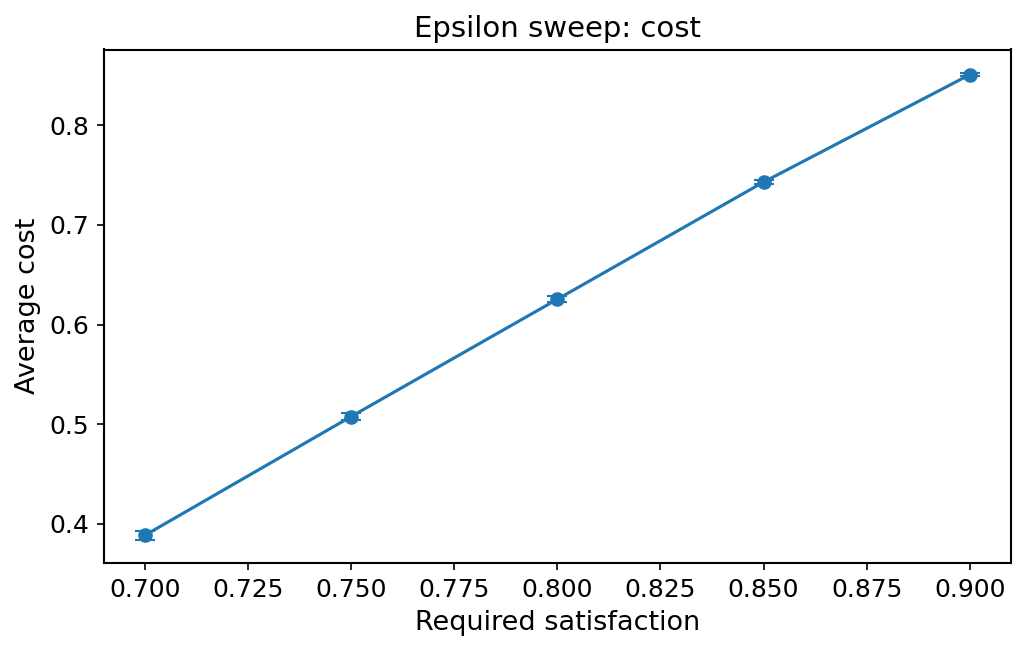

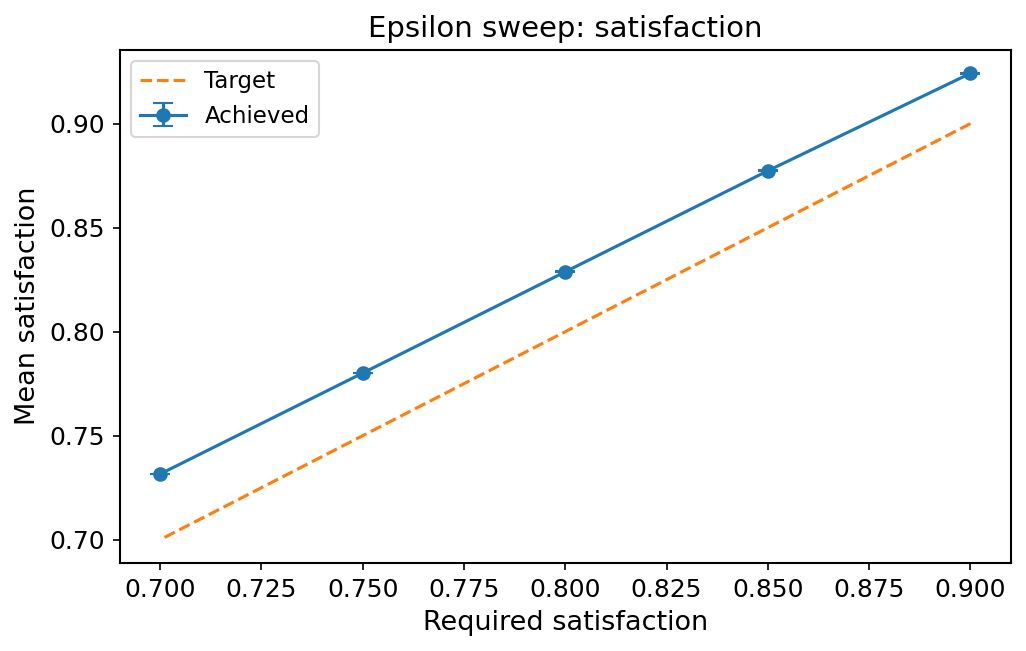


EXPERIMENT 7: CONTEXT ROBUSTNESS

Theta* alignment with fixed direction: 0.999825
Theta* angle from fixed direction: 1.073 degrees

Running xi=0.00

Running xi=0.20

Running xi=0.35

Running xi=0.50

Running xi=0.75

Running xi=1.00

 mean_cost  cost_ci95_low  cost_ci95_high  mean_satisfaction  satisfaction_ci95_low  satisfaction_ci95_high  constraint_probability  constraint_ci95_low  constraint_ci95_high  fallback_rate   xi
  0.690098       0.687103        0.693093           0.831897               0.831760                0.832034                     1.0             0.996318                   1.0       0.589752 0.00
  0.658791       0.655661        0.661920           0.830316               0.830172                0.830460                     1.0             0.996318                   1.0       0.553174 0.20
  0.624860       0.621756        0.627963           0.828781               0.828630                0.828932                     1.0             0.996318                   1.0      

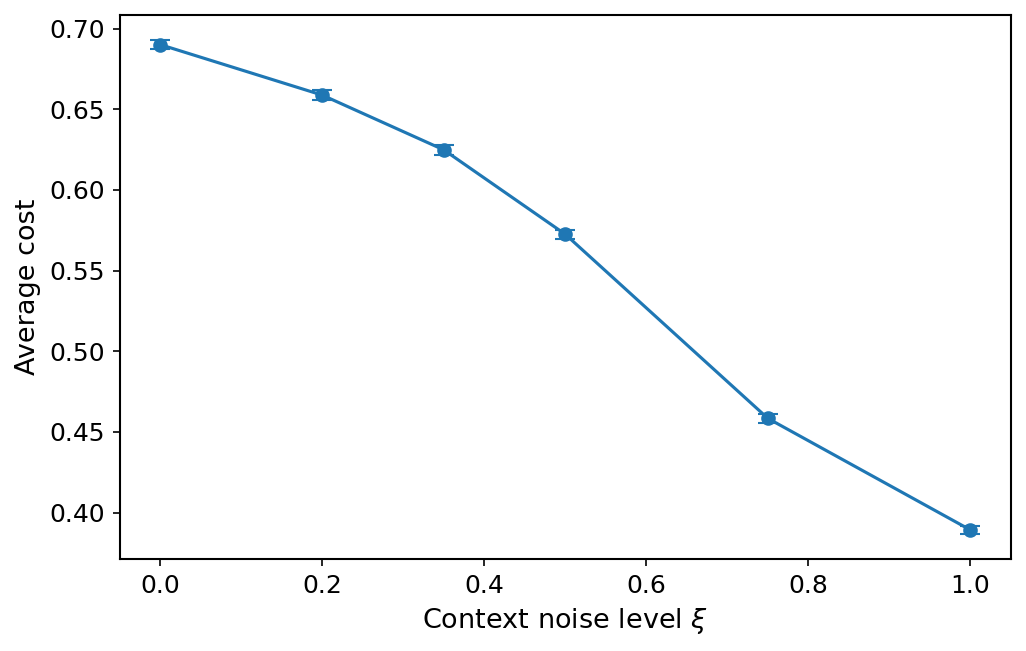

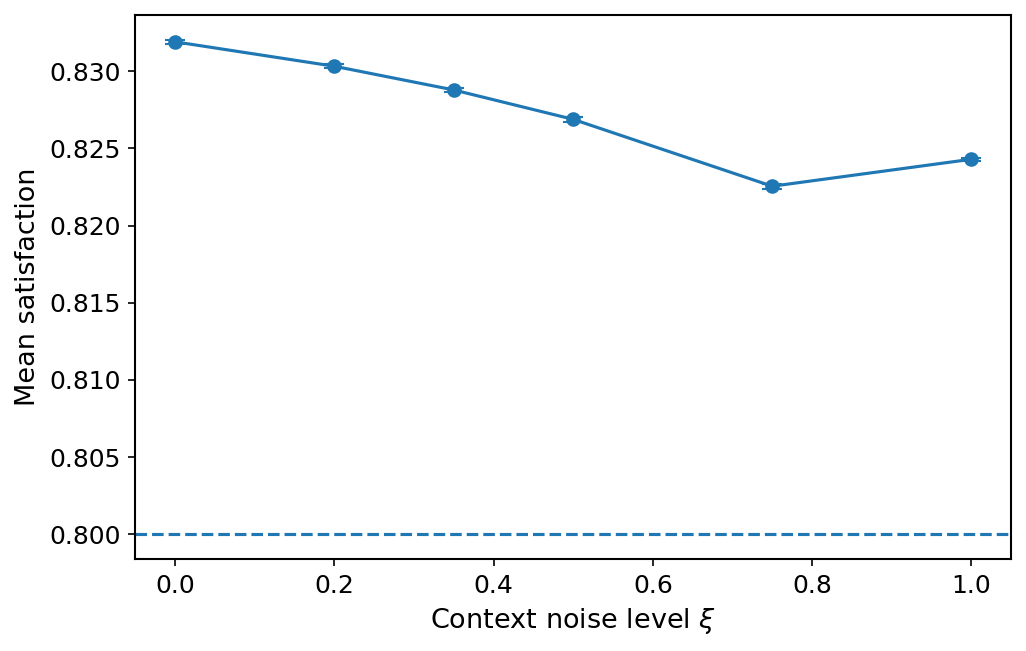

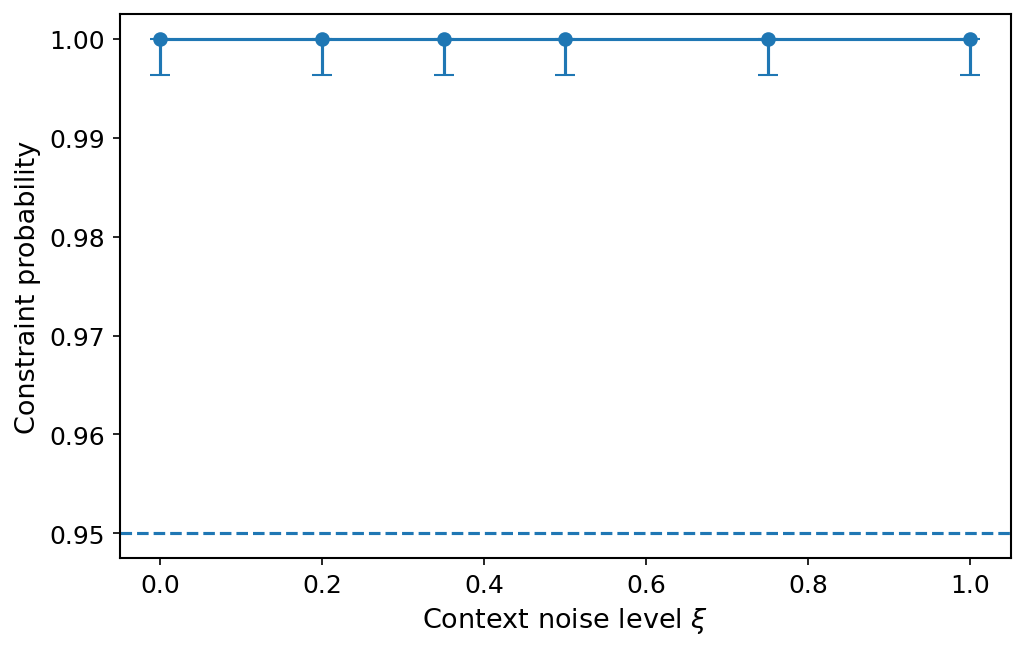


EXPERIMENT 9: CONFIDENCE CALIBRATION
   T  mean_error  median_error  q95_error  mean_theory_width  mean_calibrated_width  median_error_over_theory_width  median_error_over_calibrated_width  q95_error_over_theory_width  q95_error_over_calibrated_width  fraction_error_below_theory_width  fraction_error_below_calibrated_width  alpha_scale_frozen
1000    0.053193      0.040034   0.148603          19.188074                0.09594                        0.002428                            0.485606                     0.007124                         1.424765                                1.0                                0.83375               0.005


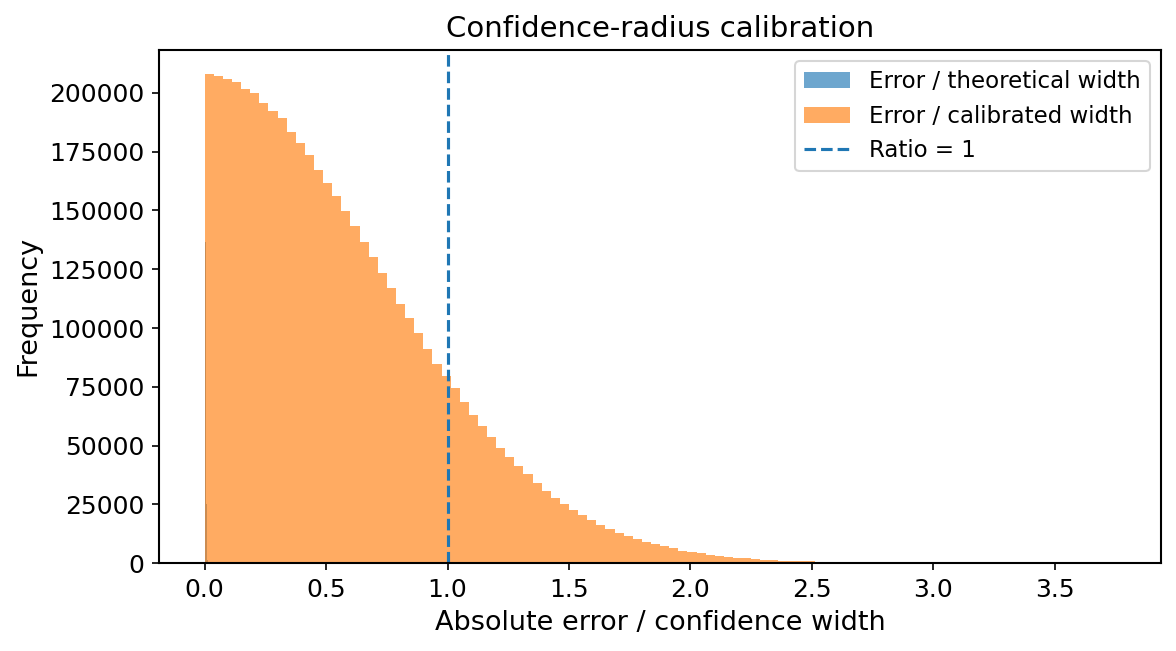

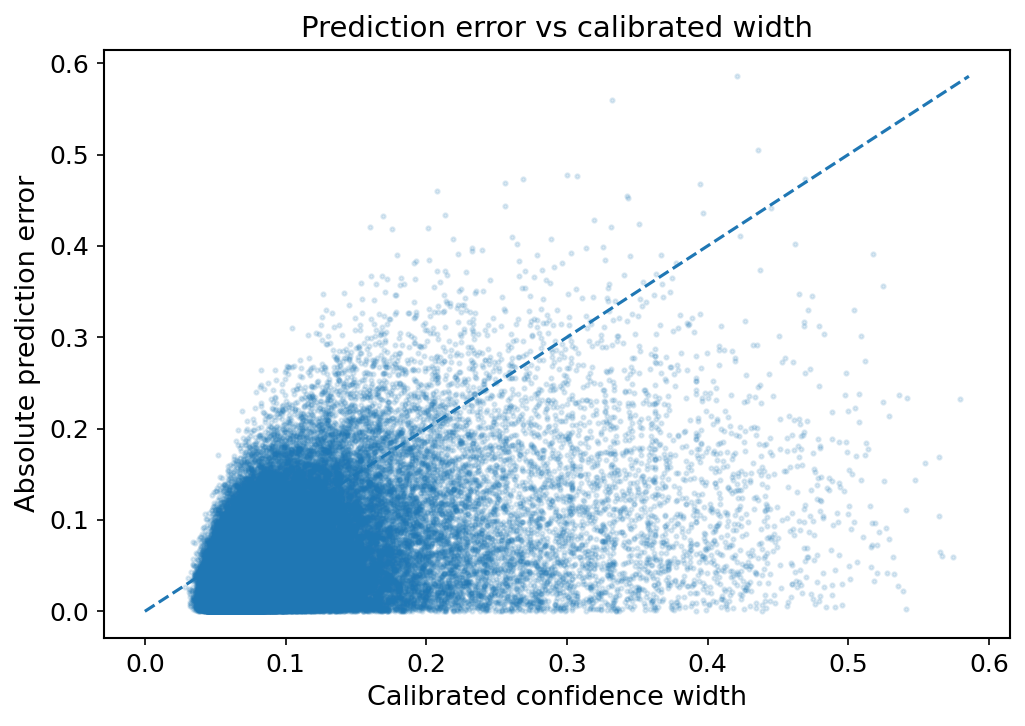


COMPLETE EXPERIMENT SUITE FINISHED

All results were written to:
/home/ameya-anjarlekar/Documents/LLM Routing/icml_llm_routing_results

Error-bar results:
/home/ameya-anjarlekar/Documents/LLM Routing/icml_llm_routing_results/errorbars

Reference protocol:
Reference T       = 100
Reference eta     = 0.5
Reference rho     = 0.15
Frozen alpha      = 0.005

At T=1000:
eta = 0.158114
rho = 0.047434

At T=100:
eta = 0.500000
rho = 0.150000

Theoretical rho_max* at T=100:
0.054755192

Theoretical rho_max* at T=1000:
0.019673027

Empirical Experiment 8 exponent:


NameError: name 'regret_exponent' is not defined

In [18]:
# ================================================================
# ICML PERSONALIZED LLM ROUTING
# COMPLETE STANDALONE EXPERIMENT SUITE
#
# Includes:
#   Experiment 1: Main performance
#   Experiment 2: Chance constraint
#   Experiment 3: Epsilon sweep
#   Experiment 4: Delta sweep
#   Experiment 5: Corrected personalization
#   Experiment 6: Ablations
#   Experiment 7: Context robustness
#   Experiment 8: Finite-horizon cost-gap scaling
#   Experiment 9: Confidence calibration
#
# Statistical reporting:
#   - 95% CIs for mean quantities
#   - Exact binomial CIs for chance-constraint probabilities
#   - Trial-level CSVs wherever appropriate
#
# IMPORTANT:
#   This is standalone. It does NOT depend on variables from
#   a previous notebook cell.
# ================================================================


# ================================================================
# 0. IMPORTS
# ================================================================

import math
import warnings
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import minimize
from scipy.special import expit
from scipy.stats import beta as beta_dist
from scipy.stats import t as student_t


warnings.filterwarnings(
    "ignore",
    category=RuntimeWarning,
)


# ================================================================
# 1. OUTPUT DIRECTORIES
# ================================================================

OUT = Path(
    "icml_llm_routing_results"
)

OUT.mkdir(
    parents=True,
    exist_ok=True,
)

ERRORBAR_OUT = (
    OUT / "errorbars"
)

ERRORBAR_OUT.mkdir(
    parents=True,
    exist_ok=True,
)

print("=" * 72)
print("ICML PERSONALIZED LLM ROUTING")
print("COMPLETE STANDALONE EXPERIMENT SUITE")
print("=" * 72)

print(
    "\nResults directory:"
)
print(
    OUT.resolve()
)


# ================================================================
# 2. GLOBAL EXPERIMENT SETTINGS
# ================================================================

SEED = 12345


# ------------------------------------------------
# Reference horizon / hyperparameters
# ------------------------------------------------

REFERENCE_T = 100

REFERENCE_ETA = 0.5

REFERENCE_RHO = 0.15

FROZEN_ALPHA_SCALE = 0.005


# ------------------------------------------------
# Main horizon
# ------------------------------------------------

BASE_T = 1000

T = BASE_T


# ------------------------------------------------
# Main safety parameters
# ------------------------------------------------

MAIN_EPSILON = 0.20

MAIN_DELTA = 0.05


# ------------------------------------------------
# Environment
# ------------------------------------------------

D = 8

K = 5

COSTS = np.array(
    [
        0.10,
        0.25,
        0.40,
        0.60,
        0.80,
    ],
    dtype=float,
)

FALLBACK = K

FALLBACK_COST = 1.0

FALLBACK_UCB = 1.0


# ------------------------------------------------
# GLM / context parameters
# ------------------------------------------------

L = 3.0

S = 1.0

BETA = 1.0

ZETA = 2.5

XI = 0.35


# ------------------------------------------------
# Context radii
# ------------------------------------------------

MODEL_RADII = np.array(
    [
        1.05,
        1.1625,
        1.275,
        1.3875,
        1.50,
    ],
    dtype=float,
)


# ------------------------------------------------
# Experiment sample sizes
# ------------------------------------------------
#
# These are deliberately explicit.
# Increase them later if you want tighter CIs.
# ------------------------------------------------

N_MAIN = 1000

N_CHANCE = 5000

N_EPS = 1000

N_DELTA = 1000

N_PERSONALIZATION = 1000

N_ABLATION = 1000

N_ROBUSTNESS = 1000

N_REGRET = 1000

N_CALIBRATION = 1000


# ------------------------------------------------
# Horizons
# ------------------------------------------------

HORIZONS = [
    100,
    250,
    500,
    1000,
    2000,
]


# ================================================================
# 3. BASIC MATH HELPERS
# ================================================================

def unit(x):
    """
    Return a unit-normalized vector.
    """

    x = np.asarray(
        x,
        dtype=float,
    )

    norm = np.linalg.norm(x)

    if norm < 1e-12:
        x = np.zeros_like(x)
        x[0] = 1.0
        norm = 1.0

    return x / norm


def horizon_scale(T_value):
    """
    sqrt(T0 / T)
    """

    return math.sqrt(
        REFERENCE_T / T_value
    )


def horizon_eta(T_value):
    """
    eta_T = eta_100 * sqrt(100/T)
    """

    return (
        REFERENCE_ETA
        * horizon_scale(T_value)
    )


def horizon_rho(T_value):
    """
    rho_T = rho_100 * sqrt(100/T)
    """

    return (
        REFERENCE_RHO
        * horizon_scale(T_value)
    )


# ================================================================
# 4. THEORETICAL RHO MAX
# ================================================================

def rho_max_star(
    T_value,
    epsilon,
    delta,
):
    """
    Exact finite-horizon safety margin.

    q = 1 - epsilon

    m = ceil(T q)

    Find mu such that:

        P[Binomial(T, mu) >= m] = 1-delta

    Then:

        rho_max = mu - q
    """

    from scipy.stats import binom

    q = 1.0 - epsilon

    m = int(
        math.ceil(
            T_value * q
        )
    )

    if m <= 0:
        return -q

    if m > T_value:
        return 1.0 - q

    target = 1.0 - delta

    def f(mu):

        probability = (
            binom.sf(
                m - 1,
                T_value,
                mu,
            )
        )

        return (
            probability
            - target
        )

    lo = q
    hi = 1.0

    if f(lo) >= 0:
        mu_star = lo

    elif f(hi) <= 0:
        mu_star = hi

    else:

        for _ in range(80):

            mid = (
                lo + hi
            ) / 2.0

            if f(mid) >= 0:
                hi = mid

            else:
                lo = mid

        mu_star = (
            lo + hi
        ) / 2.0

    return (
        mu_star - q
    )


# ================================================================
# 5. THEORETICAL ALPHA
# ================================================================

def sigma_prime(z):
    """
    Derivative of logistic link.
    """

    p = expit(z)

    return (
        p * (1.0 - p)
    )


KAPPA = sigma_prime(L)

if KAPPA <= 0:
    raise RuntimeError(
        "Invalid kappa."
    )


def theoretical_alpha(
    t,
):
    """
    Theoretical GLM-UCB radius.

    alpha_t =
        1/kappa [
            1/2 sqrt(
                d log(1+t L^2/(d beta))
                + 2 log(2/delta_E)
            )
            + sqrt(beta) S
        ]

    delta_E = t^{-zeta}
    """

    t = max(
        1,
        int(t),
    )

    delta_E = (
        t ** (-ZETA)
    )

    inside = (
        D
        * math.log(
            1.0
            + (
                t
                * L**2
                / (D * BETA)
            )
        )
        + 2.0
        * math.log(
            2.0 / delta_E
        )
    )

    return (
        1.0 / KAPPA
        * (
            0.5
            * math.sqrt(
                max(
                    0.0,
                    inside,
                )
            )
            + math.sqrt(BETA)
            * S
        )
    )


def empirical_alpha(
    t,
    scale=FROZEN_ALPHA_SCALE,
):
    """
    Empirically calibrated radius.

    The theoretical alpha is multiplied by a fixed
    scale factor. The scale is NOT changed with T.
    """

    return (
        scale
        * theoretical_alpha(t)
    )


# ================================================================
# 6. CONTEXT GENERATION
# ================================================================

def make_model_directions(
    rng,
):
    """
    Five model directions.
    """

    directions = []

    for _ in range(K):

        directions.append(
            unit(
                rng.normal(
                    size=D
                )
            )
        )

    return np.asarray(
        directions
    )


def make_user_directions(
    rng,
    n_users=5,
):
    """
    User-specific directions.
    """

    directions = []

    for _ in range(n_users):

        directions.append(
            unit(
                rng.normal(
                    size=D
                )
            )
        )

    return np.asarray(
        directions
    )


def generate_contexts(
    rng,
    theta_star,
    model_dirs,
    xi=XI,
    user_dir=None,
    shared_mode=False,
    T_override=None,
):
    """
    Generate model-specific contextual vectors.

    Contexts lie inside spherical caps around model
    directions, with additional user/context variation.

    Shape:

        (T, K, D)
    """

    if T_override is None:
        T_override = T

    X = np.zeros(
        (
            T_override,
            K,
            D,
        ),
        dtype=float,
    )

    theta_dir = unit(
        theta_star
    )

    if user_dir is None:
        user_dir = theta_dir

    user_dir = unit(
        user_dir
    )

    for t in range(
        T_override
    ):

        for a in range(K):

            base = model_dirs[a]

            # random tangent perturbation
            noise = rng.normal(
                size=D
            )

            noise = (
                noise
                - np.dot(
                    noise,
                    base,
                )
                * base
            )

            noise_norm = np.linalg.norm(
                noise
            )

            if noise_norm < 1e-12:

                noise = np.zeros(D)

            else:

                noise /= noise_norm

            # Uniform-ish random radius inside the cap.
            radius = (
                MODEL_RADII[a]
                * (
                    rng.random()
                    ** (
                        1.0
                        / max(
                            1,
                            D - 1,
                        )
                    )
                )
            )

            direction = unit(
                base
                + radius
                * noise
            )

            # User/context mixture.
            if shared_mode:

                direction = unit(
                    (
                        1.0 - xi
                    )
                    * direction
                    + xi
                    * theta_dir
                )

            else:

                direction = unit(
                    (
                        1.0 - xi
                    )
                    * direction
                    + xi
                    * user_dir
                )

            X[t, a] = (
                direction
                * min(
                    MODEL_RADII[a],
                    L,
                )
            )

    return X


# ================================================================
# 7. LOGISTIC MLE
# ================================================================

def logistic_mle(
    X,
    y,
):
    """
    Ridge logistic maximum likelihood estimate.

    Objective:
        negative log-likelihood
        + 0.5 beta ||theta||^2

    Newton-CG/L-BFGS style numerical optimization is used
    through scipy.optimize.minimize.

    For small sample sizes, returns zeros if optimization
    cannot be performed.
    """

    X = np.asarray(
        X,
        dtype=float,
    )

    y = np.asarray(
        y,
        dtype=float,
    )

    if len(y) == 0:
        return np.zeros(D)

    theta0 = np.zeros(D)

    def objective(theta):

        z = X @ theta

        # stable log(1 + exp(z))
        log_term = np.logaddexp(
            0.0,
            z,
        )

        nll = np.sum(
            log_term
            - y * z
        )

        ridge = (
            0.5
            * BETA
            * np.dot(
                theta,
                theta,
            )
        )

        return (
            nll + ridge
        )

    def gradient(theta):

        z = X @ theta

        p = expit(z)

        grad = (
            X.T
            @ (
                p - y
            )
        )

        grad += (
            BETA
            * theta
        )

        return grad

    try:

        result = minimize(
            objective,
            theta0,
            jac=gradient,
            method="L-BFGS-B",
            options={
                "maxiter": 100,
                "ftol": 1e-8,
                "gtol": 1e-6,
            },
        )

        if result.success:

            return result.x

        return result.x

    except Exception:

        return theta0


# ================================================================
# 8. TRIAL CONFIG
# ================================================================

@dataclass
class TrialConfig:

    epsilon: float = MAIN_EPSILON

    delta: float = MAIN_DELTA

    xi: float = XI

    eta: float | None = None

    rho: float | None = None

    use_ucb: bool = True

    use_queue: bool = True

    use_rho: bool = True

    theta_star: np.ndarray | None = None


# ================================================================
# 9. SINGLE STANDARD TRIAL
# ================================================================

def run_trial(
    config,
    seed,
    T_run=None,
):
    """
    Run one standard routing trial.
    """

    if T_run is None:
        T_run = BASE_T

    rng = np.random.default_rng(
        seed
    )

    epsilon = (
        config.epsilon
    )

    eta = (
        horizon_eta(T_run)
        if config.eta is None
        else config.eta
    )

    rho = (
        horizon_rho(T_run)
        if config.rho is None
        else config.rho
    )

    if not config.use_rho:
        rho_used = 0.0
    else:
        rho_used = rho

    # ------------------------------------------------------------
    # True parameter
    # ------------------------------------------------------------

    if config.theta_star is None:

        theta_star = (
            unit(
                rng.normal(
                    size=D
                )
            )
            * S
        )

    else:

        theta_star = np.asarray(
            config.theta_star,
            dtype=float,
        ).copy()

    # ------------------------------------------------------------
    # Model directions
    # ------------------------------------------------------------

    model_dirs = (
        make_model_directions(
            rng
        )
    )

    # ------------------------------------------------------------
    # Contexts
    # ------------------------------------------------------------

    X = generate_contexts(
        rng=rng,
        theta_star=theta_star,
        model_dirs=model_dirs,
        xi=config.xi,
        user_dir=unit(theta_star),
        shared_mode=False,
        T_override=T_run,
    )

    # ------------------------------------------------------------
    # True probabilities
    # ------------------------------------------------------------

    P = expit(
        np.einsum(
            "tkd,d->tk",
            X,
            theta_star,
        )
    )

    # ------------------------------------------------------------
    # Learner state
    # ------------------------------------------------------------

    V = (
        BETA
        * np.eye(D)
    )

    history_X = []

    history_y = []

    lam = 0.0

    # ------------------------------------------------------------
    # Outputs
    # ------------------------------------------------------------

    action_history = np.zeros(
        T_run,
        dtype=int,
    )

    outcome_history = np.zeros(
        T_run,
        dtype=int,
    )

    cost_history = np.zeros(
        T_run
    )

    fallback_history = np.zeros(
        T_run
    )

    selected_true_p = np.zeros(
        T_run
    )

    selected_ucb = np.zeros(
        T_run
    )

    lambda_history = np.zeros(
        T_run
    )

    # ------------------------------------------------------------
    # Online loop
    # ------------------------------------------------------------

    for t in range(
        T_run
    ):

        # --------------------------------------------------------
        # Estimate theta
        # --------------------------------------------------------

        if len(history_y) > 0:

            theta_hat = logistic_mle(
                np.asarray(
                    history_X
                ),
                np.asarray(
                    history_y
                ),
            )

        else:

            theta_hat = np.zeros(D)

        Vinv = np.linalg.pinv(
            V
        )

        # --------------------------------------------------------
        # Confidence radius
        # --------------------------------------------------------

        alpha = empirical_alpha(
            t + 1,
            FROZEN_ALPHA_SCALE,
        )

        # --------------------------------------------------------
        # Scores
        # --------------------------------------------------------

        scores = np.zeros(
            K + 1
        )

        ucbs = np.zeros(
            K + 1
        )

        for a in range(K):

            x = X[t, a]

            mean = float(
                expit(
                    x @ theta_hat
                )
            )

            if config.use_ucb:

                uncertainty = math.sqrt(
                    max(
                        0.0,
                        x
                        @ Vinv
                        @ x,
                    )
                )

                ucb = (
                    mean
                    + alpha
                    * uncertainty
                )

            else:

                ucb = mean

            ucbs[a] = ucb

        # --------------------------------------------------------
        # Perfect fallback
        # --------------------------------------------------------

        ucbs[FALLBACK] = (
            FALLBACK_UCB
        )

        # --------------------------------------------------------
        # Queue multiplier
        #
        # No-Queue uses lambda=1 as a diagnostic ablation:
        # this removes dynamic dual pricing rather than
        # literally setting lambda to zero.
        # --------------------------------------------------------

        if config.use_queue:

            queue_multiplier = lam

        else:

            queue_multiplier = 1.0

        for a in range(
            K + 1
        ):

            scores[a] = (
                (
                    COSTS[a]
                    if a < K
                    else FALLBACK_COST
                )
                - queue_multiplier
                * ucbs[a]
            )

        action = int(
            np.argmin(scores)
        )

        # --------------------------------------------------------
        # Sample outcome
        # --------------------------------------------------------

        if action == FALLBACK:

            true_p = 1.0

            y = 1

            cost = FALLBACK_COST

            fallback = 1.0

        else:

            true_p = float(
                P[t, action]
            )

            y = int(
                rng.random()
                < true_p
            )

            cost = float(
                COSTS[action]
            )

            fallback = 0.0

        # --------------------------------------------------------
        # Record
        # --------------------------------------------------------

        action_history[t] = action

        outcome_history[t] = y

        cost_history[t] = cost

        fallback_history[t] = fallback

        selected_true_p[t] = true_p

        selected_ucb[t] = (
            ucbs[action]
        )

        lambda_history[t] = lam

        # --------------------------------------------------------
        # Update learner
        # --------------------------------------------------------

        if action < K:

            x_selected = (
                X[t, action].copy()
            )

            history_X.append(
                x_selected
            )

            history_y.append(
                y
            )

            V += np.outer(
                x_selected,
                x_selected,
            )

        # --------------------------------------------------------
        # Queue update
        # --------------------------------------------------------

        if config.use_queue:

            lam = max(
                0.0,
                lam
                + eta
                * (
                    1.0
                    - epsilon
                    + rho_used
                    - y
                ),
            )

    # ------------------------------------------------------------
    # Summary
    # ------------------------------------------------------------

    satisfaction = float(
        np.mean(
            outcome_history
        )
    )

    avg_cost = float(
        np.mean(
            cost_history
        )
    )

    fallback_rate = float(
        np.mean(
            fallback_history
        )
    )

    violation = float(
        satisfaction
        < (
            1.0
            - epsilon
        )
    )

    return {

        "avg_cost":
            avg_cost,

        "satisfaction":
            satisfaction,

        "fallback_rate":
            fallback_rate,

        "violation":
            violation,

        "eta":
            eta,

        "rho":
            rho_used,

        "epsilon":
            epsilon,

        "delta":
            config.delta,

        "xi":
            config.xi,

        "T":
            T_run,

        "actions":
            action_history,

        "outcomes":
            outcome_history,

        "costs":
            cost_history,

        "fallbacks":
            fallback_history,

        "selected_true_p":
            selected_true_p,

        "selected_ucb":
            selected_ucb,

        "lambda":
            lambda_history,

    }


# ================================================================
# 10. MULTIPLE TRIALS
# ================================================================

def run_trials(
    config,
    n_trials,
    seed0=SEED,
    T_run=None,
):
    """
    Run independent trials.
    """

    rows = []

    for i in range(
        n_trials
    ):

        result = run_trial(
            config=config,
            seed=seed0 + i,
            T_run=T_run,
        )

        row = {
            k: v
            for k, v in result.items()
            if np.isscalar(v)
        }

        row["trial"] = i

        rows.append(
            row
        )

    return pd.DataFrame(
        rows
    )


# ================================================================
# 11. CI HELPERS
# ================================================================

def mean_ci95(
    values,
):
    """
    95% Student-t CI for a mean.
    """

    x = np.asarray(
        values,
        dtype=float,
    )

    x = x[
        np.isfinite(x)
    ]

    n = len(x)

    if n == 0:

        return (
            np.nan,
            np.nan,
            np.nan,
        )

    mean = float(
        np.mean(x)
    )

    if n == 1:

        return (
            mean,
            mean,
            mean,
        )

    se = (
        np.std(
            x,
            ddof=1,
        )
        / math.sqrt(n)
    )

    critical = student_t.ppf(
        0.975,
        n - 1,
    )

    half = (
        critical
        * se
    )

    return (
        mean,
        mean - half,
        mean + half,
    )


def proportion_ci95_exact(
    successes,
    n,
):
    """
    Exact Clopper-Pearson 95% CI.
    """

    successes = int(
        successes
    )

    n = int(n)

    if n <= 0:

        return (
            np.nan,
            np.nan,
            np.nan,
        )

    p = (
        successes
        / n
    )

    if successes == 0:

        lo = 0.0

    else:

        lo = beta_dist.ppf(
            0.025,
            successes,
            n - successes + 1,
        )

    if successes == n:

        hi = 1.0

    else:

        hi = beta_dist.ppf(
            0.975,
            successes + 1,
            n - successes,
        )

    return (
        float(p),
        float(lo),
        float(hi),
    )


# ================================================================
# 12. SUMMARY FUNCTION
# ================================================================

def summarize_trials(
    df,
):
    """
    Compact summary with 95% CIs.
    """

    cost_mean, cost_lo, cost_hi = (
        mean_ci95(
            df["avg_cost"]
        )
    )

    sat_mean, sat_lo, sat_hi = (
        mean_ci95(
            df["satisfaction"]
        )
    )

    successes = int(
        np.sum(
            1.0
            - df["violation"]
        )
    )

    cp, cp_lo, cp_hi = (
        proportion_ci95_exact(
            successes,
            len(df),
        )
    )

    return {

        "mean_cost":
            cost_mean,

        "cost_ci95_low":
            cost_lo,

        "cost_ci95_high":
            cost_hi,

        "mean_satisfaction":
            sat_mean,

        "satisfaction_ci95_low":
            sat_lo,

        "satisfaction_ci95_high":
            sat_hi,

        "constraint_probability":
            cp,

        "constraint_ci95_low":
            cp_lo,

        "constraint_ci95_high":
            cp_hi,

        "fallback_rate":
            float(
                df[
                    "fallback_rate"
                ].mean()
            ),

    }


# ================================================================
# 13. EXPERIMENT 1
#     MAIN PERFORMANCE
# ================================================================

def experiment_main():

    print(
        "\n" + "=" * 72
    )

    print(
        "EXPERIMENT 1: MAIN PERFORMANCE"
    )

    print(
        "=" * 72
    )

    methods = {

        "Ours":
            TrialConfig(
                use_ucb=True,
                use_queue=True,
                use_rho=True,
            ),

        "No-UCB":
            TrialConfig(
                use_ucb=False,
                use_queue=True,
                use_rho=True,
            ),

        "No-Queue":
            TrialConfig(
                use_ucb=True,
                use_queue=False,
                use_rho=True,
            ),

        "No-Rho":
            TrialConfig(
                use_ucb=True,
                use_queue=True,
                use_rho=False,
            ),

    }

    all_trials = []

    summaries = []

    for name, config in (
        methods.items()
    ):

        print(
            f"\nRunning {name}..."
        )

        df = run_trials(
            config,
            N_MAIN,
            seed0=SEED + 10000,
            T_run=BASE_T,
        )

        df["method"] = name

        all_trials.append(
            df
        )

        summary = (
            summarize_trials(
                df
            )
        )

        summary["method"] = name

        summaries.append(
            summary
        )

    trials = pd.concat(
        all_trials,
        ignore_index=True,
    )

    summary = pd.DataFrame(
        summaries
    )

    trials.to_csv(
        ERRORBAR_OUT
        / "main_performance_trials.csv",
        index=False,
    )

    summary.to_csv(
        ERRORBAR_OUT
        / "main_performance_errorbars.csv",
        index=False,
    )

    print(
        "\nMAIN RESULTS:"
    )

    print(
        summary[
            [
                "method",
                "mean_cost",
                "cost_ci95_low",
                "cost_ci95_high",
                "mean_satisfaction",
                "satisfaction_ci95_low",
                "satisfaction_ci95_high",
                "constraint_probability",
                "constraint_ci95_low",
                "constraint_ci95_high",
                "fallback_rate",
            ]
        ].to_string(
            index=False
        )
    )

    # ------------------------------------------------------------
    # Cost
    # ------------------------------------------------------------

    y = summary[
        "mean_cost"
    ].to_numpy()

    yerr = np.vstack(
        [
            y
            - summary[
                "cost_ci95_low"
            ].to_numpy(),

            summary[
                "cost_ci95_high"
            ].to_numpy()
            - y,
        ]
    )

    plt.figure(
        figsize=(7, 4.5)
    )

    plt.bar(
        summary["method"],
        y,
        yerr=yerr,
        capsize=5,
    )

    plt.ylabel(
        "Average cost"
    )

    plt.title(
        "Main performance: routing cost"
    )

    plt.tight_layout()

    plt.savefig(
        ERRORBAR_OUT
        / "main_cost_95ci.png",
        dpi=200,
    )

    plt.show()

    plt.close()

    # ------------------------------------------------------------
    # Satisfaction
    # ------------------------------------------------------------

    y = summary[
        "mean_satisfaction"
    ].to_numpy()

    yerr = np.vstack(
        [
            y
            - summary[
                "satisfaction_ci95_low"
            ].to_numpy(),

            summary[
                "satisfaction_ci95_high"
            ].to_numpy()
            - y,
        ]
    )

    plt.figure(
        figsize=(7, 4.5)
    )

    plt.bar(
        summary["method"],
        y,
        yerr=yerr,
        capsize=5,
    )

    plt.axhline(
        1.0 - MAIN_EPSILON,
        linestyle="--",
        label="Required satisfaction",
    )

    plt.ylabel(
        "Mean satisfaction"
    )

    plt.title(
        "Main performance: satisfaction"
    )

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        ERRORBAR_OUT
        / "main_satisfaction_95ci.png",
        dpi=200,
    )

    plt.show()

    plt.close()

    return (
        trials,
        summary,
    )


# ================================================================
# 14. EXPERIMENT 2
#     CHANCE CONSTRAINT
# ================================================================

def experiment_chance_constraint():

    print(
        "\n" + "=" * 72
    )

    print(
        "EXPERIMENT 2: CHANCE CONSTRAINT"
    )

    print(
        "=" * 72
    )

    config = TrialConfig()

    df = run_trials(
        config,
        N_CHANCE,
        seed0=SEED + 20000,
        T_run=BASE_T,
    )

    successes = int(
        np.sum(
            1.0
            - df["violation"]
        )
    )

    cp, cp_lo, cp_hi = (
        proportion_ci95_exact(
            successes,
            len(df),
        )
    )

    summary = pd.DataFrame(
        [
            {
                "T":
                    BASE_T,

                "epsilon":
                    MAIN_EPSILON,

                "delta":
                    MAIN_DELTA,

                "target_satisfaction":
                    1.0 - MAIN_EPSILON,

                "target_probability":
                    1.0 - MAIN_DELTA,

                "observed_constraint_probability":
                    cp,

                "ci95_low":
                    cp_lo,

                "ci95_high":
                    cp_hi,

                "mean_satisfaction":
                    df[
                        "satisfaction"
                    ].mean(),

                "mean_cost":
                    df[
                        "avg_cost"
                    ].mean(),

                "rho":
                    horizon_rho(
                        BASE_T
                    ),

                "rho_max_star":
                    rho_max_star(
                        BASE_T,
                        MAIN_EPSILON,
                        MAIN_DELTA,
                    ),
            }
        ]
    )

    df.to_csv(
        ERRORBAR_OUT
        / "chance_constraint_trials.csv",
        index=False,
    )

    summary.to_csv(
        ERRORBAR_OUT
        / "chance_constraint.csv",
        index=False,
    )

    print(
        summary.to_string(
            index=False
        )
    )

    # ------------------------------------------------------------
    # Satisfaction distribution
    # ------------------------------------------------------------

    plt.figure(
        figsize=(7, 4.5)
    )

    plt.hist(
        df["satisfaction"],
        bins=30,
        alpha=0.8,
    )

    plt.axvline(
        1.0 - MAIN_EPSILON,
        linestyle="--",
        label="Required satisfaction",
    )

    plt.xlabel(
        "Episode satisfaction"
    )

    plt.ylabel(
        "Number of trials"
    )

    plt.title(
        "Chance-constraint satisfaction distribution"
    )

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        ERRORBAR_OUT
        / "chance_constraint_distribution.png",
        dpi=200,
    )

    plt.show()

    plt.close()

    return (
        df,
        summary,
    )


# ================================================================
# 15. EXPERIMENT 3
#     EPSILON SWEEP
# ================================================================

def experiment_epsilon():

    print(
        "\n" + "=" * 72
    )

    print(
        "EXPERIMENT 3: EPSILON SWEEP"
    )

    print(
        "=" * 72
    )

    epsilon_values = [
        0.10,
        0.15,
        0.20,
        0.25,
        0.30,
    ]

    trial_rows = []

    summary_rows = []

    for eps in epsilon_values:

        print(
            f"\nRunning epsilon={eps:.2f}"
        )

        config = TrialConfig(
            epsilon=eps,
        )

        df = run_trials(
            config,
            N_EPS,
            seed0=SEED + 30000,
            T_run=BASE_T,
        )

        df["epsilon"] = eps

        trial_rows.append(
            df
        )

        s = summarize_trials(
            df
        )

        s["epsilon"] = eps

        s[
            "required_satisfaction"
        ] = 1.0 - eps

        summary_rows.append(
            s
        )

    trials = pd.concat(
        trial_rows,
        ignore_index=True,
    )

    summary = pd.DataFrame(
        summary_rows
    ).sort_values(
        "epsilon"
    )

    trials.to_csv(
        ERRORBAR_OUT
        / "epsilon_sweep_trials.csv",
        index=False,
    )

    summary.to_csv(
        ERRORBAR_OUT
        / "epsilon_sweep_errorbars.csv",
        index=False,
    )

    print(
        summary.to_string(
            index=False
        )
    )

    x = summary[
        "required_satisfaction"
    ].to_numpy()

    # Cost
    y = summary[
        "mean_cost"
    ].to_numpy()

    yerr = np.vstack(
        [
            y
            - summary[
                "cost_ci95_low"
            ].to_numpy(),

            summary[
                "cost_ci95_high"
            ].to_numpy()
            - y,
        ]
    )

    plt.figure(
        figsize=(7, 4.5)
    )

    plt.errorbar(
        x,
        y,
        yerr=yerr,
        marker="o",
        capsize=5,
    )

    plt.xlabel(
        "Required satisfaction"
    )

    plt.ylabel(
        "Average cost"
    )

    plt.title(
        "Epsilon sweep: cost"
    )

    plt.tight_layout()

    plt.savefig(
        ERRORBAR_OUT
        / "epsilon_cost_quality_95ci.png",
        dpi=200,
    )

    plt.show()

    plt.close()

    # Satisfaction
    y = summary[
        "mean_satisfaction"
    ].to_numpy()

    yerr = np.vstack(
        [
            y
            - summary[
                "satisfaction_ci95_low"
            ].to_numpy(),

            summary[
                "satisfaction_ci95_high"
            ].to_numpy()
            - y,
        ]
    )

    plt.figure(
        figsize=(7, 4.5)
    )

    plt.errorbar(
        x,
        y,
        yerr=yerr,
        marker="o",
        capsize=5,
        label="Achieved",
    )

    plt.plot(
        x,
        x,
        linestyle="--",
        label="Target",
    )

    plt.xlabel(
        "Required satisfaction"
    )

    plt.ylabel(
        "Mean satisfaction"
    )

    plt.title(
        "Epsilon sweep: satisfaction"
    )

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        ERRORBAR_OUT
        / "epsilon_satisfaction_95ci.png",
        dpi=200,
    )

    plt.show()

    plt.close()

    return (
        trials,
        summary,
    )


# ================================================================
# 16. EXPERIMENT 4
#     DELTA SWEEP
# ================================================================

def experiment_delta():

    print(
        "\n" + "=" * 72
    )

    print(
        "EXPERIMENT 4: DELTA SWEEP"
    )

    print(
        "=" * 72
    )

    delta_values = [
        0.01,
        0.05,
        0.10,
    ]

    trial_rows = []

    summary_rows = []

    for delta in delta_values:

        print(
            f"\nRunning delta={delta:.2f}"
        )

        config = TrialConfig(
            epsilon=MAIN_EPSILON,
            delta=delta,
        )

        df = run_trials(
            config,
            N_DELTA,
            seed0=SEED + 40000,
            T_run=BASE_T,
        )

        df["delta"] = delta

        trial_rows.append(
            df
        )

        successes = int(
            np.sum(
                1.0
                - df["violation"]
            )
        )

        cp, cp_lo, cp_hi = (
            proportion_ci95_exact(
                successes,
                len(df),
            )
        )

        summary_rows.append(
            {
                "delta":
                    delta,

                "required_probability":
                    1.0 - delta,

                "constraint_probability":
                    cp,

                "constraint_ci95_low":
                    cp_lo,

                "constraint_ci95_high":
                    cp_hi,

                "mean_cost":
                    df[
                        "avg_cost"
                    ].mean(),

                "mean_satisfaction":
                    df[
                        "satisfaction"
                    ].mean(),
            }
        )

    trials = pd.concat(
        trial_rows,
        ignore_index=True,
    )

    summary = pd.DataFrame(
        summary_rows
    ).sort_values(
        "delta"
    )

    trials.to_csv(
        ERRORBAR_OUT
        / "delta_sweep_trials.csv",
        index=False,
    )

    summary.to_csv(
        ERRORBAR_OUT
        / "delta_sweep_errorbars.csv",
        index=False,
    )

    print(
        summary.to_string(
            index=False
        )
    )

    x = summary[
        "required_probability"
    ].to_numpy()

    y = summary[
        "constraint_probability"
    ].to_numpy()

    yerr = np.vstack(
        [
            y
            - summary[
                "constraint_ci95_low"
            ].to_numpy(),

            summary[
                "constraint_ci95_high"
            ].to_numpy()
            - y,
        ]
    )

    plt.figure(
        figsize=(7, 4.5)
    )

    plt.errorbar(
        x,
        y,
        yerr=yerr,
        marker="o",
        capsize=5,
        label="Observed",
    )

    plt.plot(
        x,
        x,
        linestyle="--",
        label="Required",
    )

    plt.xlabel(
        "Required chance-constraint probability"
    )

    plt.ylabel(
        "Observed probability"
    )

    plt.title(
        "Delta sweep: chance-constraint probability"
    )

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        ERRORBAR_OUT
        / "delta_constraint_probability_95ci.png",
        dpi=200,
    )

    plt.show()

    plt.close()

    return (
        trials,
        summary,
    )


# ================================================================
# 17. EXPERIMENT 5
#     CORRECTED PERSONALIZATION
# ================================================================
def run_personalization_method(
    X_all,
    P_all,
    uniforms,
    mode,
    epsilon,
    eta,
    rho,
):
    """
    Run either:

        mode="global"
        mode="personalized"

    on the SAME counterfactual environment.

    Experimental setup:
        - X_all[u, t, a] contains the same underlying
          request/context for all users.
        - P_all[u, t, a] differs across users because
          each user has a different true preference parameter.

    Global:
        one pooled theta_hat and V across all users.

    Personalized:
        one theta_hat and V per user.

    Both methods use:
        - one independent safety queue per user
        - the same counterfactual uniforms
        - the same contexts and candidate actions
    """

    n_users = X_all.shape[0]
    T_run = X_all.shape[1]

    if mode not in ("global", "personalized"):
        raise ValueError("Invalid mode.")

    # ------------------------------------------------------------
    # Learner state
    # ------------------------------------------------------------

    if mode == "global":

        V_global = BETA * np.eye(D)

        history_X_global = []
        history_y_global = []

    else:

        V_user = [
            BETA * np.eye(D)
            for _ in range(n_users)
        ]

        history_X_user = [
            []
            for _ in range(n_users)
        ]

        history_y_user = [
            []
            for _ in range(n_users)
        ]

    # ------------------------------------------------------------
    # Independent safety queue for each user
    # ------------------------------------------------------------

    lambdas = np.zeros(n_users)

    # ------------------------------------------------------------
    # Outputs
    # ------------------------------------------------------------

    costs = np.zeros(
        (n_users, T_run)
    )

    outcomes = np.zeros(
        (n_users, T_run),
        dtype=int,
    )

    fallback = np.zeros(
        (n_users, T_run)
    )

    selected_action = np.zeros(
        (n_users, T_run),
        dtype=int,
    )

    # ------------------------------------------------------------
    # Online round-robin interaction
    # ------------------------------------------------------------

    for t in range(T_run):

        for u in range(n_users):

            # ----------------------------------------------------
            # Current parameter estimate
            # ----------------------------------------------------

            if mode == "global":

                if len(history_y_global) > 0:

                    theta_hat = logistic_mle(
                        np.asarray(history_X_global),
                        np.asarray(history_y_global),
                    )

                else:

                    theta_hat = np.zeros(D)

                V_current = V_global

            else:

                if len(history_y_user[u]) > 0:

                    theta_hat = logistic_mle(
                        np.asarray(history_X_user[u]),
                        np.asarray(history_y_user[u]),
                    )

                else:

                    theta_hat = np.zeros(D)

                V_current = V_user[u]

            # ----------------------------------------------------
            # Confidence radius
            # ----------------------------------------------------

            Vinv = np.linalg.pinv(V_current)

            alpha = empirical_alpha(
                t + 1,
                FROZEN_ALPHA_SCALE,
            )

            # ----------------------------------------------------
            # Action scores
            # ----------------------------------------------------

            scores = np.zeros(K + 1)

            for a in range(K):

                x = X_all[
                    u,
                    t,
                    a,
                ]

                mean = float(
                    expit(
                        x @ theta_hat
                    )
                )

                uncertainty = math.sqrt(
                    max(
                        0.0,
                        x @ Vinv @ x,
                    )
                )

                ucb = (
                    mean
                    + alpha * uncertainty
                )

                scores[a] = (
                    COSTS[a]
                    - lambdas[u] * ucb
                )

            # ----------------------------------------------------
            # Perfect fallback
            # ----------------------------------------------------

            scores[FALLBACK] = (
                FALLBACK_COST
                - lambdas[u] * FALLBACK_UCB
            )

            action = int(
                np.argmin(scores)
            )

            selected_action[
                u,
                t,
            ] = action

            # ----------------------------------------------------
            # Observe selected action outcome
            # ----------------------------------------------------

            if action == FALLBACK:

                y = 1
                cost = FALLBACK_COST

                fallback[
                    u,
                    t,
                ] = 1.0

            else:

                p = P_all[
                    u,
                    t,
                    action,
                ]

                y = int(
                    uniforms[
                        u,
                        t,
                        action,
                    ] < p
                )

                cost = float(
                    COSTS[action]
                )

                x_selected = X_all[
                    u,
                    t,
                    action,
                ].copy()

                # ------------------------------------------------
                # Update appropriate learner
                # ------------------------------------------------

                if mode == "global":

                    history_X_global.append(
                        x_selected
                    )

                    history_y_global.append(
                        y
                    )

                    V_global += np.outer(
                        x_selected,
                        x_selected,
                    )

                else:

                    history_X_user[u].append(
                        x_selected
                    )

                    history_y_user[u].append(
                        y
                    )

                    V_user[u] += np.outer(
                        x_selected,
                        x_selected,
                    )

            costs[
                u,
                t,
            ] = cost

            outcomes[
                u,
                t,
            ] = y

            # ----------------------------------------------------
            # Update user-specific safety queue
            # ----------------------------------------------------

            lambdas[u] = max(
                0.0,
                lambdas[u]
                + eta * (
                    1.0
                    - epsilon
                    + rho
                    - y
                ),
            )

    return {
        "costs": costs,
        "outcomes": outcomes,
        "fallback": fallback,
        "actions": selected_action,
    }

def make_personalized_user_preferences(
    rng,
    model_dirs,
    n_users=5,
    alignment=0.7,
):
    """
    Create heterogeneous user preference vectors.

    User u's preference vector is centered around model_dirs[u],
    with additional random perturbation.

    alignment:
        Higher -> user preference is more strongly aligned with
        the corresponding model direction.

    Returns:
        theta_users: shape (n_users, D)
    """
    assert n_users <= len(model_dirs)

    theta_users = []

    for u in range(n_users):
        noise = unit(rng.normal(size=D))

        theta_user = unit(
            alignment * model_dirs[u]
            + (1.0 - alignment) * noise
        ) * S

        theta_users.append(theta_user)

    return np.array(theta_users)

    
def experiment_personalization():

    print(
        "\n" + "=" * 72
    )

    print(
        "EXPERIMENT 5: PERSONALIZATION"
    )

    print(
        "=" * 72
    )

    n_users = 5

    # ------------------------------------------------------------
    # User preference alignment with model directions
    #
    # User u is preferentially aligned with model u, while
    # retaining random variation.
    #
    # theta_u^* =
    #   S * unit(
    #       ALIGNMENT * d_u
    #       + (1 - ALIGNMENT) * z_u
    #   )
    #
    # where d_u is model u's direction and z_u is random noise.
    # ------------------------------------------------------------

    ALIGNMENT = 0.7

    eta = horizon_eta(
        BASE_T
    )

    rho = horizon_rho(
        BASE_T
    )

    print(
        f"T = {BASE_T}"
    )

    print(
        f"Users = {n_users}"
    )

    print(
        f"Trials = {N_PERSONALIZATION}"
    )

    print(
        f"User preference alignment = {ALIGNMENT:.2f}"
    )

    print(
        f"eta = {eta:.6f}"
    )

    print(
        f"rho = {rho:.6f}"
    )

    trial_rows = []

    for trial in range(
        N_PERSONALIZATION
    ):

        rng = np.random.default_rng(
            SEED
            + 50000
            + trial
        )

        # --------------------------------------------------------
        # Common context-generation parameter
        #
        # This is used only to generate the common request/context
        # sequence. It is NOT the preference parameter of any user.
        # --------------------------------------------------------

        theta_context = (
            unit(
                rng.normal(
                    size=D
                )
            )
            * S
        )

        # --------------------------------------------------------
        # Model directions
        #
        # Each model has its own region in context space.
        # --------------------------------------------------------

        model_dirs = (
            make_model_directions(
                rng
            )
        )

        # --------------------------------------------------------
        # One common context sequence
        #
        # Every user sees exactly the SAME X[t, a].
        #
        # This isolates personalization to differences in
        # user preferences rather than differences in workloads.
        # --------------------------------------------------------

        X_base = generate_contexts(
            rng=rng,
            theta_star=theta_context,
            model_dirs=model_dirs,
            xi=XI,
            user_dir=None,
            shared_mode=True,
            T_override=BASE_T,
        )

        # --------------------------------------------------------
        # Generate heterogeneous user preference parameters
        #
        # User u is centered around model_dirs[u].
        #
        # This creates meaningful preference heterogeneity:
        #
        #   User 1 -> prefers region of Model 1
        #   User 2 -> prefers region of Model 2
        #   ...
        #   User 5 -> prefers region of Model 5
        #
        # But the random component prevents this from being
        # completely deterministic.
        # --------------------------------------------------------

        theta_users = []

        for u in range(
            n_users
        ):

            noise = unit(
                rng.normal(
                    size=D
                )
            )

            theta_user = (
                unit(
                    ALIGNMENT * model_dirs[u]
                    + (
                        1.0
                        - ALIGNMENT
                    ) * noise
                )
                * S
            )

            theta_users.append(
                theta_user
            )

        theta_users = np.array(
            theta_users
        )

        # --------------------------------------------------------
        # Construct user-specific environments
        #
        # SAME X for every user.
        #
        # DIFFERENT theta_u^* for every user.
        #
        # Therefore:
        #
        #   p_{u,a,t}
        #       = sigmoid(
        #           x_{a,t}^T theta_u^*
        #         )
        #
        # differs across users even though the contexts are
        # identical.
        # --------------------------------------------------------

        X_all = np.zeros(
            (
                n_users,
                BASE_T,
                K,
                D,
            )
        )

        P_all = np.zeros(
            (
                n_users,
                BASE_T,
                K,
            )
        )

        for u in range(
            n_users
        ):

            theta_user = (
                theta_users[u]
            )

            X_all[u] = X_base

            P_all[u] = expit(
                np.einsum(
                    "tkd,d->tk",
                    X_base,
                    theta_user,
                )
            )

        # --------------------------------------------------------
        # Same counterfactual random numbers for both learners
        # --------------------------------------------------------

        uniforms = rng.random(
            (
                n_users,
                BASE_T,
                K,
            )
        )

        # --------------------------------------------------------
        # Global learner
        # --------------------------------------------------------

        global_result = (
            run_personalization_method(
                X_all=X_all,
                P_all=P_all,
                uniforms=uniforms,
                mode="global",
                epsilon=MAIN_EPSILON,
                eta=eta,
                rho=rho,
            )
        )

        # --------------------------------------------------------
        # Personalized learner
        # --------------------------------------------------------

        personalized_result = (
            run_personalization_method(
                X_all=X_all,
                P_all=P_all,
                uniforms=uniforms,
                mode="personalized",
                epsilon=MAIN_EPSILON,
                eta=eta,
                rho=rho,
            )
        )

        # --------------------------------------------------------
        # Store user-level results
        # --------------------------------------------------------

        for u in range(
            n_users
        ):

            global_cost = float(
                np.mean(
                    global_result[
                        "costs"
                    ][u]
                )
            )

            global_sat = float(
                np.mean(
                    global_result[
                        "outcomes"
                    ][u]
                )
            )

            global_fallback = float(
                np.mean(
                    global_result[
                        "fallback"
                    ][u]
                )
            )

            personalized_cost = float(
                np.mean(
                    personalized_result[
                        "costs"
                    ][u]
                )
            )

            personalized_sat = float(
                np.mean(
                    personalized_result[
                        "outcomes"
                    ][u]
                )
            )

            personalized_fallback = float(
                np.mean(
                    personalized_result[
                        "fallback"
                    ][u]
                )
            )

            trial_rows.append(
                {
                    "trial": trial,

                    "user": u + 1,

                    "global_cost":
                        global_cost,

                    "global_satisfaction":
                        global_sat,

                    "global_fallback_rate":
                        global_fallback,

                    "global_violation":
                        float(
                            global_sat
                            < (
                                1.0
                                - MAIN_EPSILON
                            )
                        ),

                    "personalized_cost":
                        personalized_cost,

                    "personalized_satisfaction":
                        personalized_sat,

                    "personalized_fallback_rate":
                        personalized_fallback,

                    "personalized_violation":
                        float(
                            personalized_sat
                            < (
                                1.0
                                - MAIN_EPSILON
                            )
                        ),

                    "cost_improvement":
                        (
                            global_cost
                            - personalized_cost
                        ),

                    "satisfaction_improvement":
                        (
                            personalized_sat
                            - global_sat
                        ),
                }
            )

        if (
            (trial + 1)
            % max(
                1,
                N_PERSONALIZATION
                // 10,
            )
            == 0
        ):

            print(
                f"Completed "
                f"{trial + 1}/"
                f"{N_PERSONALIZATION}"
            )

    trials = pd.DataFrame(
        trial_rows
    )

    # ------------------------------------------------------------
    # Save raw trial-level results
    # ------------------------------------------------------------

    trials.to_csv(
        ERRORBAR_OUT
        / "personalization_corrected_trials.csv",
        index=False,
    )

    # ------------------------------------------------------------
    # Per-user summary
    # ------------------------------------------------------------

    summary_rows = []

    for user_id in range(
        1,
        n_users + 1,
    ):

        d = trials[
            trials["user"]
            == user_id
        ]

        # Cost CIs
        pcost, pcost_lo, pcost_hi = (
            mean_ci95(
                d["personalized_cost"]
            )
        )

        gcost, gcost_lo, gcost_hi = (
            mean_ci95(
                d["global_cost"]
            )
        )

        # Satisfaction CIs
        psat, psat_lo, psat_hi = (
            mean_ci95(
                d["personalized_satisfaction"]
            )
        )

        gsat, gsat_lo, gsat_hi = (
            mean_ci95(
                d["global_satisfaction"]
            )
        )

        # Paired cost improvement CI
        imp, imp_lo, imp_hi = (
            mean_ci95(
                d["cost_improvement"]
            )
        )

        # --------------------------------------------------------
        # Constraint probability
        # --------------------------------------------------------

        p_success = int(
            np.sum(
                1.0
                - d[
                    "personalized_violation"
                ]
            )
        )

        g_success = int(
            np.sum(
                1.0
                - d[
                    "global_violation"
                ]
            )
        )

        pcp, pcp_lo, pcp_hi = (
            proportion_ci95_exact(
                p_success,
                len(d),
            )
        )

        gcp, gcp_lo, gcp_hi = (
            proportion_ci95_exact(
                g_success,
                len(d),
            )
        )

        summary_rows.append(
            {
                "user":
                    user_id,

                # Personalized cost
                "personalized_cost":
                    pcost,

                "personalized_cost_ci95_low":
                    pcost_lo,

                "personalized_cost_ci95_high":
                    pcost_hi,

                # Global cost
                "global_cost":
                    gcost,

                "global_cost_ci95_low":
                    gcost_lo,

                "global_cost_ci95_high":
                    gcost_hi,

                # Personalized satisfaction
                "personalized_satisfaction":
                    psat,

                "personalized_satisfaction_ci95_low":
                    psat_lo,

                "personalized_satisfaction_ci95_high":
                    psat_hi,

                # Global satisfaction
                "global_satisfaction":
                    gsat,

                "global_satisfaction_ci95_low":
                    gsat_lo,

                "global_satisfaction_ci95_high":
                    gsat_hi,

                # Personalized constraint
                "personalized_constraint_probability":
                    pcp,

                "personalized_constraint_ci95_low":
                    pcp_lo,

                "personalized_constraint_ci95_high":
                    pcp_hi,

                # Global constraint
                "global_constraint_probability":
                    gcp,

                "global_constraint_ci95_low":
                    gcp_lo,

                "global_constraint_ci95_high":
                    gcp_hi,

                # Cost improvement
                "mean_cost_improvement":
                    imp,

                "cost_improvement_ci95_low":
                    imp_lo,

                "cost_improvement_ci95_high":
                    imp_hi,
            }
        )

    summary = pd.DataFrame(
        summary_rows
    )

    summary.to_csv(
        ERRORBAR_OUT
        / "personalization_corrected_summary.csv",
        index=False,
    )

    print(
        "\nPERSONALIZATION RESULTS:"
    )

    print(
        summary.to_string(
            index=False
        )
    )

    # ------------------------------------------------------------
    # Overall paired comparison
    # ------------------------------------------------------------

    overall_personalized_cost, _, _ = (
        mean_ci95(
            trials[
                "personalized_cost"
            ]
        )
    )

    overall_global_cost, _, _ = (
        mean_ci95(
            trials[
                "global_cost"
            ]
        )
    )

    overall_improvement, overall_lo, overall_hi = (
        mean_ci95(
            trials[
                "cost_improvement"
            ]
        )
    )

    print(
        "\nOVERALL PERSONALIZATION:"
    )

    print(
        f"Global cost:        "
        f"{overall_global_cost:.6f}"
    )

    print(
        f"Personalized cost:  "
        f"{overall_personalized_cost:.6f}"
    )

    print(
        f"Cost improvement:   "
        f"{overall_improvement:.6f}"
    )

    print(
        f"95% CI:             "
        f"[{overall_lo:.6f}, "
        f"{overall_hi:.6f}]"
    )

    # ------------------------------------------------------------
    # Plot
    # ------------------------------------------------------------

    x = np.arange(
        n_users
    )

    width = 0.35

    # ------------------------------------------------------------
    # Cost
    # ------------------------------------------------------------

    plt.figure(
        figsize=(8, 4.5)
    )

    py = summary[
        "personalized_cost"
    ].to_numpy()

    gy = summary[
        "global_cost"
    ].to_numpy()

    pyerr = np.vstack(
        [
            py
            - summary[
                "personalized_cost_ci95_low"
            ].to_numpy(),

            summary[
                "personalized_cost_ci95_high"
            ].to_numpy()
            - py,
        ]
    )

    gyerr = np.vstack(
        [
            gy
            - summary[
                "global_cost_ci95_low"
            ].to_numpy(),

            summary[
                "global_cost_ci95_high"
            ].to_numpy()
            - gy,
        ]
    )

    plt.bar(
        x - width / 2,
        py,
        width,
        yerr=pyerr,
        capsize=4,
        label="Personalized",
    )

    plt.bar(
        x + width / 2,
        gy,
        width,
        yerr=gyerr,
        capsize=4,
        label="Global",
    )

    plt.xticks(
        x,
        [
            f"User {i}"
            for i in range(
                1,
                n_users + 1,
            )
        ],
    )

    plt.ylabel(
        "Average cost"
    )

    plt.title(
        "Personalization: routing cost"
    )

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        ERRORBAR_OUT
        / "personalization_cost_95ci.png",
        dpi=200,
    )

    plt.show()

    plt.close()

    # ------------------------------------------------------------
    # Satisfaction
    # ------------------------------------------------------------

    plt.figure(
        figsize=(8, 4.5)
    )

    py = summary[
        "personalized_satisfaction"
    ].to_numpy()

    gy = summary[
        "global_satisfaction"
    ].to_numpy()

    py_lo = summary[
        "personalized_satisfaction_ci95_low"
    ].to_numpy()

    py_hi = summary[
        "personalized_satisfaction_ci95_high"
    ].to_numpy()

    gy_lo = summary[
        "global_satisfaction_ci95_low"
    ].to_numpy()

    gy_hi = summary[
        "global_satisfaction_ci95_high"
    ].to_numpy()

    pyerr = np.vstack(
        [
            np.maximum(
                0.0,
                py - py_lo,
            ),
            np.maximum(
                0.0,
                py_hi - py,
            ),
        ]
    )

    gyerr = np.vstack(
        [
            np.maximum(
                0.0,
                gy - gy_lo,
            ),
            np.maximum(
                0.0,
                gy_hi - gy,
            ),
        ]
    )

    plt.bar(
        x - width / 2,
        py,
        width,
        yerr=pyerr,
        capsize=4,
        label="Personalized",
    )

    plt.bar(
        x + width / 2,
        gy,
        width,
        yerr=gyerr,
        capsize=4,
        label="Global",
    )

    plt.axhline(
        1.0 - MAIN_EPSILON,
        linestyle="--",
        label="Required satisfaction",
    )

    plt.xticks(
        x,
        [
            f"User {i}"
            for i in range(
                1,
                n_users + 1,
            )
        ],
    )

    plt.ylabel(
        "Mean satisfaction"
    )

    plt.title(
        "Personalization: satisfaction"
    )

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        ERRORBAR_OUT
        / "personalization_satisfaction_95ci.png",
        dpi=200,
    )

    plt.show()

    plt.close()

    # ------------------------------------------------------------
    # Cost improvement
    # ------------------------------------------------------------

    y = summary[
        "mean_cost_improvement"
    ].to_numpy()

    yerr = np.vstack(
        [
            y
            - summary[
                "cost_improvement_ci95_low"
            ].to_numpy(),

            summary[
                "cost_improvement_ci95_high"
            ].to_numpy()
            - y,
        ]
    )

    plt.figure(
        figsize=(8, 4.5)
    )

    plt.errorbar(
        x,
        y,
        yerr=yerr,
        marker="o",
        capsize=5,
    )

    plt.axhline(
        0.0,
        linestyle="--",
    )

    plt.xticks(
        x,
        [
            f"User {i}"
            for i in range(
                1,
                n_users + 1,
            )
        ],
    )

    plt.ylabel(
        "Global cost − Personalized cost"
    )

    plt.title(
        "Personalization cost improvement"
    )

    plt.tight_layout()

    plt.savefig(
        ERRORBAR_OUT
        / "personalization_cost_improvement_95ci.png",
        dpi=200,
    )

    plt.show()

    plt.close()

    return (
        trials,
        summary,
    )

# ================================================================
# 18. EXPERIMENT 6
#     ABLATIONS
# ================================================================

def experiment_ablation():

    print(
        "\n" + "=" * 72
    )

    print(
        "EXPERIMENT 6: ABLATIONS"
    )

    print(
        "=" * 72
    )

    methods = {

        "Ours":
            (
                True,
                True,
                True,
            ),

        "No-UCB":
            (
                False,
                True,
                True,
            ),

        "No-Queue":
            (
                True,
                False,
                True,
            ),

        "No-Rho":
            (
                True,
                True,
                False,
            ),
    }

    all_trials = []

    summaries = []

    for name, (
        use_ucb,
        use_queue,
        use_rho,
    ) in methods.items():

        print(
            f"\nRunning {name}..."
        )

        config = TrialConfig(
            use_ucb=use_ucb,
            use_queue=use_queue,
            use_rho=use_rho,
        )

        df = run_trials(
            config,
            N_ABLATION,
            seed0=SEED + 60000,
            T_run=BASE_T,
        )

        df["method"] = name

        all_trials.append(
            df
        )

        s = summarize_trials(
            df
        )

        s["method"] = name

        summaries.append(
            s
        )

    trials = pd.concat(
        all_trials,
        ignore_index=True,
    )

    summary = pd.DataFrame(
        summaries
    )

    trials.to_csv(
        ERRORBAR_OUT
        / "ablation_trials.csv",
        index=False,
    )

    summary.to_csv(
        ERRORBAR_OUT
        / "ablation_errorbars.csv",
        index=False,
    )

    print(
        summary.to_string(
            index=False
        )
    )

    # Cost
    y = summary[
        "mean_cost"
    ].to_numpy()

    yerr = np.vstack(
        [
            y
            - summary[
                "cost_ci95_low"
            ].to_numpy(),

            summary[
                "cost_ci95_high"
            ].to_numpy()
            - y,
        ]
    )

    plt.figure(
        figsize=(7, 4.5)
    )

    plt.bar(
        summary["method"],
        y,
        yerr=yerr,
        capsize=5,
    )

    plt.ylabel(
        "Average cost"
    )

    plt.title(
        "Ablation: cost"
    )

    plt.tight_layout()

    plt.savefig(
        ERRORBAR_OUT
        / "ablation_cost_95ci.png",
        dpi=200,
    )

    plt.show()

    plt.close()

    # Satisfaction
    y = summary[
        "mean_satisfaction"
    ].to_numpy()

    yerr = np.vstack(
        [
            y
            - summary[
                "satisfaction_ci95_low"
            ].to_numpy(),

            summary[
                "satisfaction_ci95_high"
            ].to_numpy()
            - y,
        ]
    )

    plt.figure(
        figsize=(7, 4.5)
    )

    plt.bar(
        summary["method"],
        y,
        yerr=yerr,
        capsize=5,
    )

    plt.axhline(
        1.0 - MAIN_EPSILON,
        linestyle="--",
    )

    plt.ylabel(
        "Mean satisfaction"
    )

    plt.title(
        "Ablation: satisfaction"
    )

    plt.tight_layout()

    plt.savefig(
        ERRORBAR_OUT
        / "ablation_satisfaction_95ci.png",
        dpi=200,
    )

    plt.show()

    plt.close()

    # Constraint
    y = summary[
        "constraint_probability"
    ].to_numpy()

    yerr = np.vstack(
        [
            y
            - summary[
                "constraint_ci95_low"
            ].to_numpy(),

            summary[
                "constraint_ci95_high"
            ].to_numpy()
            - y,
        ]
    )

    plt.figure(
        figsize=(7, 4.5)
    )

    plt.bar(
        summary["method"],
        y,
        yerr=yerr,
        capsize=5,
    )

    plt.axhline(
        1.0 - MAIN_DELTA,
        linestyle="--",
    )

    plt.ylabel(
        "Constraint probability"
    )

    plt.title(
        "Ablation: chance constraint"
    )

    plt.tight_layout()

    plt.savefig(
        ERRORBAR_OUT
        / "ablation_constraint_95ci.png",
        dpi=200,
    )

    plt.show()

    plt.close()

    return (
        trials,
        summary,
    )


# ================================================================
# 19. EXPERIMENT 7
#     CONTEXT ROBUSTNESS
# ================================================================

def experiment_robustness():

    print("\n" + "=" * 72)
    print("EXPERIMENT 7: CONTEXT ROBUSTNESS")
    print("=" * 72)

    # ------------------------------------------------
    # Fixed preference direction and theta*
    # ------------------------------------------------
    rng = np.random.default_rng(SEED + 70000)

    # Fixed reference direction
    theta_direction = rng.normal(size=D)
    theta_direction /= np.linalg.norm(theta_direction)

    # Very small perturbation so theta* is close to the
    # fixed reference direction
    perturbation = rng.normal(size=D)
    perturbation /= np.linalg.norm(perturbation)

    gamma = 0.02

    theta_star = theta_direction + gamma * perturbation
    theta_star /= np.linalg.norm(theta_star)

    # Report alignment
    alignment = np.dot(theta_star, theta_direction)
    angle_deg = np.degrees(np.arccos(np.clip(alignment, -1.0, 1.0)))

    print(f"\nTheta* alignment with fixed direction: {alignment:.6f}")
    print(f"Theta* angle from fixed direction: {angle_deg:.3f} degrees")

    # ------------------------------------------------
    # Vary only the context noise
    # ------------------------------------------------
    xi_values = [
        0.0,
        0.20,
        0.35,
        0.50,
        0.75,
        1.0,
    ]

    all_trials = []
    summaries = []

    for xi in xi_values:

        print(f"\nRunning xi={xi:.2f}")

        config = TrialConfig(
            xi=xi,
            theta_star=theta_star,
        )

        df = run_trials(
            config,
            N_ROBUSTNESS,
            seed0=SEED + 70000,
            T_run=BASE_T,
        )

        df["xi"] = xi

        all_trials.append(df)

        s = summarize_trials(df)
        s["xi"] = xi
        summaries.append(s)

    trials = pd.concat(
        all_trials,
        ignore_index=True,
    )

    summary = (
        pd.DataFrame(summaries)
        .sort_values("xi")
    )

    trials.to_csv(
        ERRORBAR_OUT / "robustness_trials.csv",
        index=False,
    )

    summary.to_csv(
        ERRORBAR_OUT / "robustness_errorbars.csv",
        index=False,
    )

    print("\n" + summary.to_string(index=False))

    x = summary["xi"].to_numpy()

    # ------------------------------------------------
    # Cost
    # ------------------------------------------------
    y = summary["mean_cost"].to_numpy()

    yerr = np.vstack([
        y - summary["cost_ci95_low"].to_numpy(),
        summary["cost_ci95_high"].to_numpy() - y,
    ])

    plt.figure(figsize=(7, 4.5))

    plt.errorbar(
        x,
        y,
        yerr=yerr,
        marker="o",
        capsize=5,
    )

    plt.xlabel(r"Context noise level $\xi$")
    plt.ylabel("Average cost")

    plt.tight_layout()

    plt.savefig(
        ERRORBAR_OUT / "robustness_cost_95ci.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close()

    # ------------------------------------------------
    # Satisfaction
    # ------------------------------------------------
    y = summary["mean_satisfaction"].to_numpy()

    yerr = np.vstack([
        y - summary["satisfaction_ci95_low"].to_numpy(),
        summary["satisfaction_ci95_high"].to_numpy() - y,
    ])

    plt.figure(figsize=(7, 4.5))

    plt.errorbar(
        x,
        y,
        yerr=yerr,
        marker="o",
        capsize=5,
    )

    plt.axhline(
        1.0 - MAIN_EPSILON,
        linestyle="--",
    )

    plt.xlabel(r"Context noise level $\xi$")
    plt.ylabel("Mean satisfaction")

    plt.tight_layout()

    plt.savefig(
        ERRORBAR_OUT / "robustness_satisfaction_95ci.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close()

    # ------------------------------------------------
    # Chance constraint
    # ------------------------------------------------
    y = summary["constraint_probability"].to_numpy()

    yerr = np.vstack([
        y - summary["constraint_ci95_low"].to_numpy(),
        summary["constraint_ci95_high"].to_numpy() - y,
    ])

    plt.figure(figsize=(7, 4.5))

    plt.errorbar(
        x,
        y,
        yerr=yerr,
        marker="o",
        capsize=5,
    )

    plt.axhline(
        1.0 - MAIN_DELTA,
        linestyle="--",
    )

    plt.xlabel(r"Context noise level $\xi$")
    plt.ylabel("Constraint probability")

    plt.tight_layout()

    plt.savefig(
        ERRORBAR_OUT / "robustness_constraint_95ci.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close()

    return (
        trials,
        summary,
    )


# ================================================================
# 20. STATIONARY ORACLE FOR EXPERIMENT 8
# ================================================================

def compute_stationary_oracle(
    P,
):
    """
    Compute the cheapest stationary randomized policy
    satisfying the expected satisfaction requirement.

    Given mean true satisfaction for each action:

        q_a = average_t p_{t,a}

    solve:

        minimize sum_a pi_a c_a

        subject to:
            sum_a pi_a q_a >= 1-epsilon
            sum_a pi_a = 1
            pi_a >= 0

    Fallback has q=1 and cost=1.
    """

    mean_p = np.mean(
        P,
        axis=0,
    )

    q = np.concatenate(
        [
            mean_p,
            np.array([1.0]),
        ]
    )

    costs = np.concatenate(
        [
            COSTS,
            np.array([FALLBACK_COST]),
        ]
    )

    n_actions = K + 1

    c = costs.copy()

    A_eq = np.ones(
        (
            1,
            n_actions,
        )
    )

    b_eq = np.array(
        [1.0]
    )

    A_ub = -q.reshape(
        1,
        -1,
    )

    b_ub = np.array(
        [
            -(
                1.0
                - MAIN_EPSILON
            )
        ]
    )

    result = minimize(
    lambda pi: np.dot(pi, c),
    np.ones(
        n_actions
    )
    / n_actions,
        method="SLSQP",
        bounds=[
            (
                0.0,
                1.0,
            )
            for _ in range(
                n_actions
            )
        ],
        constraints=[
            {
                "type":
                    "eq",

                "fun":
                    lambda pi:
                    np.sum(pi)
                    - 1.0,
            },
            {
                "type":
                    "ineq",

                "fun":
                    lambda pi:
                    np.dot(
                        pi,
                        q,
                    )
                    - (
                        1.0
                        - MAIN_EPSILON
                    ),
            },
        ],
        options={
            "maxiter": 500,
            "ftol": 1e-10,
        },
    )

    if not result.success:

        # --------------------------------------------------------
        # Robust fallback: choose cheapest action satisfying
        # expected constraint individually, otherwise fallback.
        # --------------------------------------------------------

        feasible = np.where(
            q
            >= (
                1.0
                - MAIN_EPSILON
            )
        )[0]

        if len(feasible) > 0:

            best = feasible[
                np.argmin(
                    costs[
                        feasible
                    ]
                )
            ]

            pi = np.zeros(
                n_actions
            )

            pi[best] = 1.0

        else:

            pi = np.zeros(
                n_actions
            )

            pi[FALLBACK] = 1.0

    else:

        pi = result.x

        pi = np.maximum(
            pi,
            0.0,
        )

        total = np.sum(pi)

        if total <= 1e-12:

            pi = np.zeros(
                n_actions
            )

            pi[FALLBACK] = 1.0

        else:

            pi /= total

    expected_cost = float(
        np.dot(
            pi,
            costs,
        )
    )

    expected_satisfaction = float(
        np.dot(
            pi,
            q,
        )
    )

    return (
        pi,
        expected_cost,
        expected_satisfaction,
        q,
    )


# ================================================================
# 21. EXPERIMENT 8
#     FINITE-HORIZON COST-GAP SCALING
# ================================================================

def experiment_regret():

    print(
        "\n" + "=" * 72
    )

    print(
        "EXPERIMENT 8: FINITE-HORIZON COST-GAP SCALING"
    )

    print(
        "=" * 72
    )

    all_rows = []

    oracle_composition_rows = []

    for T_value in HORIZONS:

        print(
            f"\nRunning T={T_value}"
        )

        eta = horizon_eta(
            T_value
        )

        rho = horizon_rho(
            T_value
        )

        for trial in range(
            N_REGRET
        ):

            seed = (
                SEED
                + 80000
                + T_value
                * 10000
                + trial
            )

            rng = np.random.default_rng(
                seed
            )

            # ----------------------------------------------------
            # Generate one fixed environment
            # ----------------------------------------------------

            theta_star = (
                unit(
                    rng.normal(
                        size=D
                    )
                )
                * S
            )

            model_dirs = (
                make_model_directions(
                    rng
                )
            )

            X = generate_contexts(
                rng=rng,
                theta_star=theta_star,
                model_dirs=model_dirs,
                xi=XI,
                user_dir=unit(
                    theta_star
                ),
                shared_mode=False,
                T_override=T_value,
            )

            P = expit(
                np.einsum(
                    "tkd,d->tk",
                    X,
                    theta_star,
                )
            )

            # ----------------------------------------------------
            # Oracle
            # ----------------------------------------------------

            (
                pi,
                oracle_cost,
                oracle_sat,
                q,
            ) = compute_stationary_oracle(
                P
            )

            oracle_composition_rows.append(
                {
                    "T":
                        T_value,

                    "trial":
                        trial,

                    **{
                        f"oracle_q_action_{a}":
                            pi[a]
                        for a in range(K)
                    },

                    "oracle_q_fallback":
                        pi[FALLBACK],
                }
            )

            # ----------------------------------------------------
            # Algorithm
            # ----------------------------------------------------

            config = TrialConfig(
                epsilon=MAIN_EPSILON,
                delta=MAIN_DELTA,
                xi=XI,
                eta=eta,
                rho=rho,
            )

            result = run_trial(
                config=config,
                seed=seed + 1,
                T_run=T_value,
            )

            alg_cost = (
                result[
                    "avg_cost"
                ]
            )

            alg_sat = (
                result[
                    "satisfaction"
                ]
            )

            gap_per_round = (
                alg_cost
                - oracle_cost
            )

            cumulative_gap = (
                T_value
                * gap_per_round
            )

            all_rows.append(
                {
                    "T":
                        T_value,

                    "trial":
                        trial,

                    "algorithm_cost":
                        alg_cost,

                    "oracle_cost":
                        oracle_cost,

                    "cost_gap_per_round":
                        gap_per_round,

                    "cumulative_cost_gap":
                        cumulative_gap,

                    "satisfaction":
                        alg_sat,

                    "violation":
                        float(
                            alg_sat
                            < (
                                1.0
                                - MAIN_EPSILON
                            )
                        ),

                    "eta":
                        eta,

                    "rho":
                        rho,

                    "oracle_satisfaction":
                        oracle_sat,

                    "oracle_expected_cost":
                        oracle_cost,
                }
            )

        print(
            f"Finished T={T_value}"
        )

    trials = pd.DataFrame(
        all_rows
    )

    oracle_df = pd.DataFrame(
        oracle_composition_rows
    )

    trials.to_csv(
        OUT
        / "regret_scaling.csv",
        index=False,
    )

    oracle_df.to_csv(
        OUT
        / "oracle_policy_composition_trials.csv",
        index=False,
    )

    # ------------------------------------------------------------
    # Summary + CIs
    # ------------------------------------------------------------

    rows = []

    for T_value, group in trials.groupby(
        "T"
    ):

        ac, acl, ach = mean_ci95(
            group[
                "algorithm_cost"
            ]
        )

        oc, ocl, och = mean_ci95(
            group[
                "oracle_cost"
            ]
        )

        gap, gl, gh = mean_ci95(
            group[
                "cost_gap_per_round"
            ]
        )

        cum, cml, cmh = mean_ci95(
            group[
                "cumulative_cost_gap"
            ]
        )

        sat, sl, sh = mean_ci95(
            group[
                "satisfaction"
            ]
        )

        successes = int(
            np.sum(
                1.0
                - group["violation"]
            )
        )

        cp, cpl, cph = (
            proportion_ci95_exact(
                successes,
                len(group),
            )
        )

        rows.append(
            {
                "T":
                    T_value,

                "algorithm_cost":
                    ac,

                "algorithm_cost_ci95_low":
                    acl,

                "algorithm_cost_ci95_high":
                    ach,

                "oracle_cost":
                    oc,

                "oracle_cost_ci95_low":
                    ocl,

                "oracle_cost_ci95_high":
                    och,

                "cost_gap_per_round":
                    gap,

                "cost_gap_ci95_low":
                    gl,

                "cost_gap_ci95_high":
                    gh,

                "cumulative_cost_gap":
                    cum,

                "cumulative_gap_ci95_low":
                    cml,

                "cumulative_gap_ci95_high":
                    cmh,

                "satisfaction":
                    sat,

                "satisfaction_ci95_low":
                    sl,

                "satisfaction_ci95_high":
                    sh,

                "constraint_probability":
                    cp,

                "constraint_ci95_low":
                    cpl,

                "constraint_ci95_high":
                    cph,

            }
        )

    summary = pd.DataFrame(
        rows
    ).sort_values(
        "T"
    )

    summary.to_csv(
        OUT
        / "regret_scaling_errorbars.csv",
        index=False,
    )

    # ------------------------------------------------------------
    # Empirical scaling exponent
    # ------------------------------------------------------------

    positive = (
        summary[
            "cumulative_cost_gap"
        ]
        > 0
    )

    if positive.sum() >= 2:

        xlog = np.log(
            summary.loc[
                positive,
                "T",
            ].to_numpy()
        )

        ylog = np.log(
            summary.loc[
                positive,
                "cumulative_cost_gap",
            ].to_numpy()
        )

        slope, intercept = np.polyfit(
            xlog,
            ylog,
            1,
        )

    else:

        slope = np.nan
        intercept = np.nan

    print(
        "\nREGRET / COST-GAP SUMMARY:"
    )

    print(
        summary.to_string(
            index=False
        )
    )

    print(
        f"\nEmpirical cumulative-gap exponent: "
        f"{slope:.6f}"
    )

    # ------------------------------------------------------------
    # Algorithm vs oracle
    # ------------------------------------------------------------

    x = summary[
        "T"
    ].to_numpy()

    ya = summary[
        "algorithm_cost"
    ].to_numpy()

    yo = summary[
        "oracle_cost"
    ].to_numpy()

    yaerr = np.vstack(
        [
            ya
            - summary[
                "algorithm_cost_ci95_low"
            ].to_numpy(),

            summary[
                "algorithm_cost_ci95_high"
            ].to_numpy()
            - ya,
        ]
    )

    yoerr = np.vstack(
        [
            yo
            - summary[
                "oracle_cost_ci95_low"
            ].to_numpy(),

            summary[
                "oracle_cost_ci95_high"
            ].to_numpy()
            - yo,
        ]
    )

    plt.figure(
        figsize=(7, 4.5)
    )

    plt.errorbar(
        x,
        ya,
        yerr=yaerr,
        marker="o",
        capsize=4,
        label="Algorithm",
    )

    plt.errorbar(
        x,
        yo,
        yerr=yoerr,
        marker="o",
        capsize=4,
        label="Stationary oracle",
    )

    plt.xlabel(
        "Horizon T"
    )

    plt.ylabel(
        "Average cost"
    )

    plt.title(
        "Algorithm vs stationary oracle"
    )

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        ERRORBAR_OUT
        / "regret_algorithm_vs_oracle_95ci.png",
        dpi=200,
    )

    plt.show()

    plt.close()

    # ------------------------------------------------------------
    # Per-round gap
    # ------------------------------------------------------------

    y = summary[
        "cost_gap_per_round"
    ].to_numpy()

    yerr = np.vstack(
        [
            y
            - summary[
                "cost_gap_ci95_low"
            ].to_numpy(),

            summary[
                "cost_gap_ci95_high"
            ].to_numpy()
            - y,
        ]
    )

    plt.figure(
        figsize=(7, 4.5)
    )

    plt.errorbar(
        x,
        y,
        yerr=yerr,
        marker="o",
        capsize=4,
    )

    plt.xlabel(
        "Horizon T"
    )

    plt.ylabel(
        "Cost gap per round"
    )

    plt.title(
        "Per-round cost gap vs horizon"
    )

    plt.tight_layout()

    plt.savefig(
        ERRORBAR_OUT
        / "regret_cost_gap_per_round_95ci.png",
        dpi=200,
    )

    plt.show()

    plt.close()

    # ------------------------------------------------------------
    # Cumulative gap
    # ------------------------------------------------------------

    positive = (
        (
            summary[
                "cumulative_cost_gap"
            ]
            > 0
        )
        &
        (
            summary[
                "cumulative_gap_ci95_low"
            ]
            > 0
        )
    )

    if positive.any():

        s = summary.loc[
            positive
        ]

        x2 = s[
            "T"
        ].to_numpy()

        y2 = s[
            "cumulative_cost_gap"
        ].to_numpy()

        err2 = np.vstack(
            [
                y2
                - s[
                    "cumulative_gap_ci95_low"
                ].to_numpy(),

                s[
                    "cumulative_gap_ci95_high"
                ].to_numpy()
                - y2,
            ]
        )

        plt.figure(
            figsize=(7, 4.5)
        )

        plt.errorbar(
            x2,
            y2,
            yerr=err2,
            marker="o",
            capsize=4,
        )

        plt.xscale(
            "log"
        )

        plt.yscale(
            "log"
        )

        plt.xlabel(
            "Horizon T"
        )

        plt.ylabel(
            "Cumulative cost gap"
        )

        plt.title(
            "Cumulative cost-gap scaling"
        )

        plt.tight_layout()

        plt.savefig(
            ERRORBAR_OUT
            / "regret_cumulative_gap_loglog_95ci.png",
            dpi=200,
        )

        plt.show()

        plt.close()

    # ------------------------------------------------------------
    # Satisfaction
    # ------------------------------------------------------------

    y = summary[
        "satisfaction"
    ].to_numpy()

    yerr = np.vstack(
        [
            y
            - summary[
                "satisfaction_ci95_low"
            ].to_numpy(),

            summary[
                "satisfaction_ci95_high"
            ].to_numpy()
            - y,
        ]
    )

    plt.figure(
        figsize=(7, 4.5)
    )

    plt.errorbar(
        x,
        y,
        yerr=yerr,
        marker="o",
        capsize=4,
    )

    plt.axhline(
        1.0 - MAIN_EPSILON,
        linestyle="--",
    )

    plt.xlabel(
        "Horizon T"
    )

    plt.ylabel(
        "Mean satisfaction"
    )

    plt.title(
        "Satisfaction vs horizon"
    )

    plt.tight_layout()

    plt.savefig(
        ERRORBAR_OUT
        / "regret_satisfaction_vs_T_95ci.png",
        dpi=200,
    )

    plt.show()

    plt.close()

    # ------------------------------------------------------------
    # Oracle policy composition
    # ------------------------------------------------------------

    oracle_cols = [
        f"oracle_q_action_{a}"
        for a in range(K)
    ]

    oracle_cols.append(
        "oracle_q_fallback"
    )

    oracle_policy = (
        oracle_df
        .groupby("T")[
            oracle_cols
        ]
        .mean()
    )

    bottom = np.zeros(
        len(
            oracle_policy
        )
    )

    plt.figure(
        figsize=(8, 5)
    )

    labels = [
        "Model 1",
        "Model 2",
        "Model 3",
        "Model 4",
        "Model 5",
        "Fallback",
    ]

    for col, label in zip(
        oracle_cols,
        labels,
    ):

        values = (
            oracle_policy[
                col
            ].to_numpy()
        )

        plt.bar(
            oracle_policy.index,
            values,
            bottom=bottom,
            label=label,
        )

        bottom += values

    plt.xlabel(
        "Horizon T"
    )

    plt.ylabel(
        "Oracle policy probability"
    )

    plt.title(
        "Stationary oracle policy composition"
    )

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        ERRORBAR_OUT
        / "oracle_policy_composition.png",
        dpi=200,
    )

    plt.show()

    plt.close()

    return (
        trials,
        summary,
        slope,
    )


# ================================================================
# 22. EXPERIMENT 9
#     CONFIDENCE CALIBRATION
# ================================================================

def experiment_calibration():

    print(
        "\n" + "=" * 72
    )

    print(
        "EXPERIMENT 9: CONFIDENCE CALIBRATION"
    )

    print(
        "=" * 72
    )

    all_errors = []

    all_theory_widths = []

    all_calibrated_widths = []

    for trial in range(
        N_CALIBRATION
    ):

        rng = np.random.default_rng(
            SEED
            + 90000
            + trial
        )

        theta_star = (
            unit(
                rng.normal(
                    size=D
                )
            )
            * S
        )

        model_dirs = (
            make_model_directions(
                rng
            )
        )

        X = generate_contexts(
            rng=rng,
            theta_star=theta_star,
            model_dirs=model_dirs,
            xi=XI,
            user_dir=unit(
                theta_star
            ),
            shared_mode=False,
            T_override=BASE_T,
        )

        P = expit(
            np.einsum(
                "tkd,d->tk",
                X,
                theta_star,
            )
        )

        V = (
            BETA
            * np.eye(D)
        )

        history_X = []

        history_y = []

        for t in range(
            BASE_T
        ):

            if len(
                history_y
            ) > 0:

                theta_hat = logistic_mle(
                    np.asarray(
                        history_X
                    ),
                    np.asarray(
                        history_y
                    ),
                )

            else:

                theta_hat = np.zeros(D)

            Vinv = np.linalg.pinv(
                V
            )

            theory_alpha = theoretical_alpha(
                t + 1
            )

            calibrated_alpha = empirical_alpha(
                t + 1,
                FROZEN_ALPHA_SCALE,
            )

            # Evaluate all learned actions.
            for a in range(K):

                x = X[t, a]

                estimate = float(
                    expit(
                        x @ theta_hat
                    )
                )

                uncertainty = math.sqrt(
                    max(
                        0.0,
                        x
                        @ Vinv
                        @ x,
                    )
                )

                theory_width = (
                    theory_alpha
                    * uncertainty
                )

                calibrated_width = (
                    calibrated_alpha
                    * uncertainty
                )

                error = abs(
                    P[t, a]
                    - estimate
                )

                all_errors.append(
                    error
                )

                all_theory_widths.append(
                    theory_width
                )

                all_calibrated_widths.append(
                    calibrated_width
                )

            # Sample an action only to generate learning data.
            action = rng.integers(
                0,
                K,
            )

            y = int(
                rng.random()
                < P[t, action]
            )

            history_X.append(
                X[t, action].copy()
            )

            history_y.append(
                y
            )

            V += np.outer(
                X[t, action],
                X[t, action],
            )

    errors = np.asarray(
        all_errors
    )

    theory_widths = np.asarray(
        all_theory_widths
    )

    calibrated_widths = np.asarray(
        all_calibrated_widths
    )

    theory_ratio = (
        errors
        / np.maximum(
            theory_widths,
            1e-12,
        )
    )

    calibrated_ratio = (
        errors
        / np.maximum(
            calibrated_widths,
            1e-12,
        )
    )

    summary = pd.DataFrame(
        [
            {
                "T":
                    BASE_T,

                "mean_error":
                    np.mean(errors),

                "median_error":
                    np.median(errors),

                "q95_error":
                    np.quantile(
                        errors,
                        0.95,
                    ),

                "mean_theory_width":
                    np.mean(
                        theory_widths
                    ),

                "mean_calibrated_width":
                    np.mean(
                        calibrated_widths
                    ),

                "median_error_over_theory_width":
                    np.median(
                        theory_ratio
                    ),

                "median_error_over_calibrated_width":
                    np.median(
                        calibrated_ratio
                    ),

                "q95_error_over_theory_width":
                    np.quantile(
                        theory_ratio,
                        0.95,
                    ),

                "q95_error_over_calibrated_width":
                    np.quantile(
                        calibrated_ratio,
                        0.95,
                    ),

                "fraction_error_below_theory_width":
                    np.mean(
                        errors
                        <= theory_widths
                    ),

                "fraction_error_below_calibrated_width":
                    np.mean(
                        errors
                        <= calibrated_widths
                    ),

                "alpha_scale_frozen":
                    FROZEN_ALPHA_SCALE,
            }
        ]
    )

    summary.to_csv(
        OUT
        / "confidence_calibration.csv",
        index=False,
    )

    print(
        summary.to_string(
            index=False
        )
    )

    # ------------------------------------------------------------
    # Histogram of normalized errors
    # ------------------------------------------------------------

    plt.figure(
        figsize=(8, 4.5)
    )

    plt.hist(
        theory_ratio,
        bins=100,
        alpha=0.65,
        label="Error / theoretical width",
    )

    plt.hist(
        calibrated_ratio,
        bins=100,
        alpha=0.65,
        label="Error / calibrated width",
    )

    plt.axvline(
        1.0,
        linestyle="--",
        label="Ratio = 1",
    )

    plt.xlabel(
        "Absolute error / confidence width"
    )

    plt.ylabel(
        "Frequency"
    )

    plt.title(
        "Confidence-radius calibration"
    )

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        OUT
        / "confidence_calibration.png",
        dpi=200,
    )

    plt.show()

    plt.close()

    # ------------------------------------------------------------
    # Error vs calibrated width
    # ------------------------------------------------------------

    # Subsample only for visualization if enormous.
    rng_plot = np.random.default_rng(
        SEED
    )

    n_plot = min(
        100000,
        len(errors),
    )

    indices = rng_plot.choice(
        len(errors),
        size=n_plot,
        replace=False,
    )

    plt.figure(
        figsize=(7, 5)
    )

    plt.scatter(
        calibrated_widths[
            indices
        ],
        errors[
            indices
        ],
        s=4,
        alpha=0.15,
    )

    max_value = max(
        np.max(
            calibrated_widths[
                indices
            ]
        ),
        np.max(
            errors[
                indices
            ]
        ),
    )

    plt.plot(
        [
            0,
            max_value,
        ],
        [
            0,
            max_value,
        ],
        linestyle="--",
    )

    plt.xlabel(
        "Calibrated confidence width"
    )

    plt.ylabel(
        "Absolute prediction error"
    )

    plt.title(
        "Prediction error vs calibrated width"
    )

    plt.tight_layout()

    plt.savefig(
        OUT
        / "confidence_error_vs_width.png",
        dpi=200,
    )

    plt.show()

    plt.close()

    return summary


# ================================================================
# 23. RUN COMPLETE SUITE
# ================================================================

print(
    "\n"
    + "=" * 72
)

print(
    "STARTING COMPLETE EXPERIMENT SUITE"
)

print(
    "=" * 72
)


# ------------------------------------------------
# Experiment 1
# ------------------------------------------------

#main_trials, main_summary = (
#    experiment_main()
#)


# ------------------------------------------------
# Experiment 2
# ------------------------------------------------

#chance_trials, chance_summary = (
#    experiment_chance_constraint()
#)


# ------------------------------------------------
# Experiment 3
# ------------------------------------------------

epsilon_trials, epsilon_summary = (
    experiment_epsilon()
)


# ------------------------------------------------
# Experiment 4
# ------------------------------------------------

#delta_trials, delta_summary = (
#    experiment_delta()
#)


# ------------------------------------------------ex
# Experiment 5
# ------------------------------------------------

#personalization_trials, personalization_summary = (
#    experiment_personalization()
#)


# ------------------------------------------------
# Experiment 6
# ------------------------------------------------

#ablation_trials, ablation_summary = (
#    experiment_ablation()
#)


# ------------------------------------------------
# Experiment 7
# ------------------------------------------------

robustness_trials, robustness_summary = (
    experiment_robustness()
)


# ------------------------------------------------
# Experiment 8
# ------------------------------------------------

#regret_trials, regret_summary, regret_exponent = (
#    experiment_regret()
#)


# ------------------------------------------------
# Experiment 9
# ------------------------------------------------

calibration_summary = (
    experiment_calibration()
)


# ================================================================
# 24. FINAL SUMMARY
# ================================================================

print(
    "\n"
    + "=" * 72
)

print(
    "COMPLETE EXPERIMENT SUITE FINISHED"
)

print(
    "=" * 72
)

print(
    "\nAll results were written to:"
)

print(
    OUT.resolve()
)

print(
    "\nError-bar results:"
)

print(
    ERRORBAR_OUT.resolve()
)

print(
    "\nReference protocol:"
)

print(
    f"Reference T       = {REFERENCE_T}"
)

print(
    f"Reference eta     = {REFERENCE_ETA}"
)

print(
    f"Reference rho     = {REFERENCE_RHO}"
)

print(
    f"Frozen alpha      = {FROZEN_ALPHA_SCALE}"
)

print(
    "\nAt T=1000:"
)

print(
    f"eta = {horizon_eta(1000):.6f}"
)

print(
    f"rho = {horizon_rho(1000):.6f}"
)

print(
    "\nAt T=100:"
)

print(
    f"eta = {horizon_eta(100):.6f}"
)

print(
    f"rho = {horizon_rho(100):.6f}"
)

print(
    "\nTheoretical rho_max* at T=100:"
)

print(
    f"{rho_max_star(100, MAIN_EPSILON, MAIN_DELTA):.9f}"
)

print(
    "\nTheoretical rho_max* at T=1000:"
)

print(
    f"{rho_max_star(1000, MAIN_EPSILON, MAIN_DELTA):.9f}"
)

print(
    "\nEmpirical Experiment 8 exponent:"
)

print(
    f"{regret_exponent:.6f}"
)

print(
    "\nIMPORTANT INTERPRETATION:"
)

print(
    "The Experiment 8 exponent is an empirical scaling estimate;"
)

print(
    "it should NOT be presented as proof of a theoretical O(sqrt(T)) bound."
)

print(
    "\nExperiment 9's calibrated alpha_scale=0.005 is an empirical"
)

print(
    "calibration, not a theoretically valid 95% confidence guarantee."
)

print(
    "\nExperiment 5 is now a genuine global-vs-personalized learner"
)

print(
    "comparison using the same counterfactual environments."
)

print(
    "\nDONE."
)

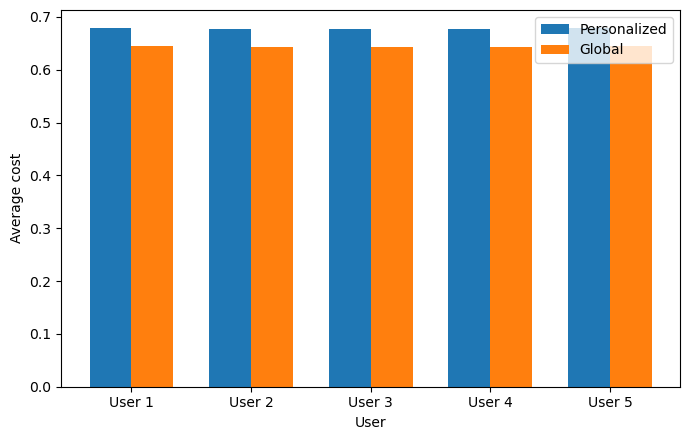

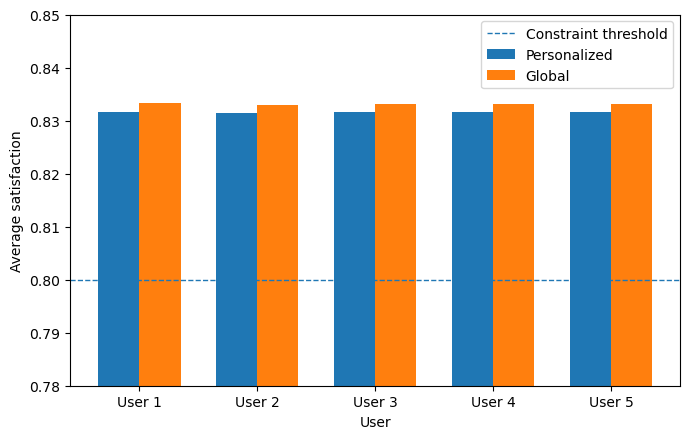

OVERALL PERSONALIZATION
Global cost:        0.643640
Personalized cost:  0.677648
Cost difference:    0.034008

Global satisfaction:       0.833109
Personalized satisfaction: 0.831582


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Personalization results already obtained from Experiment 5
# ---------------------------------------------------------

df = pd.DataFrame([
    [1, 0.678972, 0.644867, 0.831648, 0.833220],
    [2, 0.676885, 0.642527, 0.831497, 0.833009],
    [3, 0.677591, 0.643787, 0.831577, 0.833106],
    [4, 0.676666, 0.642592, 0.831589, 0.833105],
    [5, 0.678127, 0.644427, 0.831599, 0.833107],
], columns=[
    "user",
    "personalized_cost",
    "global_cost",
    "personalized_satisfaction",
    "global_satisfaction",
])

# ---------------------------------------------------------
# Figure 1: Cost by user
# ---------------------------------------------------------

x = np.arange(len(df))
width = 0.35

plt.figure(figsize=(7, 4.5))

plt.bar(
    x - width / 2,
    df["personalized_cost"],
    width,
    label="Personalized",
)

plt.bar(
    x + width / 2,
    df["global_cost"],
    width,
    label="Global",
)

plt.xticks(x, [f"User {u}" for u in df["user"]])
plt.xlabel("User")
plt.ylabel("Average cost")
plt.legend()
plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# Figure 2: Satisfaction by user
# ---------------------------------------------------------

plt.figure(figsize=(7, 4.5))

plt.bar(
    x - width / 2,
    df["personalized_satisfaction"],
    width,
    label="Personalized",
)

plt.bar(
    x + width / 2,
    df["global_satisfaction"],
    width,
    label="Global",
)

plt.axhline(
    0.8,
    linestyle="--",
    linewidth=1,
    label="Constraint threshold",
)

plt.xticks(x, [f"User {u}" for u in df["user"]])
plt.xlabel("User")
plt.ylabel("Average satisfaction")
plt.ylim(0.78, 0.85)
plt.legend()
plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# Overall results
# ---------------------------------------------------------

print("OVERALL PERSONALIZATION")
print(f"Global cost:        {df['global_cost'].mean():.6f}")
print(f"Personalized cost:  {df['personalized_cost'].mean():.6f}")
print(f"Cost difference:    "
      f"{df['personalized_cost'].mean() - df['global_cost'].mean():.6f}")
print()
print(f"Global satisfaction:       {df['global_satisfaction'].mean():.6f}")
print(f"Personalized satisfaction: {df['personalized_satisfaction'].mean():.6f}")

In [2]:
import os
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ================================================================
# REAL-LLM ROUTING POC
# ================================================================
#
# Five real LLMs are the complete action set.
#
# THERE IS NO FALLBACK.
#
# Each real LLM produces a six-dimensional quality vector:
#
#   [correctness,
#    relevance,
#    completeness,
#    clarity,
#    conciseness,
#    safety]
#
# These quality vectors are used as contextual features.
#
# The satisfaction model is:
#
#       Y_{t,a} ~ Bernoulli(theta*^T x_{t,a})
#
# where theta* is:
#
#   - unknown to the learner
#   - fixed throughout the experiment
#   - all coordinates strictly positive
#   - ||theta*||_2 = 1
#
# To ensure theta*^T x is always a valid probability, the
# quality vectors are normalized so that ||x||_2 <= 1.
#
# The learner only observes Y for the model it actually selects.
#
#
# MAIN POC FIGURES
# ----------------
#
# 1. Average cost vs epsilon
#
# 2. Mean satisfaction vs epsilon
#    with required satisfaction 1 - epsilon
#
# 3. Model-selection proportions vs epsilon
#    using 100% stacked bars
#
# ================================================================


# ================================================================
# PATHS
# ================================================================

DATA_DIR = (
    "/home/ameya-anjarlekar/"
    "llm-routing-poc/"
    "llm_routing_poc_data"
)

QUALITY_FILE = os.path.join(
    DATA_DIR,
    "parsed_quality_vectors.txt",
)

OUTPUT_DIR = os.path.join(
    DATA_DIR,
    "poc_results",
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True,
)


# ================================================================
# MODELS
# ================================================================

MODELS = [
    "nemotron-3-super-120b-a12b",
    "deepseek-v4-flash",
    "qwen3.6-35b-a3b",
    "gemma-4-31b-it",
    "qwen3.8-27b",
]

K = len(MODELS)


# ================================================================
# MODEL PARAMETER COUNTS
# ================================================================
#
# Costs are proportional to total parameter count.
#
# Nemotron: 120B
# DeepSeek: 284B
# Qwen3.6: 35B
# Gemma4: 30.7B
# Qwen3.8: 27B
#
# Normalized by the largest model.
# ================================================================

PARAM_COUNTS_B = np.array(
    [
        120.0,
        284.0,
        35.0,
        30.7,
        27.0,
    ],
    dtype=float,
)

COSTS = (
    PARAM_COUNTS_B
    / np.max(PARAM_COUNTS_B)
)


# ================================================================
# PROBLEM PARAMETERS
# ================================================================

D = 6

EPSILON = 0.20
DELTA = 0.05

S = 1.0

# ------------------------------------------------
# Reference eta.
#
# At epsilon = 0.20:
#
#     eta = 0.50
#
# For other epsilon:
#
#     eta(epsilon)
#       = 0.50 * epsilon / 0.20
#
# Hence:
#
#     epsilon = 0.20 -> eta = 0.500
#     epsilon = 0.25 -> eta = 0.625
#     epsilon = 0.30 -> eta = 0.750
#     epsilon = 0.35 -> eta = 0.875
#     epsilon = 0.40 -> eta = 1.000
#
# ------------------------------------------------

ETA_REFERENCE = 0.5

# ------------------------------------------------
# Rho reference.
# ------------------------------------------------

RHO_REFERENCE = 0.15

# ------------------------------------------------
# Reference horizon for rho scaling.
# ------------------------------------------------

T_REFERENCE = 100

# ------------------------------------------------
# Same empirical UCB scale as synthetic experiments.
# ------------------------------------------------

ALPHA_SCALE = 0.005

# ------------------------------------------------
# Regularization.
# ------------------------------------------------

BETA = 1.0

# ------------------------------------------------
# Confidence-radius parameter.
# ------------------------------------------------

ZETA = 2.5

# ------------------------------------------------
# Number of random query-order replays.
# ------------------------------------------------

N_TRIALS = 100

RANDOM_SEED = 12345


# ================================================================
# HIDDEN THETA*
# ================================================================
#
# We want:
#
#   1. Every coordinate > 0
#   2. ||theta*||_2 = 1
#
# We deliberately do NOT normalize theta to sum to 1.
#
# Because ||theta*||_2 = 1 and contexts satisfy ||x||_2 <= 1,
#
#       theta*^T x <= 1
#
# by Cauchy-Schwarz.
#
# ================================================================

THETA_STAR = np.array(
    [
        0.60,
        0.50,
        0.40,
        0.30,
        0.20,
        0.10,
    ],
    dtype=float,
)

THETA_STAR = (
    THETA_STAR
    / np.linalg.norm(THETA_STAR)
)


# ================================================================
# THETA* VALIDATION
# ================================================================

assert np.all(
    THETA_STAR > 0
)

assert np.isclose(
    np.linalg.norm(
        THETA_STAR
    ),
    1.0,
)

assert np.isclose(
    np.linalg.norm(
        THETA_STAR
    ),
    S,
)


# ================================================================
# ETA
# ================================================================

def compute_eta(
    epsilon,
):
    """
    Epsilon-dependent primal step size.

    Reference point:

        epsilon = 0.20
        eta     = 0.50

    Therefore:

        eta(epsilon)
            = 0.50 * epsilon / 0.20
    """

    return (
        ETA_REFERENCE
    )


# ================================================================
# RHO
# ================================================================

def compute_rho(
    T,
):

    return (
        RHO_REFERENCE
        * math.sqrt(
            T_REFERENCE / T
        )
    )


# ================================================================
# LOAD QUALITY VECTORS
# ================================================================

def load_quality_vectors(
    filename,
):
    """
    File format:

        Query Num/ID | Model Quality Vector / Scores
        0 | [1.0, 1.0, 0.3, 1.0, 0.5, 1.0]
        0 | [1.0, 1.0, 0.6, 1.0, 0.9, 1.0]
        ...

    Five consecutive rows correspond to the five models.

    Returns
    -------
    X:
        Normalized contextual vectors.
        Shape = (T, K, D)

    Y:
        Bernoulli satisfaction outcomes.
        Shape = (T, K)

    query_ids:
        Shape = (T,)

    probabilities:
        True Bernoulli probabilities.
        Shape = (T, K)

    X_raw:
        Original quality vectors.
        Shape = (T, K, D)
    """

    raw_rows = []

    query_ids = []

    # ------------------------------------------------------------
    # Read file.
    # ------------------------------------------------------------

    with open(
        filename,
        "r",
    ) as f:

        for line_number, line in enumerate(
            f,
            start=1,
        ):

            line = line.strip()

            if not line:
                continue

            if line.startswith("-"):
                continue

            if "|" not in line:
                continue

            left, right = line.split(
                "|",
                1,
            )

            left = left.strip()
            right = right.strip()

            # ----------------------------------------------------
            # Skip header.
            # ----------------------------------------------------

            if left.lower() in {
                "query num/id",
                "query num",
                "query id",
            }:
                continue

            # ----------------------------------------------------
            # Query ID.
            # ----------------------------------------------------

            try:

                query_id = int(left)

            except ValueError as e:

                raise ValueError(
                    f"Could not parse query ID on "
                    f"line {line_number}: {left!r}"
                ) from e

            # ----------------------------------------------------
            # Quality vector.
            # ----------------------------------------------------

            try:

                vector = json.loads(
                    right
                )

            except json.JSONDecodeError as e:

                raise ValueError(
                    f"Could not parse quality vector "
                    f"on line {line_number}: "
                    f"{right!r}"
                ) from e

            if not isinstance(
                vector,
                list,
            ):

                raise ValueError(
                    f"Line {line_number}: expected "
                    f"a list."
                )

            if len(vector) != D:

                raise ValueError(
                    f"Line {line_number}: expected "
                    f"{D} values, got "
                    f"{len(vector)}."
                )

            vector = np.asarray(
                vector,
                dtype=float,
            )

            raw_rows.append(
                vector
            )

            query_ids.append(
                query_id
            )

    # ------------------------------------------------------------
    # Basic validation.
    # ------------------------------------------------------------

    if len(raw_rows) == 0:

        raise ValueError(
            "No quality vectors found."
        )

    raw_rows = np.asarray(
        raw_rows,
        dtype=float,
    )

    query_ids = np.asarray(
        query_ids,
        dtype=int,
    )

    if len(raw_rows) % K != 0:

        raise ValueError(
            f"Found {len(raw_rows)} rows, "
            f"which is not divisible by "
            f"K={K}."
        )

    T = len(raw_rows) // K

    # ------------------------------------------------------------
    # Raw quality vectors.
    # ------------------------------------------------------------

    X_raw = raw_rows.reshape(
        T,
        K,
        D,
    )

    query_ids_matrix = query_ids.reshape(
        T,
        K,
    )

    # ------------------------------------------------------------
    # Verify query IDs.
    # ------------------------------------------------------------

    for t in range(T):

        if not np.all(
            query_ids_matrix[t]
            == query_ids_matrix[t, 0]
        ):

            raise ValueError(
                f"Query block {t} has inconsistent "
                f"IDs: {query_ids_matrix[t]}"
            )

    query_ids = (
        query_ids_matrix[:, 0]
    )

    # ------------------------------------------------------------
    # Validate raw quality scores.
    # ------------------------------------------------------------

    if not np.all(
        (X_raw >= 0.0)
        & (X_raw <= 1.0)
    ):

        bad = np.argwhere(
            (X_raw < 0.0)
            | (X_raw > 1.0)
        )[0]

        raise ValueError(
            f"Quality score outside [0,1] at "
            f"query={bad[0]}, "
            f"model={bad[1]}, "
            f"dimension={bad[2]}"
        )

    # ============================================================
    # CONTEXT NORMALIZATION
    # ============================================================
    #
    # Raw quality vector:
    #
    #       q in [0,1]^6
    #
    # We transform:
    #
    #       x = q / sqrt(D)
    #
    # Since ||q||_2 <= sqrt(D),
    #
    #       ||x||_2 <= 1.
    #
    # Therefore, because ||theta*||_2 = 1:
    #
    #       theta*^T x <= 1.
    #
    # ============================================================

    X = (
        X_raw
        / math.sqrt(D)
    )

    # ------------------------------------------------------------
    # Verify context norm.
    # ------------------------------------------------------------

    context_norms = np.linalg.norm(
        X,
        axis=2,
    )

    assert np.max(
        context_norms
    ) <= 1.0 + 1e-12

    # ============================================================
    # TRUE SATISFACTION PROBABILITIES
    # ============================================================

    probabilities = np.einsum(
        "d,tad->ta",
        THETA_STAR,
        X,
    )

    # ------------------------------------------------------------
    # Numerical validation.
    # ------------------------------------------------------------

    min_probability = np.min(
        probabilities
    )

    max_probability = np.max(
        probabilities
    )

    if min_probability < -1e-12:

        raise ValueError(
            "Negative Bernoulli probability "
            f"detected: {min_probability}"
        )

    if max_probability > 1.0 + 1e-12:

        raise ValueError(
            "Bernoulli probability > 1 detected: "
            f"{max_probability}"
        )

    probabilities = np.clip(
        probabilities,
        0.0,
        1.0,
    )

    # ============================================================
    # GENERATE OBSERVED Y
    # ============================================================
    #
    # Each query-model pair gets:
    #
    #       Y_{t,a} ~ Bernoulli(p_{t,a})
    #
    # This is generated ONCE.
    #
    # The same realized Y matrix is then used across all
    # query-order replay trials.
    #
    # ============================================================

    rng = np.random.default_rng(
        RANDOM_SEED
    )

    Y = (
        rng.random(
            size=probabilities.shape
        )
        < probabilities
    ).astype(int)

    return (
        X,
        Y,
        query_ids,
        probabilities,
        X_raw,
    )


# ================================================================
# PRINT THETA*
# ================================================================

def print_theta_information():

    print()
    print("=" * 80)
    print("HIDDEN THETA*")
    print("=" * 80)

    print(
        "theta* =",
        THETA_STAR,
    )

    print(
        "||theta*|| =",
        np.linalg.norm(
            THETA_STAR
        ),
    )

    print(
        "all coordinates positive =",
        np.all(
            THETA_STAR > 0
        ),
    )

    print(
        "S =",
        S,
    )


# ================================================================
# COMPUTE KAPPA
# ================================================================

def compute_kappa():

    return 1.0


# ================================================================
# THEORETICAL ALPHA
# ================================================================

def compute_theoretical_alpha(
    t,
):

    if t <= 0:
        t = 1

    L = 1.0

    kappa = compute_kappa()

    delta_E = (
        t ** (-ZETA)
    )

    term1 = (
        0.5
        * math.sqrt(
            D
            * math.log(
                1.0
                + (
                    t
                    * L
                    * L
                    / (D * BETA)
                )
            )
            + 2.0
            * math.log(
                2.0 / delta_E
            )
        )
    )

    term2 = (
        math.sqrt(BETA)
        * S
    )

    alpha = (
        term1
        + term2
    ) / kappa

    return alpha


# ================================================================
# COMPUTE UCB
# ================================================================

def compute_ucbs(
    X_t,
    theta_hat,
    V_inv,
    t,
):
    """
    Linear Bernoulli model:

        p = theta^T x

    Therefore:

        UCB = x^T theta_hat
              + alpha ||x||_{V^{-1}}.

    The UCB itself is intentionally NOT clipped.
    """

    alpha = (
        ALPHA_SCALE
        * compute_theoretical_alpha(
            t
        )
    )

    ucbs = np.zeros(K)

    for a in range(K):

        x = X_t[a]

        mean = float(
            np.dot(
                x,
                theta_hat,
            )
        )

        # Mean probability must lie in [0,1].
        mean = np.clip(
            mean,
            0.0,
            1.0,
        )

        uncertainty = math.sqrt(
            max(
                0.0,
                np.dot(
                    x,
                    np.dot(
                        V_inv,
                        x,
                    ),
                ),
            )
        )

        # --------------------------------------------------------
        # IMPORTANT:
        # UCB is intentionally NOT clipped at 1.
        # --------------------------------------------------------

        ucbs[a] = (
            mean
            + alpha
            * uncertainty
        )

    return ucbs


# ================================================================
# SINGLE ONLINE TRIAL
# ================================================================

def run_online_trial(
    X,
    Y,
    epsilon,
    delta,
    query_order,
    use_queue=True,
):
    """
    Online routing with partial feedback.

    The learner only observes Y for the selected action.

    There is no fallback.
    """

    T = len(
        query_order
    )

    # ------------------------------------------------------------
    # Epsilon-dependent eta.
    # ------------------------------------------------------------

    eta = compute_eta(
        epsilon
    )

    # ------------------------------------------------------------
    # Horizon-scaled rho.
    # ------------------------------------------------------------

    rho = compute_rho(
        T
    )

    # ------------------------------------------------------------
    # Regularized design matrix.
    # ------------------------------------------------------------

    V = (
        BETA
        * np.eye(D)
    )

    b = np.zeros(D)

    theta_hat = np.zeros(D)

    # ------------------------------------------------------------
    # Dual queue.
    # ------------------------------------------------------------

    lam = 0.0

    # ------------------------------------------------------------
    # Logging.
    # ------------------------------------------------------------

    selected_actions = np.zeros(
        T,
        dtype=int,
    )

    observed_y = np.zeros(
        T,
        dtype=int,
    )

    observed_cost = np.zeros(
        T,
        dtype=float,
    )

    lambda_history = np.zeros(T)

    satisfaction_history = np.zeros(T)

    cost_history = np.zeros(T)

    ucb_history = np.zeros(
        (T, K)
    )

    # ============================================================
    # ONLINE LOOP
    # ============================================================

    for t_idx in range(T):

        t = t_idx + 1

        query_idx = (
            query_order[t_idx]
        )

        X_t = X[query_idx]

        # --------------------------------------------------------
        # Confidence matrix.
        # --------------------------------------------------------

        V_inv = np.linalg.inv(
            V
        )

        # --------------------------------------------------------
        # Compute UCB.
        # --------------------------------------------------------

        ucbs = compute_ucbs(
            X_t=X_t,
            theta_hat=theta_hat,
            V_inv=V_inv,
            t=t,
        )

        ucb_history[
            t_idx
        ] = ucbs

        # --------------------------------------------------------
        # Primal-dual action selection.
        #
        #       argmin_a
        #           c(a) - lambda_t UCB(a)
        #
        # NO FALLBACK.
        # --------------------------------------------------------

        if use_queue:

            multiplier = lam

        else:

            # No-queue ablation.
            multiplier = 1.0

        scores = (
            COSTS
            - multiplier
            * ucbs
        )

        action = int(
            np.argmin(scores)
        )

        # --------------------------------------------------------
        # Observe ONLY selected action.
        # --------------------------------------------------------

        y = int(
            Y[
                query_idx,
                action,
            ]
        )

        cost = float(
            COSTS[action]
        )

        selected_actions[
            t_idx
        ] = action

        observed_y[
            t_idx
        ] = y

        observed_cost[
            t_idx
        ] = cost

        # --------------------------------------------------------
        # Dual queue update.
        # --------------------------------------------------------

        if use_queue:

            lam = max(
                0.0,
                lam
                + eta
                * (
                    (1.0 - epsilon)
                    + rho
                    - y
                ),
            )

        lambda_history[
            t_idx
        ] = lam

        # --------------------------------------------------------
        # Update linear estimator using ONLY selected action.
        # --------------------------------------------------------

        x_selected = X_t[
            action
        ]

        V += np.outer(
            x_selected,
            x_selected,
        )

        b += (
            y
            * x_selected
        )

        theta_hat = np.linalg.solve(
            V,
            b,
        )

        # --------------------------------------------------------
        # Log.
        # --------------------------------------------------------

        satisfaction_history[
            t_idx
        ] = y

        cost_history[
            t_idx
        ] = cost

    # ============================================================
    # AGGREGATES
    # ============================================================

    avg_satisfaction = float(
        np.mean(
            observed_y
        )
    )

    avg_cost = float(
        np.mean(
            observed_cost
        )
    )

    required_satisfaction = (
        1.0 - epsilon
    )

    constraint_satisfied = (
        avg_satisfaction
        >= required_satisfaction
    )

    usage_counts = np.bincount(
        selected_actions,
        minlength=K,
    )

    usage_frequency = (
        usage_counts
        / T
    )

    return {
        "avg_satisfaction":
            avg_satisfaction,

        "avg_cost":
            avg_cost,

        "required_satisfaction":
            required_satisfaction,

        "constraint_satisfied":
            bool(
                constraint_satisfied
            ),

        "selected_actions":
            selected_actions,

        "observed_y":
            observed_y,

        "observed_cost":
            observed_cost,

        "lambda_history":
            lambda_history,

        "satisfaction_history":
            satisfaction_history,

        "cost_history":
            cost_history,

        "ucb_history":
            ucb_history,

        "usage_counts":
            usage_counts,

        "usage_frequency":
            usage_frequency,

        "eta":
            eta,

        "rho":
            rho,

        "final_theta_hat":
            theta_hat,
    }


# ================================================================
# RUN MULTIPLE QUERY-ORDER REPLAYS
# ================================================================

def run_replays(
    X,
    Y,
    epsilon,
    delta,
    n_trials=N_TRIALS,
):

    T = X.shape[0]

    rng = np.random.default_rng(
        RANDOM_SEED + 1
    )

    results = []

    for trial in range(
        n_trials
    ):

        query_order = (
            rng.permutation(T)
        )

        result = run_online_trial(
            X=X,
            Y=Y,
            epsilon=epsilon,
            delta=delta,
            query_order=query_order,
            use_queue=True,
        )

        result["trial"] = (
            trial
        )

        results.append(
            result
        )

    return results


# ================================================================
# SUMMARIZE REPLAYS
# ================================================================

def summarize_replays(
    results,
):

    satisfaction = np.array(
        [
            r["avg_satisfaction"]
            for r in results
        ]
    )

    costs = np.array(
        [
            r["avg_cost"]
            for r in results
        ]
    )

    feasible = np.array(
        [
            r[
                "constraint_satisfied"
            ]
            for r in results
        ],
        dtype=float,
    )

    usage = np.array(
        [
            r["usage_frequency"]
            for r in results
        ]
    )

    return {
        "mean_satisfaction":
            float(
                np.mean(
                    satisfaction
                )
            ),

        "std_satisfaction":
            float(
                np.std(
                    satisfaction,
                    ddof=1,
                )
            ),

        "mean_cost":
            float(
                np.mean(
                    costs
                )
            ),

        "std_cost":
            float(
                np.std(
                    costs,
                    ddof=1,
                )
            ),

        "constraint_probability":
            float(
                np.mean(
                    feasible
                )
            ),

        "mean_usage":
            np.mean(
                usage,
                axis=0,
            ),

        "std_usage":
            np.std(
                usage,
                axis=0,
                ddof=1,
            ),
    }


# ================================================================
# DEFAULT POC
# ================================================================

def run_default_poc(
    X,
    Y,
    true_probabilities,
):

    T = X.shape[0]

    print()
    print("=" * 80)
    print("REAL-LLM POC")
    print("=" * 80)

    print()
    print(
        "Number of queries:",
        T,
    )

    print(
        "Number of models:",
        K,
    )

    print(
        "Feature dimension:",
        D,
    )

    print()
    print(
        "Models and costs:"
    )

    for a, model in enumerate(
        MODELS
    ):

        print(
            f"  {a}: "
            f"{model:35s} "
            f"params={PARAM_COUNTS_B[a]:6.1f}B "
            f"cost={COSTS[a]:.6f}"
        )

    print()
    print(
        "epsilon =",
        EPSILON,
    )

    print(
        "delta   =",
        DELTA,
    )

    print()
    print(
        "eta =",
        compute_eta(
            EPSILON
        ),
    )

    print(
        "rho =",
        compute_rho(
            T
        ),
    )

    # ------------------------------------------------------------
    # True satisfaction probabilities.
    # ------------------------------------------------------------

    print()
    print(
        "True mean satisfaction probabilities:"
    )

    for a, model in enumerate(
        MODELS
    ):

        print(
            f"  {model:35s}: "
            f"{np.mean(true_probabilities[:, a]):.4f}"
        )

    print()
    print(
        "Overall true mean probability:",
        f"{np.mean(true_probabilities):.4f}",
    )

    # ------------------------------------------------------------
    # Realized Y.
    # ------------------------------------------------------------

    print()
    print(
        "Overall realized Bernoulli "
        "satisfaction:",
        f"{np.mean(Y):.4f}",
    )

    # ------------------------------------------------------------
    # Replays.
    # ------------------------------------------------------------

    results = run_replays(
        X=X,
        Y=Y,
        epsilon=EPSILON,
        delta=DELTA,
        n_trials=N_TRIALS,
    )

    summary = summarize_replays(
        results
    )

    # ------------------------------------------------------------
    # Results.
    # ------------------------------------------------------------

    print()
    print("-" * 80)
    print("DEFAULT RESULT")
    print("-" * 80)

    print(
        "Average satisfaction:",
        f"{summary['mean_satisfaction']:.4f}",
    )

    print(
        "Required satisfaction:",
        f"{1.0 - EPSILON:.4f}",
    )

    print(
        "Average cost:",
        f"{summary['mean_cost']:.4f}",
    )

    print(
        "Fraction of query-order replays "
        "satisfying target:",
        f"{summary['constraint_probability']:.4f}",
    )

    # ------------------------------------------------------------
    # Save trial CSV.
    # ------------------------------------------------------------

    rows = []

    for result in results:

        row = {
            "trial":
                result["trial"],

            "avg_satisfaction":
                result[
                    "avg_satisfaction"
                ],

            "avg_cost":
                result[
                    "avg_cost"
                ],

            "required_satisfaction":
                result[
                    "required_satisfaction"
                ],

            "constraint_satisfied":
                result[
                    "constraint_satisfied"
                ],
        }

        for a, model in enumerate(
            MODELS
        ):

            row[
                f"usage_{model}"
            ] = result[
                "usage_frequency"
            ][a]

        rows.append(
            row
        )

    df = pd.DataFrame(
        rows
    )

    output_file = os.path.join(
        OUTPUT_DIR,
        "poc_default_trials.csv",
    )

    df.to_csv(
        output_file,
        index=False,
    )

    print()
    print(
        "Saved:",
        output_file,
    )

    return (
        results,
        summary,
    )


# ================================================================
# EPSILON SWEEP
# ================================================================

def run_epsilon_sweep(
    X,
    Y,
):

    epsilon_values = [0.1,
        0.15,
        0.20,
        0.25,
        0.30,
        0.35,
        0.40,
    ]

    rows = []

    print()
    print("=" * 80)
    print("EPSILON SWEEP")
    print("=" * 80)

    for epsilon in (
        epsilon_values
    ):

        eta = compute_eta(
            epsilon
        )

        print(
            f"Running epsilon={epsilon:.2f} "
            f"(eta={eta:.4f})"
        )

        results = run_replays(
            X=X,
            Y=Y,
            epsilon=epsilon,
            delta=DELTA,
            n_trials=N_TRIALS,
        )

        summary = summarize_replays(
            results
        )

        row = {
            "epsilon":
                epsilon,

            "eta":
                eta,

            "required_satisfaction":
                1.0 - epsilon,

            "mean_satisfaction":
                summary[
                    "mean_satisfaction"
                ],

            "std_satisfaction":
                summary[
                    "std_satisfaction"
                ],

            "mean_cost":
                summary[
                    "mean_cost"
                ],

            "std_cost":
                summary[
                    "std_cost"
                ],

            "constraint_probability":
                summary[
                    "constraint_probability"
                ],
        }

        # --------------------------------------------------------
        # Model selection proportions.
        # --------------------------------------------------------

        for a, model in enumerate(
            MODELS
        ):

            row[
                f"usage_{model}"
            ] = summary[
                "mean_usage"
            ][a]

        rows.append(
            row
        )

    df = pd.DataFrame(
        rows
    )

    output_file = os.path.join(
        OUTPUT_DIR,
        "poc_epsilon_sweep.csv",
    )

    df.to_csv(
        output_file,
        index=False,
    )

    print()
    print(df)

    print()
    print(
        "Saved:",
        output_file,
    )

    return df


# ================================================================
# FIGURE 1:
# AVERAGE COST VS EPSILON
# ================================================================

def plot_epsilon_cost(
    df,
):

    plt.figure(
        figsize=(8, 5)
    )

    plt.plot(
        df["epsilon"],
        df["mean_cost"],
        marker="o",
        linewidth=2,
    )

    plt.xlabel(
        r"$\epsilon$"
    )

    plt.ylabel(
        "Average cost"
    )

    plt.title(
        "Average Routing Cost vs. Constraint"
    )

    plt.xticks(
        df["epsilon"]
    )

    plt.grid(
        alpha=0.25
    )

    plt.tight_layout()

    output_file = os.path.join(
        OUTPUT_DIR,
        "poc_cost_vs_epsilon.png",
    )

    plt.savefig(
        output_file,
        dpi=300,
        bbox_inches="tight",
    )

    plt.close()

    print(
        "Saved:",
        output_file,
    )


# ================================================================
# FIGURE 2:
# MEAN SATISFACTION VS EPSILON
# ================================================================

def plot_epsilon_satisfaction(
    df,
):

    plt.figure(
        figsize=(8, 5)
    )

    # ------------------------------------------------------------
    # Mean satisfaction.
    # ------------------------------------------------------------

    plt.plot(
        df["epsilon"],
        df["mean_satisfaction"],
        marker="o",
        linewidth=2,
        label="Mean satisfaction",
    )

    # ------------------------------------------------------------
    # Required satisfaction.
    # ------------------------------------------------------------

    plt.plot(
        df["epsilon"],
        df[
            "required_satisfaction"
        ],
        marker="s",
        linestyle="--",
        linewidth=1.5,
        label=r"Required $1-\epsilon$",
    )

    plt.xlabel(
        r"$\epsilon$"
    )

    plt.ylabel(
        "Satisfaction"
    )

    plt.title(
        "Mean Satisfaction vs. Constraint"
    )

    plt.xticks(
        df["epsilon"]
    )

    plt.ylim(
        0,
        1.05,
    )

    plt.grid(
        alpha=0.25
    )

    plt.legend()

    plt.tight_layout()

    output_file = os.path.join(
        OUTPUT_DIR,
        "poc_satisfaction_vs_epsilon.png",
    )

    plt.savefig(
        output_file,
        dpi=300,
        bbox_inches="tight",
    )

    plt.close()

    print(
        "Saved:",
        output_file,
    )


# ================================================================
# FIGURE 3:
# MODEL SELECTION PROPORTIONS VS EPSILON
# ================================================================
#
# Each epsilon gets one bar.
#
# Each bar sums to 100%.
#
# The segments show the fraction of queries routed to each model.
#
# ================================================================

def plot_model_selection_vs_epsilon(df):
    model_labels = [
        "Nemotron",
        "DeepSeek",
        "Qwen3.6",
        "Gemma4",
        "Qwen3.8",
    ]

    model_usage_columns = [
        f"usage_{model}" for model in MODELS
    ]

    fig, ax = plt.subplots(figsize=(11, 6))

    bottom = np.zeros(len(df))
    x = np.arange(len(df))

    # ------------------------------------------------------------
    # 100% stacked bars
    # ------------------------------------------------------------
    for model_label, usage_column in zip(
        model_labels,
        model_usage_columns,
    ):
        values = df[usage_column].to_numpy() * 100.0

        ax.bar(
            x,
            values,
            bottom=bottom,
            label=model_label,
            width=0.65,
        )

        bottom += values

    # ------------------------------------------------------------
    # Axes
    # ------------------------------------------------------------
    ax.set_xlabel(r"$\epsilon$")
    ax.set_ylabel("Model selection proportion (%)")
    ax.set_title("Model Selection vs. Constraint")

    ax.set_xticks(x)
    ax.set_xticklabels(
        [f"{epsilon:.2f}" for epsilon in df["epsilon"]]
    )

    ax.set_ylim(0, 100)
    ax.set_yticks(np.arange(0, 101, 20))

    ax.grid(
        axis="y",
        alpha=0.25,
    )

    # ------------------------------------------------------------
    # Percentage table below the plot
    # ------------------------------------------------------------
    table_data = []

    for model_label, usage_column in zip(
        model_labels,
        model_usage_columns,
    ):
        values = df[usage_column].to_numpy() * 100.0

        table_data.append([
            f"{v:.1f}%" if v >= 0.05 else "<0.1%"
            for v in values
        ])

    table = ax.table(
        cellText=table_data,
        rowLabels=model_labels,
        colLabels=[
            f"$\\epsilon$={epsilon:.2f}"
            for epsilon in df["epsilon"]
        ],
        cellLoc="center",
        rowLoc="center",
        loc="bottom",
        bbox=[0.0, -0.48, 1.0, 0.38],
    )

    table.auto_set_font_size(False)
    table.set_fontsize(8)

    # ------------------------------------------------------------
    # Legend
    # ------------------------------------------------------------
    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.56),
        ncol=5,
        frameon=False,
    )

    plt.subplots_adjust(
        bottom=0.38,
        top=0.90,
        left=0.10,
        right=0.98,
    )

    output_path = os.path.join(
        OUTPUT_DIR,
        "poc_model_selection_vs_epsilon.png",
    )

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.close()

    return output_path

# ================================================================
# MAIN POC FIGURES
# ================================================================

def plot_main_poc_figures(
    epsilon_df,
):

    print()
    print("=" * 80)
    print("GENERATING MAIN POC FIGURES")
    print("=" * 80)

    # Figure 1.
    plot_epsilon_cost(
        epsilon_df
    )

    # Figure 2.
    plot_epsilon_satisfaction(
        epsilon_df
    )

    # Figure 3.
    plot_model_selection_vs_epsilon(
        epsilon_df
    )


# ================================================================
# MAIN
# ================================================================

def main():

    # ============================================================
    # LOAD DATA
    # ============================================================

    print()
    print("=" * 80)
    print("LOADING REAL-LLM DATA")
    print("=" * 80)

    (
        X,
        Y,
        query_ids,
        true_probabilities,
        X_raw,
    ) = load_quality_vectors(
        QUALITY_FILE
    )

    T = X.shape[0]

    print(
        "X shape:",
        X.shape,
    )

    print(
        "Y shape:",
        Y.shape,
    )

    print(
        "Number of queries:",
        T,
    )

    print(
        "Number of models:",
        K,
    )

    print(
        "Feature dimension:",
        D,
    )

    # ============================================================
    # VALIDATE
    # ============================================================

    assert X.shape == (
        T,
        K,
        D,
    )

    assert Y.shape == (
        T,
        K,
    )

    assert np.all(
        X >= 0.0
    )

    assert np.all(
        X <= 1.0
    )

    assert np.all(
        (Y == 0)
        | (Y == 1)
    )

    # ------------------------------------------------------------
    # Context norm.
    # ------------------------------------------------------------

    context_norms = np.linalg.norm(
        X,
        axis=2,
    )

    assert np.max(
        context_norms
    ) <= 1.0 + 1e-12

    # ------------------------------------------------------------
    # True probabilities.
    # ------------------------------------------------------------

    assert np.min(
        true_probabilities
    ) >= -1e-12

    assert np.max(
        true_probabilities
    ) <= 1.0 + 1e-12

    # ============================================================
    # THETA
    # ============================================================

    print_theta_information()

    # ============================================================
    # DATA-GENERATING PROCESS
    # ============================================================

    print()
    print("=" * 80)
    print("DATA-GENERATING PROCESS")
    print("=" * 80)

    print()
    print(
        "Context transformation:"
    )

    print(
        "x = raw_quality_vector / sqrt(6)"
    )

    print()
    print(
        "Satisfaction model:"
    )

    print(
        "Y[t,a] ~ Bernoulli(theta*^T x[t,a])"
    )

    print()
    print(
        "Maximum context norm:",
        f"{np.max(context_norms):.6f}",
    )

    print(
        "Maximum true probability:",
        f"{np.max(true_probabilities):.6f}",
    )

    print(
        "Minimum true probability:",
        f"{np.min(true_probabilities):.6f}",
    )

    # ============================================================
    # TRUE MODEL STATISTICS
    # ============================================================

    print()
    print("=" * 80)
    print("TRUE SATISFACTION PROBABILITIES")
    print("=" * 80)

    for a, model in enumerate(
        MODELS
    ):

        print(
            f"{model:35s}: "
            f"{np.mean(true_probabilities[:, a]):.4f}"
        )

    print()
    print(
        "Overall:",
        f"{np.mean(true_probabilities):.4f}",
    )

    print()
    print(
        "Realized Bernoulli Y:"
    )

    for a, model in enumerate(
        MODELS
    ):

        print(
            f"{model:35s}: "
            f"{np.mean(Y[:, a]):.4f}"
        )

    print()
    print(
        "Overall:",
        f"{np.mean(Y):.4f}",
    )

    # ============================================================
    # DEFAULT POC
    # ============================================================

    (
        default_results,
        default_summary,
    ) = run_default_poc(
        X=X,
        Y=Y,
        true_probabilities=
            true_probabilities,
    )

    # ============================================================
    # EPSILON SWEEP
    # ============================================================

    epsilon_df = (
        run_epsilon_sweep(
            X=X,
            Y=Y,
        )
    )

    # ============================================================
    # MAIN POC FIGURES
    # ============================================================

    plot_main_poc_figures(
        epsilon_df
    )

    # ============================================================
    # SAVE CONFIGURATION
    # ============================================================

    config = {
        "models":
            MODELS,

        "parameter_counts_B":
            PARAM_COUNTS_B.tolist(),

        "costs":
            COSTS.tolist(),

        "D":
            D,

        "epsilon":
            EPSILON,

        "delta":
            DELTA,

        "epsilon_sweep":
            [0.1,0.15,
                0.20,
                0.25,
                0.30,
                0.35,
                0.40,
            ],

        "T":
            int(T),

        "N_TRIALS":
            N_TRIALS,

        "eta_reference":
            ETA_REFERENCE,

        "eta_rule":
            "eta(epsilon) = ETA_REFERENCE * epsilon / EPSILON",

        "rho_reference":
            RHO_REFERENCE,

        "T_reference":
            T_REFERENCE,

        "alpha_scale":
            ALPHA_SCALE,

        "beta":
            BETA,

        "S":
            S,

        "theta_star":
            THETA_STAR.tolist(),

        "theta_star_norm":
            float(
                np.linalg.norm(
                    THETA_STAR
                )
            ),

        "theta_star_all_positive":
            bool(
                np.all(
                    THETA_STAR > 0
                )
            ),

        "context_normalization":
            "x = raw_quality_vector / sqrt(D)",

        "satisfaction_model":
            "Y ~ Bernoulli(theta_star^T x)",

        "fallback":
            False,

        "main_figures": [
            "poc_cost_vs_epsilon.png",
            "poc_satisfaction_vs_epsilon.png",
            "poc_model_selection_vs_epsilon.png",
        ],
    }

    config_file = os.path.join(
        OUTPUT_DIR,
        "poc_config.json",
    )

    with open(
        config_file,
        "w",
    ) as f:

        json.dump(
            config,
            f,
            indent=2,
        )

    # ============================================================
    # FINISHED
    # ============================================================

    print()
    print("=" * 80)
    print("POC COMPLETE")
    print("=" * 80)

    print()
    print(
        "Results directory:",
        OUTPUT_DIR,
    )

    print()
    print("Generated:")

    print(
        "  poc_default_trials.csv"
    )

    print(
        "  poc_epsilon_sweep.csv"
    )

    print(
        "  poc_cost_vs_epsilon.png"
    )

    print(
        "  poc_satisfaction_vs_epsilon.png"
    )

    print(
        "  poc_model_selection_vs_epsilon.png"
    )

    print(
        "  poc_config.json"
    )


# ================================================================
# RUN
# ================================================================

if __name__ == "__main__":
    main()


LOADING REAL-LLM DATA
X shape: (100, 5, 6)
Y shape: (100, 5)
Number of queries: 100
Number of models: 5
Feature dimension: 6

HIDDEN THETA*
theta* = [0.6289709  0.52414242 0.41931393 0.31448545 0.20965697 0.10482848]
||theta*|| = 1.0
all coordinates positive = True
S = 1.0

DATA-GENERATING PROCESS

Context transformation:
x = raw_quality_vector / sqrt(6)

Satisfaction model:
Y[t,a] ~ Bernoulli(theta*^T x[t,a])

Maximum context norm: 1.000000
Maximum true probability: 0.898717
Minimum true probability: 0.000000

TRUE SATISFACTION PROBABILITIES
nemotron-3-super-120b-a12b         : 0.5164
deepseek-v4-flash                  : 0.8103
qwen3.6-35b-a3b                    : 0.0894
gemma-4-31b-it                     : 0.8480
qwen3.8-27b                        : 0.1156

Overall: 0.4759

Realized Bernoulli Y:
nemotron-3-super-120b-a12b         : 0.5200
deepseek-v4-flash                  : 0.8500
qwen3.6-35b-a3b                    : 0.0900
gemma-4-31b-it                     : 0.8500
qwen3.8-27b   


ABLATION RESULTS USED FOR PLOTTING
  method  mean_cost  mean_satisfaction  constraint_probability  fallback_rate
    Ours   0.624457           0.828694                     1.0       0.515860
No-Queue   0.122640           0.624829                     0.0       0.000000
  No-Rho   0.512277           0.782562                     0.0       0.381221


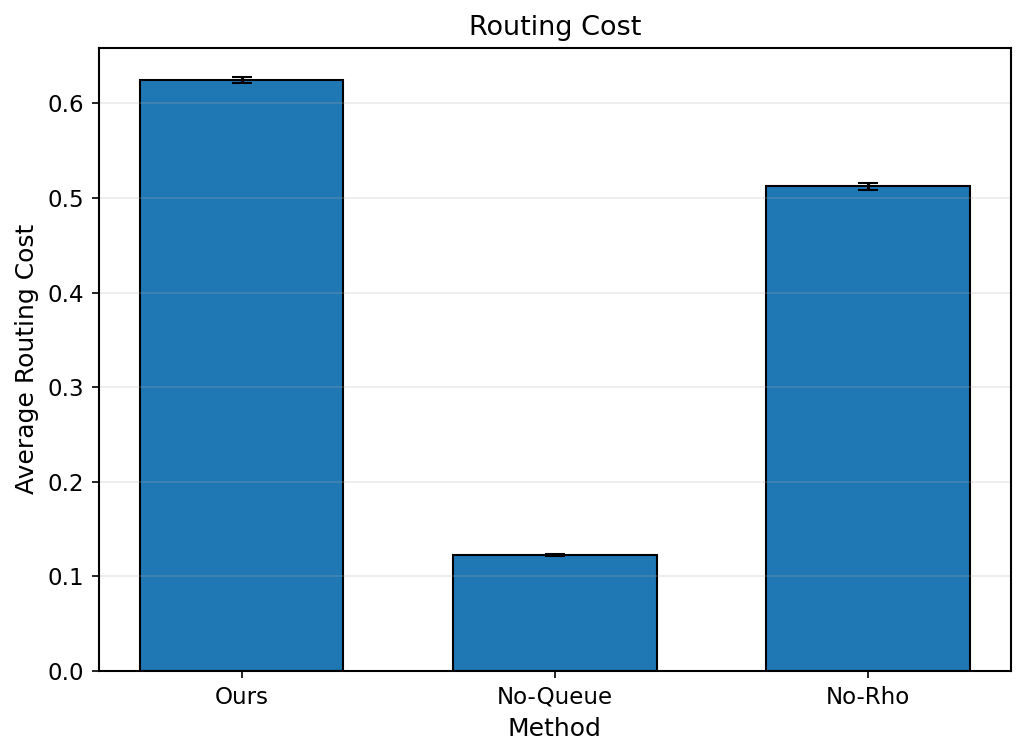

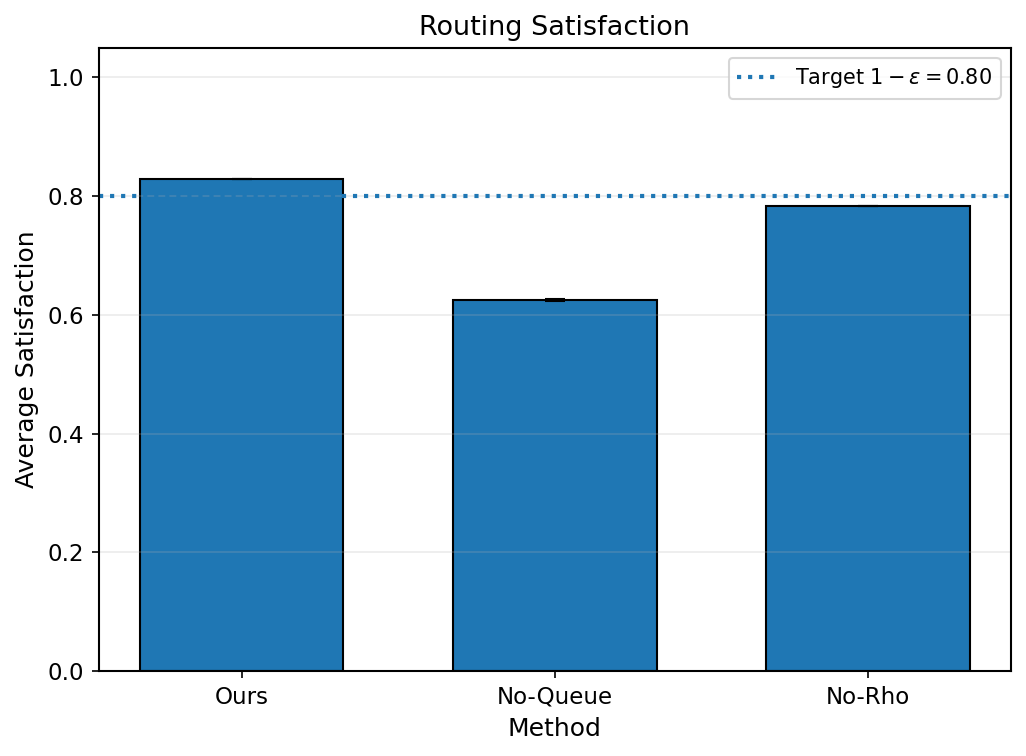

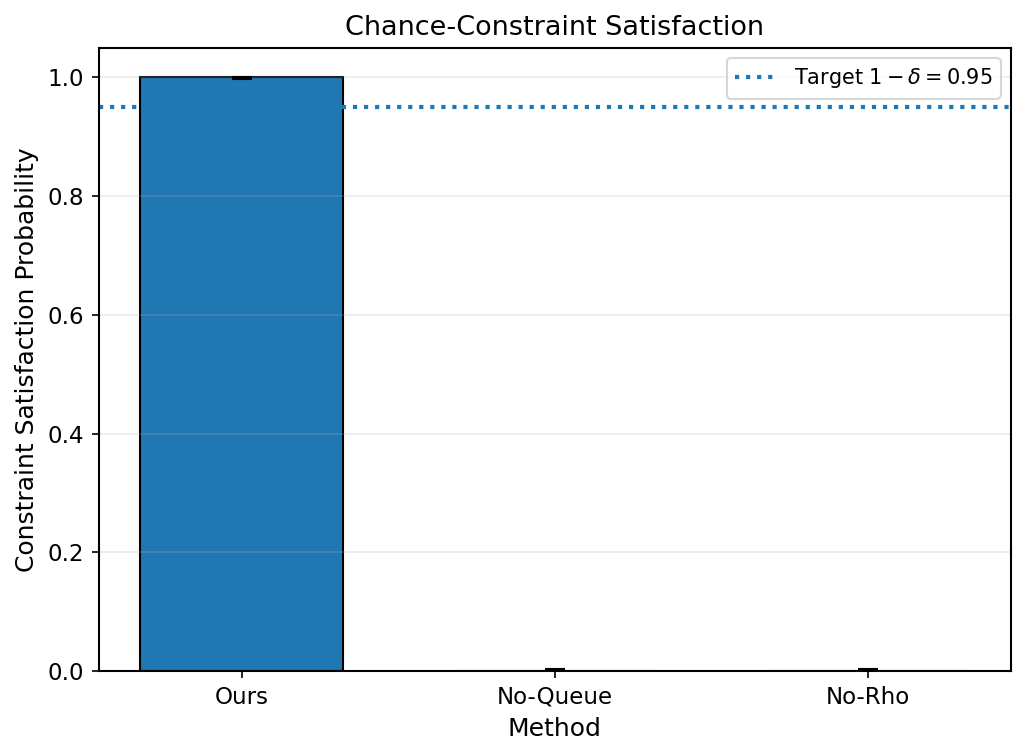


FIGURES SAVED
/home/ameya-anjarlekar/Documents/LLM Routing/icml_llm_routing_results/errorbars/ablation_cost.pdf
/home/ameya-anjarlekar/Documents/LLM Routing/icml_llm_routing_results/errorbars/ablation_satisfaction.pdf
/home/ameya-anjarlekar/Documents/LLM Routing/icml_llm_routing_results/errorbars/ablation_constraint_probability.pdf

PNG versions also saved at 600 DPI.


In [11]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ================================================================
# CONFIG
# ================================================================

BASE_DIR = "/home/ameya-anjarlekar/Documents/LLM Routing/icml_llm_routing_results/errorbars"
CSV_PATH = os.path.join(BASE_DIR, "ablation_errorbars.csv")

EPSILON = 0.20
DELTA = 0.05


# ================================================================
# PAPER-READY MATPLOTLIB SETTINGS
# ================================================================

plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 10,
    "figure.dpi": 150,
    "savefig.bbox": "tight",
})


# ================================================================
# LOAD DATA
# ================================================================

df = pd.read_csv(CSV_PATH)

# Main-paper ablation methods
METHOD_ORDER = [
    "Ours",
    "No-Queue",
    "No-Rho"
]

df_plot = df[df["method"].isin(METHOD_ORDER)].copy()

# Explicit ordering
df_plot["method"] = pd.Categorical(
    df_plot["method"],
    categories=METHOD_ORDER,
    ordered=True
)

df_plot = df_plot.sort_values("method").reset_index(drop=True)

x = np.arange(len(df_plot))


# ================================================================
# PRINT DATA
# ================================================================

print("\n================================================")
print("ABLATION RESULTS USED FOR PLOTTING")
print("================================================")

print(
    df_plot[
        [
            "method",
            "mean_cost",
            "mean_satisfaction",
            "constraint_probability",
            "fallback_rate"
        ]
    ].to_string(index=False)
)


# ================================================================
# HELPER: ERROR BARS
# ================================================================

def asymmetric_error(df, mean_col, low_col, high_col):
    lower = df[mean_col].to_numpy() - df[low_col].to_numpy()
    upper = df[high_col].to_numpy() - df[mean_col].to_numpy()

    return np.vstack([lower, upper])


# ================================================================
# 1. ROUTING COST
# ================================================================

fig, ax = plt.subplots(figsize=(7, 5.2))

ax.bar(
    x,
    df_plot["mean_cost"],
    width=0.65,
    yerr=asymmetric_error(
        df_plot,
        "mean_cost",
        "cost_ci95_low",
        "cost_ci95_high"
    ),
    capsize=5,
    edgecolor="black",
    linewidth=1,
)

ax.set_xticks(x)
ax.set_xticklabels(df_plot["method"])

ax.set_xlabel("Method")
ax.set_ylabel("Average Routing Cost")
ax.set_title("Routing Cost")

ax.grid(
    axis="y",
    alpha=0.25
)

fig.tight_layout()

fig.savefig(
    os.path.join(BASE_DIR, "ablation_cost.pdf")
)

fig.savefig(
    os.path.join(BASE_DIR, "ablation_cost.png"),
    dpi=600
)

plt.show()
plt.close(fig)


# ================================================================
# 2. SATISFACTION
# ================================================================

fig, ax = plt.subplots(figsize=(7, 5.2))

ax.bar(
    x,
    df_plot["mean_satisfaction"],
    width=0.65,
    yerr=asymmetric_error(
        df_plot,
        "mean_satisfaction",
        "satisfaction_ci95_low",
        "satisfaction_ci95_high"
    ),
    capsize=5,
    edgecolor="black",
    linewidth=1,
)

# Required satisfaction level
ax.axhline(
    1 - EPSILON,
    linestyle=":",
    linewidth=2,
    label=fr"Target $1-\epsilon={1-EPSILON:.2f}$"
)

ax.set_xticks(x)
ax.set_xticklabels(df_plot["method"])

ax.set_xlabel("Method")
ax.set_ylabel("Average Satisfaction")
ax.set_title("Routing Satisfaction")

ax.set_ylim(0, 1.05)

ax.grid(
    axis="y",
    alpha=0.25
)

ax.legend()

fig.tight_layout()

fig.savefig(
    os.path.join(BASE_DIR, "ablation_satisfaction.pdf")
)

fig.savefig(
    os.path.join(BASE_DIR, "ablation_satisfaction.png"),
    dpi=600
)

plt.show()
plt.close(fig)


# ================================================================
# 3. CHANCE-CONSTRAINT SATISFACTION
# ================================================================

fig, ax = plt.subplots(figsize=(7, 5.2))

ax.bar(
    x,
    df_plot["constraint_probability"],
    width=0.65,
    yerr=asymmetric_error(
        df_plot,
        "constraint_probability",
        "constraint_ci95_low",
        "constraint_ci95_high"
    ),
    capsize=5,
    edgecolor="black",
    linewidth=1,
)

# Required chance-constraint probability
ax.axhline(
    1 - DELTA,
    linestyle=":",
    linewidth=2,
    label=fr"Target $1-\delta={1-DELTA:.2f}$"
)

ax.set_xticks(x)
ax.set_xticklabels(df_plot["method"])

ax.set_xlabel("Method")
ax.set_ylabel("Constraint Satisfaction Probability")
ax.set_title("Chance-Constraint Satisfaction")

ax.set_ylim(0, 1.05)

ax.grid(
    axis="y",
    alpha=0.25
)

ax.legend()

fig.tight_layout()

fig.savefig(
    os.path.join(BASE_DIR, "ablation_constraint_probability.pdf")
)

fig.savefig(
    os.path.join(BASE_DIR, "ablation_constraint_probability.png"),
    dpi=600
)

plt.show()
plt.close(fig)


# ================================================================
# FINISHED
# ================================================================

print("\n================================================")
print("FIGURES SAVED")
print("================================================")

print(
    os.path.join(
        BASE_DIR,
        "ablation_cost.pdf"
    )
)

print(
    os.path.join(
        BASE_DIR,
        "ablation_satisfaction.pdf"
    )
)

print(
    os.path.join(
        BASE_DIR,
        "ablation_constraint_probability.pdf"
    )
)

print("\nPNG versions also saved at 600 DPI.")


PERSONALIZATION RESULTS: USERS 1-3
 user  personalized_cost  global_cost  personalized_satisfaction  global_satisfaction  personalized_constraint_probability  global_constraint_probability
    1           0.579946     0.593660                   0.828117             0.834087                                  1.0                            1.0
    2           0.641055     0.688064                   0.830265             0.833642                                  1.0                            1.0
    3           0.682498     0.694694                   0.831818             0.833685                                  1.0                            1.0


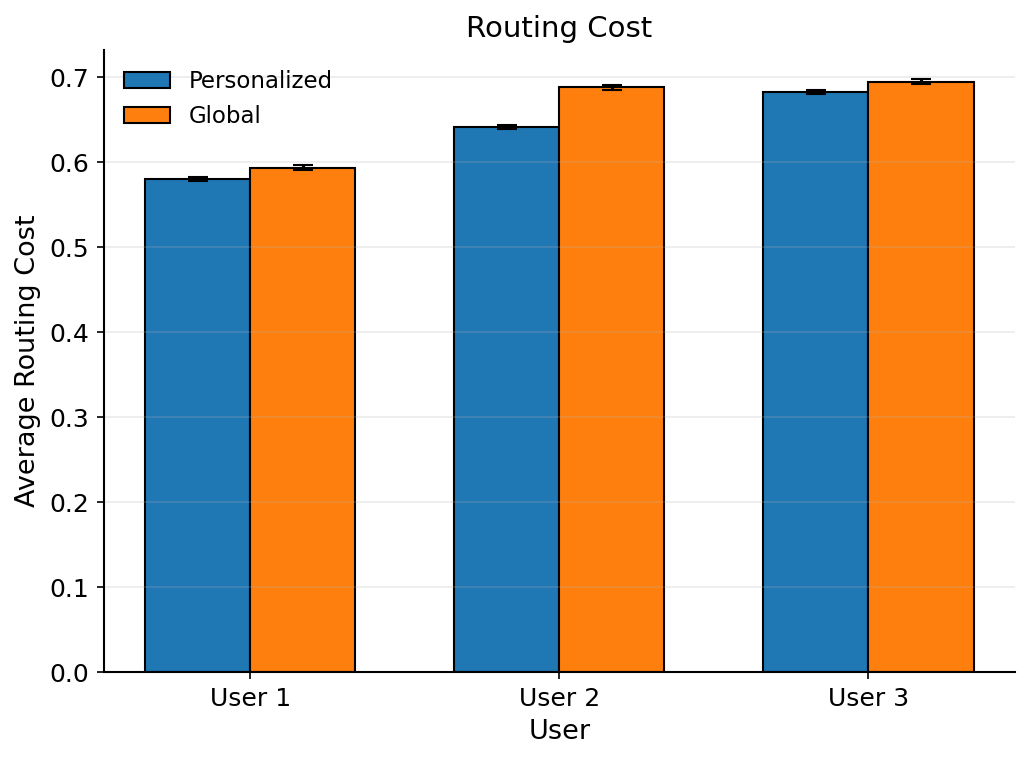

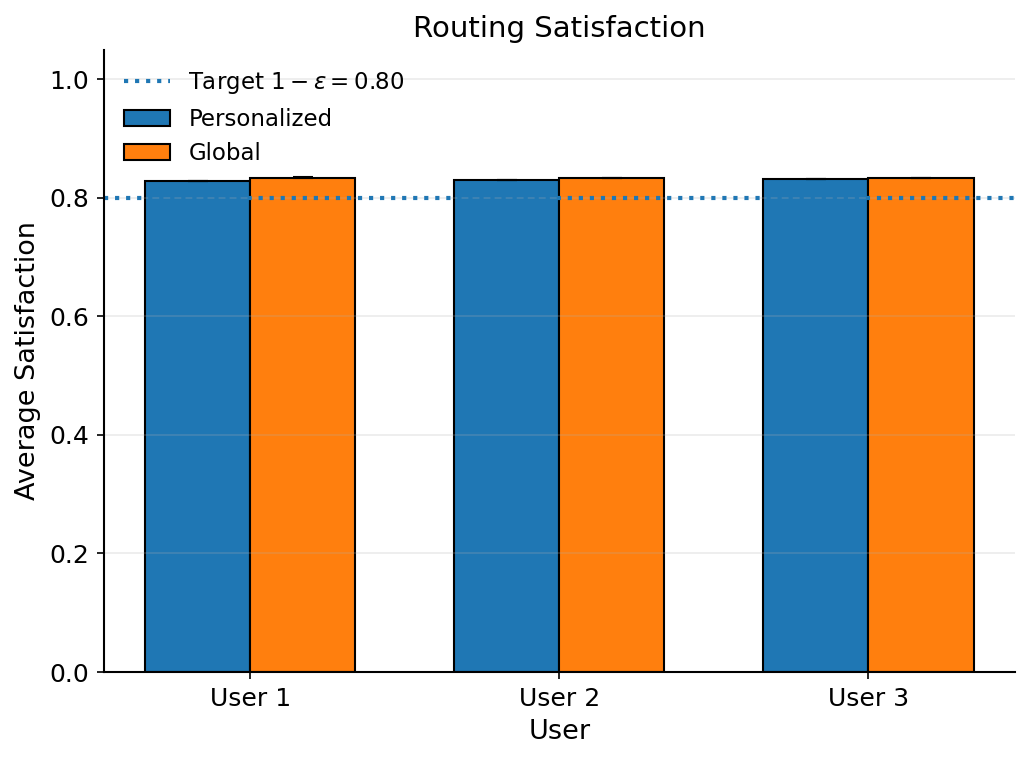


SAVED FILES
/home/ameya-anjarlekar/Documents/LLM Routing/icml_llm_routing_results/errorbars/personalization_cost_users1_3.pdf
/home/ameya-anjarlekar/Documents/LLM Routing/icml_llm_routing_results/errorbars/personalization_satisfaction_users1_3.pdf

PNG versions also saved at 600 DPI.


In [17]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ================================================================
# CONFIG
# ================================================================

BASE_DIR = "/home/ameya-anjarlekar/Documents/LLM Routing/icml_llm_routing_results/errorbars"

CSV_PATH = os.path.join(
    BASE_DIR,
    "personalization_corrected_summary.csv"
)

EPSILON = 0.20


# ================================================================
# PAPER-READY SETTINGS
# ================================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",

    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 13,

    "xtick.labelsize": 12,
    "ytick.labelsize": 12,

    "legend.fontsize": 11,

    "axes.linewidth": 1.0,

    "figure.dpi": 150,
    "savefig.dpi": 600,

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


# ================================================================
# LOAD DATA
# ================================================================

df = pd.read_csv(CSV_PATH)

# Only first three users
df = df[df["user"].isin([1, 2, 3])].copy()

df = df.sort_values("user").reset_index(drop=True)

users = df["user"].to_numpy()
x = np.arange(len(users))


# ================================================================
# ERROR BAR HELPER
# ================================================================

def error_bars(mean, low, high):

    lower = mean - low
    upper = high - mean

    return np.vstack([
        lower,
        upper
    ])


# ================================================================
# PRINT DATA
# ================================================================

print("\n================================================")
print("PERSONALIZATION RESULTS: USERS 1-3")
print("================================================")

print(
    df[
        [
            "user",
            "personalized_cost",
            "global_cost",
            "personalized_satisfaction",
            "global_satisfaction",
            "personalized_constraint_probability",
            "global_constraint_probability"
        ]
    ].to_string(index=False)
)


# ================================================================
# BAR POSITION
# ================================================================

width = 0.34


# ================================================================
# 1. COST
# ================================================================

fig, ax = plt.subplots(
    figsize=(7, 5.2),
    dpi=150
)

# Personalized
ax.bar(
    x - width / 2,
    df["personalized_cost"].to_numpy(),

    width=width,

    yerr=error_bars(
        df["personalized_cost"].to_numpy(),
        df["personalized_cost_ci95_low"].to_numpy(),
        df["personalized_cost_ci95_high"].to_numpy()
    ),

    capsize=5,

    edgecolor="black",
    linewidth=1.0,

    label="Personalized"
)

# Global
ax.bar(
    x + width / 2,
    df["global_cost"].to_numpy(),

    width=width,

    yerr=error_bars(
        df["global_cost"].to_numpy(),
        df["global_cost_ci95_low"].to_numpy(),
        df["global_cost_ci95_high"].to_numpy()
    ),

    capsize=5,

    edgecolor="black",
    linewidth=1.0,

    label="Global"
)


ax.set_xticks(x)
ax.set_xticklabels(
    [f"User {u}" for u in users]
)

ax.set_xlabel("User")
ax.set_ylabel("Average Routing Cost")

ax.set_title("Routing Cost")

ax.grid(
    axis="y",
    alpha=0.25
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    frameon=False,
    loc="upper left"
)

fig.tight_layout(
    pad=1.0
)


# Save vector PDF
fig.savefig(
    os.path.join(
        BASE_DIR,
        "personalization_cost_users1_3.pdf"
    ),
    format="pdf",
    bbox_inches="tight"
)

# Save high-resolution PNG
fig.savefig(
    os.path.join(
        BASE_DIR,
        "personalization_cost_users1_3.png"
    ),
    format="png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ================================================================
# 2. SATISFACTION
# ================================================================

fig, ax = plt.subplots(
    figsize=(7, 5.2),
    dpi=150
)

# Personalized
ax.bar(
    x - width / 2,
    df["personalized_satisfaction"].to_numpy(),

    width=width,

    yerr=error_bars(
        df["personalized_satisfaction"].to_numpy(),
        df["personalized_satisfaction_ci95_low"].to_numpy(),
        df["personalized_satisfaction_ci95_high"].to_numpy()
    ),

    capsize=5,

    edgecolor="black",
    linewidth=1.0,

    label="Personalized"
)

# Global
ax.bar(
    x + width / 2,
    df["global_satisfaction"].to_numpy(),

    width=width,

    yerr=error_bars(
        df["global_satisfaction"].to_numpy(),
        df["global_satisfaction_ci95_low"].to_numpy(),
        df["global_satisfaction_ci95_high"].to_numpy()
    ),

    capsize=5,

    edgecolor="black",
    linewidth=1.0,

    label="Global"
)


# Required satisfaction
ax.axhline(
    1 - EPSILON,
    linestyle=":",
    linewidth=2.0,
    label=fr"Target $1-\epsilon={1-EPSILON:.2f}$"
)


ax.set_xticks(x)
ax.set_xticklabels(
    [f"User {u}" for u in users]
)

ax.set_xlabel("User")
ax.set_ylabel("Average Satisfaction")

ax.set_title("Routing Satisfaction")

ax.set_ylim(0, 1.05)

ax.grid(
    axis="y",
    alpha=0.25
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    frameon=False,
    loc="upper left"
)

fig.tight_layout(
    pad=1.0
)


# Save vector PDF
fig.savefig(
    os.path.join(
        BASE_DIR,
        "personalization_satisfaction_users1_3.pdf"
    ),
    format="pdf",
    bbox_inches="tight"
)

# Save high-resolution PNG
fig.savefig(
    os.path.join(
        BASE_DIR,
        "personalization_satisfaction_users1_3.png"
    ),
    format="png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ================================================================
# DONE
# ================================================================

print("\n================================================")
print("SAVED FILES")
print("================================================")

print(
    os.path.join(
        BASE_DIR,
        "personalization_cost_users1_3.pdf"
    )
)

print(
    os.path.join(
        BASE_DIR,
        "personalization_satisfaction_users1_3.pdf"
    )
)

print("\nPNG versions also saved at 600 DPI.")

In [14]:
import os
import json
import math
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.special import expit
from scipy.optimize import minimize
from scipy.stats import binom


# ================================================================
# SYNTHETIC LLM-ROUTING POC + BASELINE COMPARISONS
# ================================================================

OUTPUT_DIR = os.path.join(
    os.getcwd(),
    "poc_results_synthetic",
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True,
)


# ================================================================
# REPRODUCIBILITY
# ================================================================

SEED = 12345


# ================================================================
# REFERENCE HORIZON / HYPERPARAMETERS
# ================================================================

REFERENCE_T = 100

REFERENCE_ETA = 0.5

REFERENCE_RHO = 0.15

FROZEN_ALPHA_SCALE = 0.005


# ================================================================
# MAIN HORIZON
# ================================================================

BASE_T = 1000

T = BASE_T


# ================================================================
# MAIN SAFETY PARAMETERS
# ================================================================

MAIN_EPSILON = 0.20

MAIN_DELTA = 0.05


# ================================================================
# ENVIRONMENT
# ================================================================

D = 8

# Number of learned LLM actions.
K = 5

# Total number of actions including fallback.
N_ACTIONS = K + 1


# ================================================================
# MODEL NAMES
# ================================================================

MODELS = [
    "Model-1",
    "Model-2",
    "Model-3",
    "Model-4",
    "Model-5",
]

FALLBACK_NAME = "Fallback"


# ================================================================
# COSTS
# ================================================================

MODEL_COSTS = np.array(
    [
        0.10,
        0.25,
        0.40,
        0.60,
        0.80,
    ],
    dtype=float,
)

FALLBACK = K

FALLBACK_COST = 1.0

FALLBACK_UCB = 1.0

COSTS = np.concatenate(
    [
        MODEL_COSTS,
        np.array(
            [FALLBACK_COST],
            dtype=float,
        ),
    ]
)


# ================================================================
# GLM / CONTEXT PARAMETERS
# ================================================================

L = 3.0

S = 1.0

BETA = 1.0

ZETA = 2.5

XI = 0.35


# ================================================================
# MODEL RADII
# ================================================================

MODEL_RADII = np.array(
    [
        1.05,
        1.1625,
        1.275,
        1.3875,
        1.50,
    ],
    dtype=float,
)


# ================================================================
# EXPERIMENT SAMPLE SIZES
# ================================================================

N_MAIN = 1000
N_CHANCE = 5000
N_EPS = 1000
N_DELTA = 1000
N_PERSONALIZATION = 1000
N_ABLATION = 1000
N_ROBUSTNESS = 1000
N_REGRET = 1000
N_CALIBRATION = 1000


# ================================================================
# HORIZONS
# ================================================================

HORIZONS = [
    100,
    250,
    500,
    1000,
    2000,
]


# ================================================================
# NUMBER OF QUERY-ORDER REPLAYS
# ================================================================

N_TRIALS = 100


# ================================================================
# HIDDEN THETA*
# ================================================================

THETA_STAR = np.array(
    [
        0.60,
        0.50,
        0.40,
        0.30,
        0.20,
        0.10,
        0.15,
        0.25,
    ],
    dtype=float,
)

THETA_STAR = (
    THETA_STAR
    / np.linalg.norm(
        THETA_STAR
    )
)


# ================================================================
# TRIAL CONFIG
# ================================================================

@dataclass
class TrialConfig:

    epsilon: float = MAIN_EPSILON

    delta: float = MAIN_DELTA

    xi: float = XI

    eta: float | None = None

    rho: float | None = None

    use_ucb: bool = True

    use_queue: bool = True

    use_rho: bool = True

    theta_star: np.ndarray | None = None


# ================================================================
# BASIC HELPER
# ================================================================

def unit(x):

    x = np.asarray(
        x,
        dtype=float,
    )

    norm = np.linalg.norm(x)

    if norm < 1e-12:

        x = np.zeros_like(x)

        x[0] = 1.0

        norm = 1.0

    return x / norm


# ================================================================
# HORIZON SCALING
# ================================================================

def horizon_scale(
    T_value,
):

    return math.sqrt(
        REFERENCE_T
        / T_value
    )


def horizon_eta(
    T_value,
):

    return (
        REFERENCE_ETA
        * horizon_scale(
            T_value
        )
    )


def horizon_rho(
    T_value,
):

    return (
        REFERENCE_RHO
        * horizon_scale(
            T_value
        )
    )


# ================================================================
# RHO MAX STAR
# ================================================================

def rho_max_star(
    T_value,
    epsilon,
    delta,
):

    q = 1.0 - epsilon

    threshold = int(
        math.ceil(
            T_value * q
        )
    )

    if threshold <= 0:
        return -q

    if threshold > T_value:
        return 1.0 - q

    target = 1.0 - delta

    def tail_probability(mu):

        return binom.sf(
            threshold - 1,
            T_value,
            mu,
        )

    lo = q
    hi = 1.0

    if tail_probability(lo) >= target:

        mu_star = lo

    elif tail_probability(hi) < target:

        mu_star = hi

    else:

        for _ in range(100):

            mid = (
                lo + hi
            ) / 2.0

            if (
                tail_probability(mid)
                >= target
            ):

                hi = mid

            else:

                lo = mid

        mu_star = (
            lo + hi
        ) / 2.0

    return (
        mu_star - q
    )


# ================================================================
# THEORETICAL ALPHA
# ================================================================

def sigma_prime(z):

    p = expit(z)

    return (
        p
        * (1.0 - p)
    )


KAPPA = sigma_prime(L)


def theoretical_alpha(t):

    t = max(
        1,
        int(t),
    )

    delta_E = (
        t ** (-ZETA)
    )

    inside = (
        D
        * math.log(
            1.0
            + (
                t
                * L**2
                / (
                    D
                    * BETA
                )
            )
        )
        + 2.0
        * math.log(
            2.0
            / delta_E
        )
    )

    return (
        1.0
        / KAPPA
        * (
            0.5
            * math.sqrt(
                max(
                    0.0,
                    inside,
                )
            )
            + math.sqrt(BETA)
            * S
        )
    )


def empirical_alpha(
    t,
    scale=FROZEN_ALPHA_SCALE,
):

    return (
        scale
        * theoretical_alpha(t)
    )


# ================================================================
# ETA
# ================================================================

def compute_eta(
    epsilon,
):

    return (
        REFERENCE_ETA
        * epsilon
        / MAIN_EPSILON
    )


# ================================================================
# RHO
# ================================================================

def compute_rho(
    T_value,
):

    return (
        REFERENCE_RHO
        * math.sqrt(
            REFERENCE_T
            / T_value
        )
    )


# ================================================================
# MODEL DIRECTIONS
#
# EXACT REFERENCE CONSTRUCTION
# ================================================================

def make_model_directions(
    rng,
):

    directions = []

    for _ in range(K):

        directions.append(
            unit(
                rng.normal(
                    size=D
                )
            )
        )

    return np.asarray(
        directions
    )


# ================================================================
# USER DIRECTIONS
# ================================================================

def make_user_directions(
    rng,
    n_users=5,
):

    directions = []

    for _ in range(
        n_users
    ):

        directions.append(
            unit(
                rng.normal(
                    size=D
                )
            )
        )

    return np.asarray(
        directions
    )


# ================================================================
# EXACT REFERENCE CONTEXT GENERATOR
# ================================================================

def generate_contexts(
    rng,
    theta_star,
    model_dirs,
    xi=XI,
    user_dir=None,
    shared_mode=False,
    T_override=None,
):

    if T_override is None:

        T_override = T

    X = np.zeros(
        (
            T_override,
            K,
            D,
        ),
        dtype=float,
    )

    theta_dir = unit(
        theta_star
    )

    if user_dir is None:

        user_dir = theta_dir

    user_dir = unit(
        user_dir
    )

    for t in range(
        T_override
    ):

        for a in range(K):

            base = model_dirs[a]

            # ----------------------------------------------------
            # Random tangent perturbation.
            # ----------------------------------------------------

            noise = rng.normal(
                size=D
            )

            noise = (
                noise
                - np.dot(
                    noise,
                    base,
                )
                * base
            )

            noise_norm = np.linalg.norm(
                noise
            )

            if noise_norm < 1e-12:

                noise = np.zeros(D)

            else:

                noise /= noise_norm

            # ----------------------------------------------------
            # Uniform-ish random radius inside the cap.
            # ----------------------------------------------------

            radius = (
                MODEL_RADII[a]
                * (
                    rng.random()
                    ** (
                        1.0
                        / max(
                            1,
                            D - 1,
                        )
                    )
                )
            )

            direction = unit(
                base
                + radius * noise
            )

            # ----------------------------------------------------
            # User/context mixture.
            # ----------------------------------------------------

            if shared_mode:

                direction = unit(
                    (
                        1.0 - xi
                    )
                    * direction
                    + xi
                    * theta_dir
                )

            else:

                direction = unit(
                    (
                        1.0 - xi
                    )
                    * direction
                    + xi
                    * user_dir
                )

            # ----------------------------------------------------
            # Final context.
            # ----------------------------------------------------

            X[t, a] = (
                direction
                * min(
                    MODEL_RADII[a],
                    L,
                )
            )

    return X


# ================================================================
# SYNTHETIC DATA GENERATION
# ================================================================

def generate_synthetic_data(
    T_value=T,
    seed=SEED,
):

    rng = np.random.default_rng(
        seed
    )

    # ------------------------------------------------------------
    # Five fixed random model directions.
    # ------------------------------------------------------------

    model_dirs = (
        make_model_directions(
            rng
        )
    )

    # ------------------------------------------------------------
    # Generate contexts.
    #
    # user_dir=None means:
    #
    #     user_dir = theta_dir
    #
    # so the xi mixture is toward theta*.
    # ------------------------------------------------------------

    X = generate_contexts(
        rng=rng,
        theta_star=THETA_STAR,
        model_dirs=model_dirs,
        xi=XI,
        user_dir=None,
        shared_mode=False,
        T_override=T_value,
    )

    # ------------------------------------------------------------
    # True satisfaction probabilities.
    #
    #     p_{t,a} = theta*^T x_{t,a}
    # ------------------------------------------------------------

    true_probabilities = np.einsum(
        "d,tad->ta",
        THETA_STAR,
        X,
    )

    # Bernoulli probabilities must lie in [0,1].
    true_probabilities = np.clip(
        true_probabilities,
        0.0,
        1.0,
    )

    # ------------------------------------------------------------
    # Fixed potential outcomes.
    #
    # These are reused across query-order replays.
    # ------------------------------------------------------------

    Y = (
        rng.random(
            size=true_probabilities.shape
        )
        < true_probabilities
    ).astype(float)

    query_ids = np.arange(
        T_value
    )

    return (
        X,
        Y,
        query_ids,
        true_probabilities,
        model_dirs,
    )


# ================================================================
# LOGISTIC MLE
# ================================================================

def logistic_mle(
    X,
    y,
):

    X = np.asarray(
        X,
        dtype=float,
    )

    y = np.asarray(
        y,
        dtype=float,
    )

    if len(y) == 0:

        return np.zeros(D)

    theta0 = np.zeros(D)

    def objective(theta):

        z = X @ theta

        log_term = np.logaddexp(
            0.0,
            z,
        )

        nll = np.sum(
            log_term
            - y * z
        )

        ridge = (
            0.5
            * BETA
            * np.dot(
                theta,
                theta,
            )
        )

        return (
            nll
            + ridge
        )

    def gradient(theta):

        z = X @ theta

        p = expit(z)

        grad = (
            X.T
            @ (
                p - y
            )
        )

        grad += (
            BETA
            * theta
        )

        return grad

    try:

        result = minimize(
            objective,
            theta0,
            jac=gradient,
            method="L-BFGS-B",
            options={
                "maxiter": 100,
                "ftol": 1e-8,
                "gtol": 1e-6,
            },
        )

        return result.x

    except Exception:

        return theta0


# ================================================================
# CONTEXTUAL UCB
# ================================================================

def compute_contextual_ucbs(
    X_t,
    theta_hat,
    V_inv,
    t,
):

    alpha = empirical_alpha(
        t
    )

    # Five learned models + fallback.
    ucbs = np.zeros(
        N_ACTIONS,
        dtype=float,
    )

    # ------------------------------------------------------------
    # Learned models.
    # ------------------------------------------------------------

    for a in range(K):

        x = X_t[a]

        mean = float(
            expit(
                np.dot(
                    x,
                    theta_hat,
                )
            )
        )

        uncertainty_sq = np.dot(
            x,
            V_inv @ x,
        )

        uncertainty = math.sqrt(
            max(
                0.0,
                uncertainty_sq,
            )
        )

        # Intentionally NOT clipped at 1.
        ucbs[a] = (
            mean
            + alpha
            * uncertainty
        )

    # ------------------------------------------------------------
    # Perfect fallback.
    #
    # Known satisfaction probability = 1.
    # No learning is required.
    # ------------------------------------------------------------

    ucbs[FALLBACK] = (
        FALLBACK_UCB
    )

    return ucbs


# ================================================================
# GLOBAL / CONTEXT-FREE UCB
# ================================================================

def compute_global_ucbs(
    success_counts,
    action_counts,
    t,
):

    ucbs = np.zeros(
        N_ACTIONS,
        dtype=float,
    )

    # ------------------------------------------------------------
    # Learned model arms.
    # ------------------------------------------------------------

    for a in range(K):

        n = action_counts[a]

        if n <= 0:

            ucbs[a] = 1.0

        else:

            mean = (
                success_counts[a]
                / n
            )

            radius = math.sqrt(
                math.log(
                    2.0
                    * (
                        max(
                            1,
                            t,
                        )
                        ** ZETA
                    )
                )
                / (
                    2.0
                    * n
                )
            )

            ucbs[a] = min(
                1.0,
                mean + radius,
            )

    # ------------------------------------------------------------
    # Perfect fallback.
    # ------------------------------------------------------------

    ucbs[FALLBACK] = (
        FALLBACK_UCB
    )

    return ucbs


# ================================================================
# SINGLE ONLINE TRIAL
# ================================================================

def run_online_trial(
    X,
    Y,
    epsilon,
    delta,
    query_order,
    method="ours",
):

    T_value = len(
        query_order
    )

    eta = compute_eta(
        epsilon
    )

    rho = compute_rho(
        T_value
    )

    # ------------------------------------------------------------
    # Contextual learner state.
    # ------------------------------------------------------------

    V = (
        BETA
        * np.eye(D)
    )

    theta_hat = np.zeros(D)

    selected_X = []

    selected_y = []

    # ------------------------------------------------------------
    # Global baseline state.
    # ------------------------------------------------------------

    global_successes = np.zeros(
        K,
        dtype=float,
    )

    global_counts = np.zeros(
        K,
        dtype=int,
    )

    # ------------------------------------------------------------
    # Dual queue.
    # ------------------------------------------------------------

    lam = 0.0

    # ------------------------------------------------------------
    # Logging.
    # ------------------------------------------------------------

    selected_actions = np.zeros(
        T_value,
        dtype=int,
    )

    observed_y = np.zeros(
        T_value,
        dtype=float,
    )

    observed_cost = np.zeros(
        T_value,
        dtype=float,
    )

    lambda_history = np.zeros(
        T_value,
        dtype=float,
    )

    ucb_history = np.zeros(
        (
            T_value,
            N_ACTIONS,
        ),
        dtype=float,
    )

    # ============================================================
    # ONLINE LOOP
    # ============================================================

    for t_idx in range(
        T_value
    ):

        t = t_idx + 1

        query_idx = int(
            query_order[t_idx]
        )

        X_t = X[
            query_idx
        ]

        # --------------------------------------------------------
        # Confidence matrix.
        # --------------------------------------------------------

        V_inv = np.linalg.inv(
            V
        )

        # --------------------------------------------------------
        # UCBs.
        # --------------------------------------------------------

        if method == (
            "global_constrained"
        ):

            ucbs = compute_global_ucbs(
                success_counts=global_successes,
                action_counts=global_counts,
                t=t,
            )

        else:

            ucbs = compute_contextual_ucbs(
                X_t=X_t,
                theta_hat=theta_hat,
                V_inv=V_inv,
                t=t,
            )

        ucb_history[
            t_idx
        ] = ucbs

        # --------------------------------------------------------
        # Multiplier.
        # --------------------------------------------------------

        if method == (
            "unconstrained_contextual"
        ):

            multiplier = 1.0

        else:

            multiplier = lam

        # --------------------------------------------------------
        # Action selection.
        #
        # This includes the fallback.
        #
        #     action in {0,...,K}
        #
        # with action K = fallback.
        # --------------------------------------------------------

        scores = (
            COSTS
            - multiplier
            * ucbs
        )

        action = int(
            np.argmin(
                scores
            )
        )

        # --------------------------------------------------------
        # Observe outcome.
        #
        # Fallback is deterministically successful.
        # --------------------------------------------------------

        if action == FALLBACK:

            y = 1.0

        else:

            y = float(
                Y[
                    query_idx,
                    action,
                ]
            )

        cost = float(
            COSTS[action]
        )

        selected_actions[
            t_idx
        ] = action

        observed_y[
            t_idx
        ] = y

        observed_cost[
            t_idx
        ] = cost

        # --------------------------------------------------------
        # Dual queue update.
        # --------------------------------------------------------

        if method in {
            "ours",
            "global_constrained",
        }:

            queue_target = (
                (
                    1.0
                    - epsilon
                )
                + rho
            )

            lam = max(
                0.0,
                lam
                + eta
                * (
                    queue_target
                    - y
                ),
            )

        elif method == (
            "expectation_primal_dual"
        ):

            queue_target = (
                1.0
                - epsilon
            )

            lam = max(
                0.0,
                lam
                + eta
                * (
                    queue_target
                    - y
                ),
            )

        # --------------------------------------------------------
        # Unconstrained contextual:
        #
        # no queue update.
        # --------------------------------------------------------

        lambda_history[
            t_idx
        ] = lam

        # --------------------------------------------------------
        # Update learner ONLY for learned LLM actions.
        #
        # Fallback is known and therefore is NOT included in the
        # contextual model estimation.
        # --------------------------------------------------------

        if action != FALLBACK:

            if method == (
                "global_constrained"
            ):

                global_counts[
                    action
                ] += 1

                global_successes[
                    action
                ] += y

            else:

                x_selected = X_t[
                    action
                ]

                selected_X.append(
                    x_selected.copy()
                )

                selected_y.append(
                    y
                )

                V += np.outer(
                    x_selected,
                    x_selected,
                )

                theta_hat = logistic_mle(
                    np.asarray(
                        selected_X
                    ),
                    np.asarray(
                        selected_y
                    ),
                )

    # ============================================================
    # AGGREGATES
    # ============================================================

    avg_satisfaction = float(
        np.mean(
            observed_y
        )
    )

    avg_cost = float(
        np.mean(
            observed_cost
        )
    )

    required_satisfaction = (
        1.0
        - epsilon
    )

    constraint_satisfied = (
        avg_satisfaction
        >= required_satisfaction
    )

    usage_counts = np.bincount(
        selected_actions,
        minlength=N_ACTIONS,
    )

    usage_frequency = (
        usage_counts
        / T_value
    )

    fallback_rate = (
        np.mean(
            selected_actions
            == FALLBACK
        )
    )

    model_usage_counts = (
        usage_counts[:K]
    )

    model_usage_frequency = (
        usage_frequency[:K]
    )

    return {

        "method":
            method,

        "avg_satisfaction":
            avg_satisfaction,

        "avg_cost":
            avg_cost,

        "required_satisfaction":
            required_satisfaction,

        "constraint_satisfied":
            bool(
                constraint_satisfied
            ),

        "selected_actions":
            selected_actions,

        "observed_y":
            observed_y,

        "observed_cost":
            observed_cost,

        "lambda_history":
            lambda_history,

        "ucb_history":
            ucb_history,

        "usage_counts":
            usage_counts,

        "usage_frequency":
            usage_frequency,

        "model_usage_counts":
            model_usage_counts,

        "model_usage_frequency":
            model_usage_frequency,

        "fallback_rate":
            fallback_rate,

        "eta":
            eta,

        "rho":
            rho,

        "final_theta_hat":
            theta_hat,
    }


# ================================================================
# MULTIPLE QUERY-ORDER REPLAYS
# ================================================================

def run_replays(
    X,
    Y,
    epsilon,
    delta,
    n_trials=N_TRIALS,
    method="ours",
):

    T_value = X.shape[0]

    rng = np.random.default_rng(
        SEED + 1
    )

    results = []

    for trial in range(
        n_trials
    ):

        query_order = (
            rng.permutation(
                T_value
            )
        )

        result = run_online_trial(
            X=X,
            Y=Y,
            epsilon=epsilon,
            delta=delta,
            query_order=query_order,
            method=method,
        )

        result["trial"] = (
            trial
        )

        results.append(
            result
        )

    return results


# ================================================================
# SUMMARIZE REPLAYS
# ================================================================

def summarize_replays(
    results,
):

    satisfaction = np.array(
        [
            r[
                "avg_satisfaction"
            ]
            for r in results
        ]
    )

    costs = np.array(
        [
            r[
                "avg_cost"
            ]
            for r in results
        ]
    )

    feasible = np.array(
        [
            r[
                "constraint_satisfied"
            ]
            for r in results
        ],
        dtype=float,
    )

    usage = np.array(
        [
            r[
                "usage_frequency"
            ]
            for r in results
        ]
    )

    fallback_rates = np.array(
        [
            r[
                "fallback_rate"
            ]
            for r in results
        ]
    )

    return {

        "mean_satisfaction":
            float(
                np.mean(
                    satisfaction
                )
            ),

        "std_satisfaction":
            float(
                np.std(
                    satisfaction,
                    ddof=1,
                )
            ),

        "mean_cost":
            float(
                np.mean(
                    costs
                )
            ),

        "std_cost":
            float(
                np.std(
                    costs,
                    ddof=1,
                )
            ),

        "constraint_probability":
            float(
                np.mean(
                    feasible
                )
            ),

        "mean_usage":
            np.mean(
                usage,
                axis=0,
            ),

        "std_usage":
            np.std(
                usage,
                axis=0,
                ddof=1,
            ),

        "mean_fallback_rate":
            float(
                np.mean(
                    fallback_rates
                )
            ),

        "std_fallback_rate":
            float(
                np.std(
                    fallback_rates,
                    ddof=1,
                )
            ),
    }


# ================================================================
# EPSILON SWEEP
# ================================================================

def run_epsilon_sweep(
    X,
    Y,
):

    epsilon_values = [
        0.20,
        0.25,
        0.30,
        0.35,
        0.40,
    ]

    rows = []

    for epsilon in (
        epsilon_values
    ):

        results = run_replays(
            X=X,
            Y=Y,
            epsilon=epsilon,
            delta=MAIN_DELTA,
            n_trials=N_TRIALS,
            method="ours",
        )

        summary = summarize_replays(
            results
        )

        row = {

            "epsilon":
                epsilon,

            "eta":
                compute_eta(
                    epsilon
                ),

            "rho":
                compute_rho(
                    X.shape[0]
                ),

            "required_satisfaction":
                1.0 - epsilon,

            "mean_satisfaction":
                summary[
                    "mean_satisfaction"
                ],

            "std_satisfaction":
                summary[
                    "std_satisfaction"
                ],

            "mean_cost":
                summary[
                    "mean_cost"
                ],

            "std_cost":
                summary[
                    "std_cost"
                ],

            "constraint_probability":
                summary[
                    "constraint_probability"
                ],

            "fallback_rate":
                summary[
                    "mean_fallback_rate"
                ],
        }

        for a, model in enumerate(
            MODELS
        ):

            row[
                f"usage_{model}"
            ] = summary[
                "mean_usage"
            ][a]

        rows.append(
            row
        )

    df = pd.DataFrame(
        rows
    )

    df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "poc_epsilon_sweep.csv",
        ),
        index=False,
    )

    return df


# ================================================================
# MAIN COST FIGURE
# ================================================================

def plot_epsilon_cost(
    df,
):

    plt.figure(
        figsize=(8, 5)
    )

    plt.plot(
        df["epsilon"],
        df["mean_cost"],
        marker="o",
        linewidth=2,
    )

    plt.xlabel(
        r"$\epsilon$"
    )

    plt.ylabel(
        "Average cost"
    )

    plt.title(
        "Average Routing Cost vs. Constraint"
    )

    plt.xticks(
        df["epsilon"]
    )

    plt.grid(
        alpha=0.25
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            "poc_cost_vs_epsilon.png",
        ),
        dpi=300,
        bbox_inches="tight",
    )

    plt.close()


# ================================================================
# MAIN SATISFACTION FIGURE
# ================================================================

def plot_epsilon_satisfaction(
    df,
):

    plt.figure(
        figsize=(8, 5)
    )

    plt.plot(
        df["epsilon"],
        df["mean_satisfaction"],
        marker="o",
        linewidth=2,
        label="Mean satisfaction",
    )

    plt.plot(
        df["epsilon"],
        df["required_satisfaction"],
        marker="s",
        linestyle="--",
        linewidth=1.5,
        label=r"Required $1-\epsilon$",
    )

    plt.xlabel(
        r"$\epsilon$"
    )

    plt.ylabel(
        "Satisfaction"
    )

    plt.title(
        "Mean Satisfaction vs. Constraint"
    )

    plt.xticks(
        df["epsilon"]
    )

    plt.ylim(
        0,
        1.05,
    )

    plt.grid(
        alpha=0.25
    )

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            "poc_satisfaction_vs_epsilon.png",
        ),
        dpi=300,
        bbox_inches="tight",
    )

    plt.close()


# ================================================================
# MODEL SELECTION FIGURE
#
# Five learned models only.
# Fallback is shown separately in the legend.
# ================================================================

def plot_model_selection_vs_epsilon(
    df,
):

    fig, ax = plt.subplots(
        figsize=(10, 6)
    )

    x = np.arange(
        len(df)
    )

    bottom = np.zeros(
        len(df)
    )

    for model in MODELS:

        values = (
            df[
                f"usage_{model}"
            ].to_numpy()
            * 100.0
        )

        ax.bar(
            x,
            values,
            bottom=bottom,
            width=0.65,
            label=model,
        )

        bottom += values

    fallback_values = (
        df["fallback_rate"].to_numpy()
        * 100.0
    )

    ax.bar(
        x,
        fallback_values,
        bottom=bottom,
        width=0.65,
        label=FALLBACK_NAME,
    )

    ax.set_xlabel(
        r"$\epsilon$"
    )

    ax.set_ylabel(
        "Action selection proportion (%)"
    )

    ax.set_title(
        "Model and Fallback Selection vs. Constraint"
    )

    ax.set_xticks(
        x
    )

    ax.set_xticklabels(
        [
            f"{e:.2f}"
            for e in df["epsilon"]
        ]
    )

    ax.set_ylim(
        0,
        100,
    )

    ax.grid(
        axis="y",
        alpha=0.25,
    )

    ax.legend(
        loc="upper center",
        bbox_to_anchor=(
            0.5,
            -0.10,
        ),
        ncol=3,
        frameon=False,
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            "poc_model_selection_vs_epsilon.png",
        ),
        dpi=300,
        bbox_inches="tight",
    )

    plt.close()


# ================================================================
# BASELINE LABELS
# ================================================================

METHOD_LABELS = {

    "ours":
        "Ours (contextual + safety margin)",

    "global_constrained":
        "Global constrained (SLARouter-style proxy)",

    "unconstrained_contextual":
        "Unconstrained contextual (BaRP-style proxy)",

    "expectation_primal_dual":
        "Expectation-constrained primal-dual",
}


# ================================================================
# BASELINE COMPARISON SWEEP
# ================================================================

def run_baseline_comparison_sweep(
    X,
    Y,
):

    epsilon_values = [
        0.20,
        0.25,
        0.30,
        0.35,
        0.40,
    ]

    methods = [
        "ours",
        "global_constrained",
        "unconstrained_contextual",
        "expectation_primal_dual",
    ]

    rows = []

    for epsilon in (
        epsilon_values
    ):

        for method in methods:

            results = run_replays(
                X=X,
                Y=Y,
                epsilon=epsilon,
                delta=MAIN_DELTA,
                n_trials=N_TRIALS,
                method=method,
            )

            summary = summarize_replays(
                results
            )

            row = {

                "method":
                    method,

                "method_label":
                    METHOD_LABELS[
                        method
                    ],

                "epsilon":
                    epsilon,

                "delta":
                    MAIN_DELTA,

                "eta":
                    compute_eta(
                        epsilon
                    ),

                "rho":
                    (
                        compute_rho(
                            X.shape[0]
                        )
                        if method
                        in {
                            "ours",
                            "global_constrained",
                        }
                        else 0.0
                    ),

                "required_satisfaction":
                    1.0 - epsilon,

                "target_probability":
                    1.0 - MAIN_DELTA,

                "mean_satisfaction":
                    summary[
                        "mean_satisfaction"
                    ],

                "std_satisfaction":
                    summary[
                        "std_satisfaction"
                    ],

                "mean_cost":
                    summary[
                        "mean_cost"
                    ],

                "std_cost":
                    summary[
                        "std_cost"
                    ],

                "constraint_probability":
                    summary[
                        "constraint_probability"
                    ],

                "fallback_rate":
                    summary[
                        "mean_fallback_rate"
                    ],
            }

            for a, model in enumerate(
                MODELS
            ):

                row[
                    f"usage_{model}"
                ] = summary[
                    "mean_usage"
                ][a]

            rows.append(
                row
            )

    df = pd.DataFrame(
        rows
    )

    df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "poc_baseline_comparison.csv",
        ),
        index=False,
    )

    # ============================================================
    # COST
    # ============================================================

    fig, ax = plt.subplots(
        figsize=(8.2, 5.2)
    )

    for method in methods:

        part = df[
            df["method"]
            == method
        ]

        ax.plot(
            part["epsilon"],
            part["mean_cost"],
            marker="o",
            linewidth=2,
            label=METHOD_LABELS[
                method
            ],
        )

    ax.set_xlabel(
        r"$\epsilon$"
    )

    ax.set_ylabel(
        "Average routing cost"
    )

    ax.set_title(
        "Routing Cost vs. Satisfaction Constraint"
    )

    ax.set_xticks(
        epsilon_values
    )

    ax.grid(
        alpha=0.25
    )

    ax.legend(
        fontsize=8
    )

    fig.tight_layout()

    fig.savefig(
        os.path.join(
            OUTPUT_DIR,
            "poc_baselines_cost_vs_epsilon.png",
        ),
        dpi=300,
        bbox_inches="tight",
    )

    plt.close(
        fig
    )

    # ============================================================
    # SATISFACTION
    # ============================================================

    fig, ax = plt.subplots(
        figsize=(8.2, 5.2)
    )

    for method in methods:

        part = df[
            df["method"]
            == method
        ]

        ax.plot(
            part["epsilon"],
            part["mean_satisfaction"],
            marker="o",
            linewidth=2,
            label=METHOD_LABELS[
                method
            ],
        )

    ax.plot(
        epsilon_values,
        [
            1.0 - e
            for e in epsilon_values
        ],
        linestyle="--",
        linewidth=1.5,
        label=r"Required $1-\epsilon$",
    )

    ax.set_xlabel(
        r"$\epsilon$"
    )

    ax.set_ylabel(
        "Mean satisfaction"
    )

    ax.set_title(
        "Mean Satisfaction vs. Constraint"
    )

    ax.set_xticks(
        epsilon_values
    )

    ax.set_ylim(
        0,
        1.05,
    )

    ax.grid(
        alpha=0.25
    )

    ax.legend(
        fontsize=8
    )

    fig.tight_layout()

    fig.savefig(
        os.path.join(
            OUTPUT_DIR,
            "poc_baselines_satisfaction_vs_epsilon.png",
        ),
        dpi=300,
        bbox_inches="tight",
    )

    plt.close(
        fig
    )

    # ============================================================
    # CONSTRAINT SUCCESS
    # ============================================================

    fig, ax = plt.subplots(
        figsize=(8.2, 5.2)
    )

    for method in methods:

        part = df[
            df["method"]
            == method
        ]

        ax.plot(
            part["epsilon"],
            part["constraint_probability"],
            marker="o",
            linewidth=2,
            label=METHOD_LABELS[
                method
            ],
        )

    ax.axhline(
        1.0 - MAIN_DELTA,
        linestyle="--",
        linewidth=1.5,
        label=r"Target $1-\delta$",
    )

    ax.set_xlabel(
        r"$\epsilon$"
    )

    ax.set_ylabel(
        "Fraction of query-order replays meeting target"
    )

    ax.set_title(
        "Empirical Constraint Success Across Replays"
    )

    ax.set_xticks(
        epsilon_values
    )

    ax.set_ylim(
        -0.03,
        1.03,
    )

    ax.grid(
        alpha=0.25
    )

    ax.legend(
        fontsize=8
    )

    fig.tight_layout()

    fig.savefig(
        os.path.join(
            OUTPUT_DIR,
            "poc_baselines_constraint_success_vs_epsilon.png",
        ),
        dpi=300,
        bbox_inches="tight",
    )

    plt.close(
        fig
    )

    return df


# ================================================================
# DEFAULT EXPERIMENT
# ================================================================

def run_default_poc(
    X,
    Y,
):

    results = run_replays(
        X=X,
        Y=Y,
        epsilon=MAIN_EPSILON,
        delta=MAIN_DELTA,
        n_trials=N_TRIALS,
        method="ours",
    )

    summary = summarize_replays(
        results
    )

    row = {

        "epsilon":
            MAIN_EPSILON,

        "delta":
            MAIN_DELTA,

        "eta":
            compute_eta(
                MAIN_EPSILON
            ),

        "rho":
            compute_rho(
                X.shape[0]
            ),

        "mean_cost":
            summary[
                "mean_cost"
            ],

        "cost_std":
            summary[
                "std_cost"
            ],

        "mean_satisfaction":
            summary[
                "mean_satisfaction"
            ],

        "satisfaction_std":
            summary[
                "std_satisfaction"
            ],

        "constraint_probability":
            summary[
                "constraint_probability"
            ],

        "fallback_rate":
            summary[
                "mean_fallback_rate"
            ],
    }

    for a, model in enumerate(
        MODELS
    ):

        row[
            f"usage_{model}"
        ] = summary[
            "mean_usage"
        ][a]

    df = pd.DataFrame(
        [row]
    )

    df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "poc_default_trials.csv",
        ),
        index=False,
    )

    return df


# ================================================================
# SAVE CONFIG
# ================================================================

def save_config(
    X,
    Y,
    model_dirs,
):

    config = {

        "seed":
            SEED,

        "D":
            D,

        "K_learned_models":
            K,

        "N_actions_with_fallback":
            N_ACTIONS,

        "T":
            int(
                X.shape[0]
            ),

        "epsilon":
            MAIN_EPSILON,

        "delta":
            MAIN_DELTA,

        "reference_T":
            REFERENCE_T,

        "reference_eta":
            REFERENCE_ETA,

        "reference_rho":
            REFERENCE_RHO,

        "frozen_alpha_scale":
            FROZEN_ALPHA_SCALE,

        "L":
            L,

        "S":
            S,

        "BETA":
            BETA,

        "ZETA":
            ZETA,

        "XI":
            XI,

        "model_costs":
            MODEL_COSTS.tolist(),

        "fallback":
            {
                "index":
                    FALLBACK,

                "cost":
                    FALLBACK_COST,

                "ucb":
                    FALLBACK_UCB,

                "satisfaction":
                    1.0,

                "learned":
                    False,
            },

        "model_radii":
            MODEL_RADII.tolist(),

        "theta_star":
            THETA_STAR.tolist(),

        "theta_star_norm":
            float(
                np.linalg.norm(
                    THETA_STAR
                )
            ),

        "model_directions":
            model_dirs.tolist(),

        "context_generation":
            (
                "Fixed random model directions; "
                "random tangent perturbation; "
                "uniform-ish random radius inside "
                "the model-specific cap; "
                "xi mixture toward user direction."
            ),

        "satisfaction_model":
            "p[t,a] = clip(theta_star^T x[t,a], 0, 1)",

        "outcome_generation":
            "Y[t,a] ~ Bernoulli(p[t,a])",

        "potential_outcomes_fixed":
            True,

        "fallback_used_in_learning":
            False,

        "models":
            MODELS,

        "baseline_methods":
            METHOD_LABELS,
    }

    with open(
        os.path.join(
            OUTPUT_DIR,
            "poc_config.json",
        ),
        "w",
    ) as f:

        json.dump(
            config,
            f,
            indent=2,
        )


# ================================================================
# MAIN
# ================================================================

def main():

    print()
    print(
        "=" * 80
    )
    print(
        "SYNTHETIC LLM ROUTING POC"
    )
    print(
        "=" * 80
    )

    print()
    print(
        f"D = {D}"
    )

    print(
        f"Learned models K = {K}"
    )

    print(
        f"Total actions = {N_ACTIONS}"
    )

    print(
        f"T = {T}"
    )

    print(
        f"epsilon = {MAIN_EPSILON}"
    )

    print(
        f"delta = {MAIN_DELTA}"
    )

    print(
        f"xi = {XI}"
    )

    print(
        "Model costs =",
        MODEL_COSTS,
    )

    print(
        f"Fallback cost = {FALLBACK_COST}"
    )

    print(
        f"Fallback index = {FALLBACK}"
    )

    print()
    print(
        "theta* =",
        THETA_STAR,
    )

    print(
        "||theta*|| =",
        np.linalg.norm(
            THETA_STAR
        ),
    )

    # ============================================================
    # GENERATE DATA
    # ============================================================

    (
        X,
        Y,
        query_ids,
        true_probabilities,
        model_dirs,
    ) = generate_synthetic_data(
        T_value=T,
        seed=SEED,
    )

    # ============================================================
    # VALIDATION
    # ============================================================

    assert X.shape == (
        T,
        K,
        D,
    )

    assert Y.shape == (
        T,
        K,
    )

    assert np.all(
        np.isfinite(X)
    )

    assert np.all(
        (Y == 0)
        | (Y == 1)
    )

    assert np.all(
        true_probabilities
        >= 0.0
    )

    assert np.all(
        true_probabilities
        <= 1.0
    )

    # ============================================================
    # PRINT TRUE MODEL STATISTICS
    # ============================================================

    print()
    print(
        "=" * 80
    )
    print(
        "TRUE SATISFACTION BY MODEL"
    )
    print(
        "=" * 80
    )

    for a in range(K):

        print(
            f"{MODELS[a]:10s} "
            f"cost={MODEL_COSTS[a]:.3f}  "
            f"radius={MODEL_RADII[a]:.4f}  "
            f"true_mean="
            f"{np.mean(true_probabilities[:, a]):.4f}  "
            f"realized_mean="
            f"{np.mean(Y[:, a]):.4f}"
        )

    print(
        f"{FALLBACK_NAME:10s} "
        f"cost={FALLBACK_COST:.3f}  "
        f"satisfaction=1.0000"
    )

    # ============================================================
    # PRINT FIXED MODEL DIRECTIONS
    # ============================================================

    print()
    print(
        "Fixed model directions:"
    )

    for a in range(K):

        print(
            f"{MODELS[a]}:"
        )

        print(
            model_dirs[a]
        )

    # ============================================================
    # BASELINES
    # ============================================================

    print()
    print(
        "=" * 80
    )
    print(
        "RUNNING BASELINE COMPARISON"
    )
    print(
        "=" * 80
    )

    baseline_df = (
        run_baseline_comparison_sweep(
            X,
            Y,
        )
    )

    # ============================================================
    # SAVE CONFIG
    # ============================================================

    save_config(
        X=X,
        Y=Y,
        model_dirs=model_dirs,
    )

    # ============================================================
    # COMPLETE
    # ============================================================

    print()
    print(
        "=" * 80
    )
    print(
        "COMPLETE"
    )
    print(
        "=" * 80
    )

    print()
    print(
        "Results saved to:"
    )

    print(
        OUTPUT_DIR
    )

    print()
    print(
        "Generated files:"
    )

    for filename in sorted(
        os.listdir(
            OUTPUT_DIR
        )
    ):

        print(
            "  ",
            filename,
        )


# ================================================================
# ENTRY POINT
# ================================================================

if __name__ == "__main__":

    main()


SYNTHETIC LLM ROUTING POC

D = 8
Learned models K = 5
Total actions = 6
T = 1000
epsilon = 0.2
delta = 0.05
xi = 0.35
Model costs = [0.1  0.25 0.4  0.6  0.8 ]
Fallback cost = 1.0
Fallback index = 5

theta* = [0.60150565 0.50125471 0.40100377 0.30075282 0.20050188 0.10025094
 0.15037641 0.25062735]
||theta*|| = 1.0

TRUE SATISFACTION BY MODEL
Model-1    cost=0.100  radius=1.0500  true_mean=0.3100  realized_mean=0.2960
Model-2    cost=0.250  radius=1.1625  true_mean=0.5958  realized_mean=0.6030
Model-3    cost=0.400  radius=1.2750  true_mean=0.6595  realized_mean=0.6480
Model-4    cost=0.600  radius=1.3875  true_mean=0.6930  realized_mean=0.6940
Model-5    cost=0.800  radius=1.5000  true_mean=0.2990  realized_mean=0.3020
Fallback   cost=1.000  satisfaction=1.0000

Fixed model directions:
Model-1:
[-0.52712517  0.46785459 -0.32233435 -0.09595051 -0.02789342 -0.27428858
 -0.50638101  0.24023157]
Model-2:
[ 0.10420803 -0.5636323   0.67750572  0.27952607 -0.21917315  0.26039106
 -0.1347713 

In [20]:
import os
import pandas as pd
import matplotlib.pyplot as plt


# ================================================================
# SETTINGS
# ================================================================

OUTPUT_DIR = os.path.join(
    os.getcwd(),
    "poc_results_synthetic",
)

CSV_PATH = os.path.join(
    OUTPUT_DIR,
    "poc_baseline_comparison.csv",
)


METHODS = [
    "ours",
    "global_constrained",
    "unconstrained_contextual",
    "expectation_primal_dual",
]


METHOD_LABELS = {
    "ours":
        "Ours (contextual + safety margin)",

    "global_constrained":
        "Global constrained (SLARouter-style proxy)",

    "unconstrained_contextual":
        "Unconstrained contextual (BaRP-style proxy)",

    "expectation_primal_dual":
        "Expectation-constrained primal-dual",
}


# ================================================================
# READ EXISTING CSV
# ================================================================

df = pd.read_csv(
    CSV_PATH
)

print(
    f"Loaded {CSV_PATH}"
)

print(
    f"Rows: {len(df)}"
)


# ================================================================
# PLOT STYLE
#
# Same plots/data as before.
# Only visual adjustments:
#   - different line styles
#   - different markers
#   - white marker faces
#   - marker edges
#   - z-order
# ================================================================

MARKERS = {
    "ours": "o",
    "global_constrained": "s",
    "unconstrained_contextual": "^",
    "expectation_primal_dual": "D",
}

LINEWIDTHS = {
    "ours": 2.5,
    "global_constrained": 2.0,
    "unconstrained_contextual": 2.0,
    "expectation_primal_dual": 2.0,
}


# ================================================================
# 1. COST VS EPSILON
# ================================================================

epsilon_values = sorted(
    df["epsilon"].unique()
)

fig, ax = plt.subplots(
    figsize=(8.2, 5.2)
)

for method in METHODS:

    part = (
        df[
            df["method"] == method
        ]
        .sort_values("epsilon")
    )

    ax.plot(
        part["epsilon"],
        part["mean_cost"],
        linestyle=LINESTYLES[method],
        marker=MARKERS[method],
        linewidth=2,
        markersize=6,
        markerfacecolor="white",
        markeredgewidth=1.5,
        label=METHOD_LABELS[method],
        zorder=3,
    )


ax.set_xlabel(
    r"$\epsilon$"
)

ax.set_ylabel(
    "Average routing cost"
)

ax.set_title(
    "Routing Cost vs. Satisfaction Constraint"
)

ax.set_xticks(
    epsilon_values
)

ax.grid(
    alpha=0.25
)

ax.legend(
    fontsize=8
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        OUTPUT_DIR,
        "poc_baselines_cost_vs_epsilon.png",
    ),
    dpi=300,
    bbox_inches="tight",
)

plt.close(fig)


# ================================================================
# 2. SATISFACTION / EPSILON
# ================================================================

fig, ax = plt.subplots(
    figsize=(8.2, 5.2)
)

for method in METHODS:

    part = (
        df[
            df["method"] == method
        ]
        .sort_values("epsilon")
    )

    ax.plot(
        part["epsilon"],
        part["mean_satisfaction"],
        linestyle=LINESTYLES[method],
        marker=MARKERS[method],
        linewidth=2,
        markersize=6,
        markerfacecolor="white",
        markeredgewidth=1.5,
        label=METHOD_LABELS[method],
        zorder=3,
    )


# Required satisfaction line

ax.plot(
    epsilon_values,
    [
        1.0 - e
        for e in epsilon_values
    ],
    linestyle="--",
    linewidth=1.5,
    label=r"Required $1-\epsilon$",
    zorder=2,
)


ax.set_xlabel(
    r"$\epsilon$"
)

ax.set_ylabel(
    "Mean satisfaction"
)

ax.set_title(
    "Mean Satisfaction vs. Constraint"
)

ax.set_xticks(
    epsilon_values
)

ax.set_ylim(
    0,
    1.05,
)

ax.grid(
    alpha=0.25
)

ax.legend(
    fontsize=8
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        OUTPUT_DIR,
        "poc_baselines_satisfaction_vs_epsilon.png",
    ),
    dpi=300,
    bbox_inches="tight",
)

plt.close(fig)


# ================================================================
# 3. CONSTRAINT SUCCESS VS DELTA
#
# Uses the existing CSV if it contains delta variation.
# ================================================================

if "delta" in df.columns:

    delta_values = sorted(
        df["delta"].unique()
    )

    # Only generate a delta plot if there is actually
    # more than one delta value in the existing CSV.
    if len(delta_values) > 1:

        fig, ax = plt.subplots(
            figsize=(8.2, 5.2)
        )

        for method in METHODS:

            part = (
                df[
                    df["method"] == method
                ]
                .sort_values("delta")
            )

            ax.plot(
                part["delta"],
                part["constraint_probability"],
                linestyle=LINESTYLES[method],
                marker=MARKERS[method],
                linewidth=2,
                markersize=6,
                markerfacecolor="white",
                markeredgewidth=1.5,
                label=METHOD_LABELS[method],
                zorder=3,
            )

        # Target probability

        ax.plot(
            delta_values,
            [
                1.0 - d
                for d in delta_values
            ],
            linestyle="--",
            linewidth=1.5,
            label=r"Target $1-\delta$",
            zorder=2,
        )

        ax.set_xlabel(
            r"$\delta$"
        )

        ax.set_ylabel(
            "Constraint success probability"
        )

        ax.set_title(
            "Empirical Constraint Success vs. $\\delta$"
        )

        ax.set_xticks(
            delta_values
        )

        ax.set_ylim(
            -0.03,
            1.03,
        )

        ax.grid(
            alpha=0.25
        )

        ax.legend(
            fontsize=8
        )

        fig.tight_layout()

        fig.savefig(
            os.path.join(
                OUTPUT_DIR,
                "poc_baselines_constraint_success_vs_delta.png",
            ),
            dpi=300,
            bbox_inches="tight",
        )

        plt.close(fig)

        print(
            "Generated delta plot."
        )

    else:

        print(
            "WARNING: Existing CSV contains only one delta value."
        )

        print(
            "A delta sweep cannot be generated from this CSV."
        )

else:

    print(
        "WARNING: CSV has no delta column."
    )


# ================================================================
# DONE
# ================================================================

print()
print(
    "Regenerated plots:"
)

print(
    "  poc_baselines_cost_vs_epsilon.png"
)

print(
    "  poc_baselines_satisfaction_vs_epsilon.png"
)

print(
    "  poc_baselines_constraint_success_vs_delta.png"
)

Loaded /home/ameya-anjarlekar/Documents/LLM Routing/poc_results_synthetic/poc_baseline_comparison.csv
Rows: 20
A delta sweep cannot be generated from this CSV.

Regenerated plots:
  poc_baselines_cost_vs_epsilon.png
  poc_baselines_satisfaction_vs_epsilon.png
  poc_baselines_constraint_success_vs_delta.png
